### XThreat: Explainable & Evidence-Aware Cyber Threat Detection

Dataset source: [CIC DATASET - "CIC-IDS-2017"](https://www.unb.ca/cic/datasets/ids-2017.html)

MachineLearningCSV.zip - [Download](https://cicresearch.ca/CICDataset/CIC-IDS-2017/download.php?file=CIC-IDS-2017%2FCSVs%2FMachineLearningCSV.zip)

In [1]:
import pandas as pd
import numpy as np
import glob, os, gc, warnings, time
warnings.filterwarnings('ignore')

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 100)
RANDOM_STATE = 42

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
RESULTS = {}         

def save_fig(name, dpi=300):
    """Save the CURRENT matplotlib figure as PNG + PDF into FIG_DIR (call before plt.show())."""
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=dpi, bbox_inches="tight")
    plt.savefig(os.path.join(FIG_DIR, f"{name}.pdf"), bbox_inches="tight")
print("Setup done.")

Setup done.


### 0.1 Data Leakage Prevention - ground rule for this whole notebook

### 1. Load & Merge the 8 Raw CSVs

In [2]:
DATA_DIR = os.environ.get("XTHREAT_DATA_DIR", "E:\Phitron\ml_course\data\MachineLearningCVE")

files = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
print(f"{len(files)} files found:")
for f in files:
    print(" -", os.path.basename(f))

assert len(files) == 8, "Expected 8 day-wise CSV files. Check DATA_DIR."


8 files found:
 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv
 - Monday-WorkingHours.pcap_ISCX.csv
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv


In [3]:
t0 = time.time()
dfs = []
for f in files:
    df_part = pd.read_csv(f, low_memory=False)
    df_part.columns = df_part.columns.str.strip()
    for c in df_part.columns:
        if c != 'Label':
            df_part[c] = pd.to_numeric(df_part[c], errors='coerce').astype('float32')
    df_part['SourceDay'] = os.path.basename(f)
    dfs.append(df_part)

df = pd.concat(dfs, ignore_index=True)
del dfs; gc.collect()

print(f"Loaded and merged in {time.time()-t0:.1f}s")
print("Shape:", df.shape)
df['Label'].value_counts()

Loaded and merged in 16.0s
Shape: (2830743, 80)


Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

### 2. Initial Data Quality Inspection

In [4]:
num_cols_raw = df.columns.drop(['Label', 'SourceDay'])

n_inf   = np.isinf(df[num_cols_raw].values).sum()
n_nan   = df[num_cols_raw].isnull().sum().sum()
n_dupe  = df.duplicated(subset=df.columns.drop('SourceDay')).sum()
n_dupe_cols = df.columns[df.columns.duplicated()].tolist()

print(f"Infinite values      : {n_inf}")
print(f"Missing (NaN) values  : {n_nan}")
print(f"Duplicate rows        : {n_dupe}")
print(f"Duplicate columns     : {n_dupe_cols}")
print(f"Negative-value columns: {(df[num_cols_raw] < 0).sum()[lambda s: s>0].shape[0]}")
print()
print("Label string check (mojibake from source CSV):")
print([l for l in df['Label'].unique() if 'Web' in str(l)])

Infinite values      : 4376
Missing (NaN) values  : 1358
Duplicate rows        : 331200
Duplicate columns     : []
Negative-value columns: 13

Label string check (mojibake from source CSV):
['Web Attack � Brute Force', 'Web Attack � XSS', 'Web Attack � Sql Injection']


## 3. Missing Data Pipeline
*(Family 1: Imputation, deletion, MICE)*


In [5]:
df[num_cols_raw] = df[num_cols_raw].replace([np.inf, -np.inf], np.nan)

miss_pct = df[num_cols_raw].isnull().mean().mul(100).sort_values(ascending=False)
print("Columns with missing values (%):")
print(miss_pct[miss_pct > 0])

Columns with missing values (%):
Flow Packets/s    0.101281
Flow Bytes/s      0.101281
dtype: float64


In [6]:
cols_to_drop = miss_pct[miss_pct > 40].index.tolist()
if cols_to_drop:
    print("Dropping high-missing columns:", cols_to_drop)
    df = df.drop(columns=cols_to_drop)
    num_cols_raw = num_cols_raw.drop(cols_to_drop)
imputer = SimpleImputer(strategy='median')
df[num_cols_raw] = imputer.fit_transform(df[num_cols_raw])
print("Remaining NaN after imputation:", df[num_cols_raw].isnull().sum().sum())

Remaining NaN after imputation: 0


## 4. Data Cleaning Pipeline
*(Family 2: Duplicate, noise, inconsistency — also our Domain-specific preprocessing layer)*

In [7]:
dup_cols = [c for c in df.columns if c.endswith('.1')]
for c in dup_cols:
    base = c.replace('.1', '')
    if base in df.columns and df[c].equals(df[base]):
        df = df.drop(columns=[c])
        num_cols_raw = num_cols_raw.drop(c) if c in num_cols_raw else num_cols_raw
print("Dropped redundant duplicate columns:", dup_cols)

Dropped redundant duplicate columns: ['Fwd Header Length.1']


In [8]:
df['Label'] = df['Label'].astype(str).str.replace('\ufffd', '-', regex=False).str.strip()
print(sorted(df['Label'].unique()))

['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']


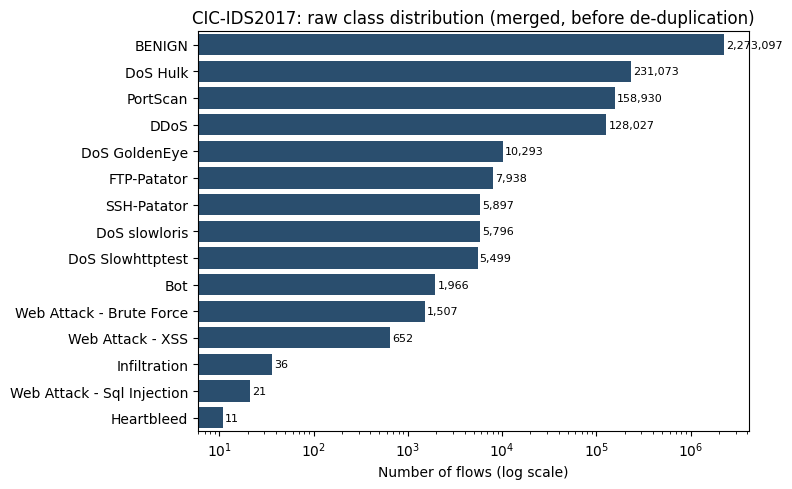

In [9]:
cnt = df['Label'].value_counts()
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=cnt.values, y=cnt.index, color='#1f4e79')
ax.set_xscale('log')
for p, v in zip(ax.patches, cnt.values):
    ax.text(v * 1.05, p.get_y() + p.get_height() / 2, f"{v:,}", va='center', fontsize=8)
ax.set_xlabel('Number of flows (log scale)'); ax.set_ylabel('')
ax.set_title('CIC-IDS2017: raw class distribution (merged, before de-duplication)')
plt.tight_layout(); save_fig('fig_class_distribution_raw'); plt.show()
RESULTS['raw_class_counts'] = {k: int(v) for k, v in cnt.items()}

In [10]:
before = df.shape[0]
df = df.drop_duplicates(subset=df.columns.drop('SourceDay')).reset_index(drop=True)
print(f"Duplicate rows removed: {before - df.shape[0]}  ({(before-df.shape[0])/before*100:.2f}% of data)")

Duplicate rows removed: 331200  (11.70% of data)


In [11]:
invalid_time_cols = ['Flow Duration', 'Flow IAT Mean', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Min', 'Flow Bytes/s', 'Flow Packets/s']
before = df.shape[0]
mask_invalid = (df[invalid_time_cols] < 0).any(axis=1)
print(f"Structurally invalid rows (negative time/rate values): {mask_invalid.sum()} ({mask_invalid.mean()*100:.3f}%)")
df = df.loc[~mask_invalid].reset_index(drop=True)
print("Shape after cleaning:", df.shape)

Structurally invalid rows (negative time/rate values): 2881 (0.115%)
Shape after cleaning: (2496662, 79)


## 5. Outlier Pipeline
*(Family 3: IQR, Z-score, Isolation Forest)*

In [12]:
def iqr_outlier_count(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return ((s < lo) | (s > hi)).sum()

report_cols = ['Flow Duration', 'Flow Bytes/s', 'Total Fwd Packets', 'Fwd Packet Length Mean']
iqr_report = {c: iqr_outlier_count(df[c]) for c in report_cols}
print("IQR outlier counts (diagnostic):", iqr_report)

IQR outlier counts (diagnostic): {'Flow Duration': np.int64(465934), 'Flow Bytes/s': np.int64(476246), 'Total Fwd Packets': np.int64(250866), 'Fwd Packet Length Mean': np.int64(177074)}


In [13]:
z_scores = np.abs(stats.zscore(df[report_cols]))
z_outlier_pct = (z_scores > 3).mean(axis=0) * 100
print("Z-score (>3) outlier % per feature:")
print(pd.Series(z_outlier_pct, index=report_cols))

Z-score (>3) outlier % per feature:
Flow Duration             0.000000
Flow Bytes/s              0.182484
Total Fwd Packets         0.105421
Fwd Packet Length Mean    1.329335
dtype: float64


In [14]:
benign_mask = df['Label'] == 'BENIGN'
iso = IsolationForest(contamination=0.01, random_state=RANDOM_STATE, n_jobs=-1)
iso_pred = iso.fit_predict(df.loc[benign_mask, num_cols_raw])
benign_idx = df.loc[benign_mask].index
noisy_benign_idx = benign_idx[iso_pred == -1]

print(f"Flagged {len(noisy_benign_idx)} noisy/likely-mislabeled BENIGN rows "
      f"({len(noisy_benign_idx)/benign_mask.sum()*100:.2f}% of BENIGN)")

df = df.drop(index=noisy_benign_idx).reset_index(drop=True)
print("Shape after outlier handling:", df.shape)

Flagged 20705 noisy/likely-mislabeled BENIGN rows (1.00% of BENIGN)
Shape after outlier handling: (2475957, 79)


### 5.4 Statistical Analysis
*(Family 12: t-test, ANOVA, chi-square, Mann-Whitney, p-value, CI, effect size)*

In [15]:
df['Binary_Label'] = (df['Label'] != 'BENIGN').astype(int)

key_features = ['Flow Duration', 'Flow Bytes/s', 'Fwd Packet Length Mean',
                 'Bwd Packet Length Mean', 'Flow IAT Mean']

benign_grp = df.loc[df['Binary_Label']==0]
attack_grp = df.loc[df['Binary_Label']==1]

rows = []
for c in key_features:
    t_stat, p_val = stats.ttest_ind(benign_grp[c], attack_grp[c], equal_var=False, nan_policy='omit')
    u_stat, p_mw  = stats.mannwhitneyu(benign_grp[c], attack_grp[c], alternative='two-sided')
    pooled_std = np.sqrt((benign_grp[c].std()**2 + attack_grp[c].std()**2) / 2)
    cohens_d = (attack_grp[c].mean() - benign_grp[c].mean()) / (pooled_std + 1e-9)
    rows.append([c, t_stat, p_val, p_mw, cohens_d])

stat_table = pd.DataFrame(rows, columns=['Feature', 't_stat', 'p_value(t-test)', 'p_value(Mann-Whitney)', "Cohen's d"])
stat_table

,Feature,t_stat,p_value(t-test),p_value(Mann-Whitney),Cohen's d
0,Flow Duration,-375.631042,0.0,0.0,0.704802
1,Flow Bytes/s,74.519051,0.0,0.0,-0.075965
2,Fwd Packet Length Mean,195.980270,0.0,0.0,-0.234297
3,Bwd Packet Length Mean,-619.611633,0.0,0.0,1.308349
4,Flow IAT Mean,-289.609924,0.0,0.0,0.542607


In [16]:
groups = [g['Flow Duration'].values for _, g in df.groupby('Label') if len(g) > 5]
f_stat, p_anova = stats.f_oneway(*groups)
print(f"ANOVA (Flow Duration across attack types): F={f_stat:.2f}, p={p_anova:.4e}")

df['Is_WellKnown_Port'] = (df['Destination Port'] <= 1023).astype(int)
ct = pd.crosstab(df['Is_WellKnown_Port'], df['Binary_Label'])
chi2, p_chi2, dof, exp = stats.chi2_contingency(ct)
print(f"Chi-square (WellKnownPort vs Attack): chi2={chi2:.2f}, p={p_chi2:.4e}")

ANOVA (Flow Duration across attack types): F=55640.41, p=0.0000e+00
Chi-square (WellKnownPort vs Attack): chi2=3378.89, p=0.0000e+00


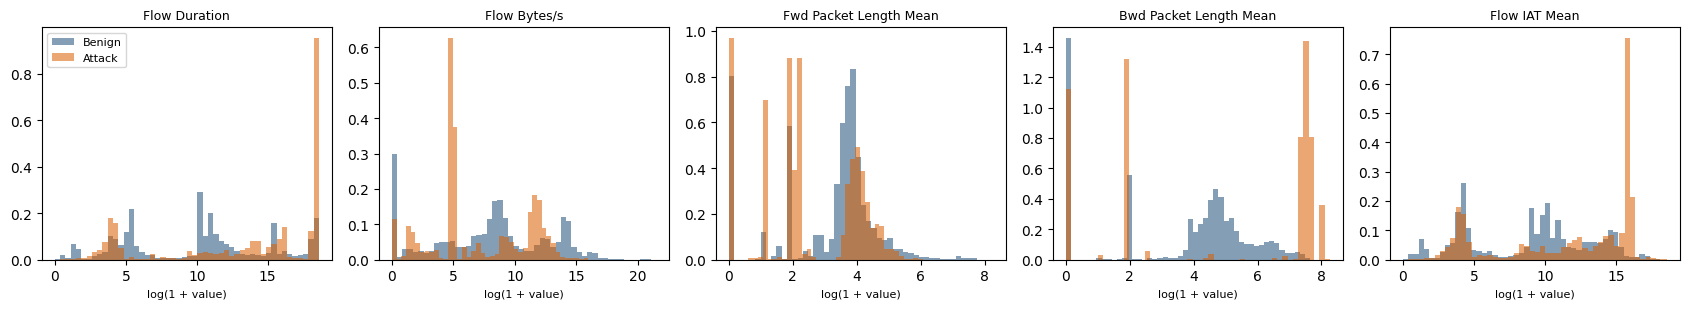

In [17]:
smp = df.sample(min(100_000, len(df)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, len(key_features), figsize=(3.4 * len(key_features), 3.2))
for ax, c in zip(axes, key_features):
    for lab, name, col in [(0, 'Benign', '#1f4e79'), (1, 'Attack', '#d95f02')]:
        v = np.log1p(smp.loc[smp['Binary_Label'] == lab, c].clip(lower=0))
        ax.hist(v, bins=50, alpha=0.55, density=True, label=name, color=col)
    ax.set_title(c, fontsize=9); ax.set_xlabel('log(1 + value)', fontsize=8)
axes[0].legend(fontsize=8)
plt.tight_layout(); save_fig('fig_key_feature_distributions'); plt.show()

## 6. Feature Engineering Pipeline
*(Family 9: Aggregation, interaction, temporal features)*

In [18]:
df['Fwd_Bwd_Pkt_Ratio']   = df['Total Fwd Packets'] / (df['Total Backward Packets'] + 1)
df['Bytes_per_Packet']    = (df['Total Length of Fwd Packets'] + df['Total Length of Bwd Packets']) / \
                             (df['Total Fwd Packets'] + df['Total Backward Packets'] + 1)
df['Fwd_Bwd_Byte_Ratio']  = df['Total Length of Fwd Packets'] / (df['Total Length of Bwd Packets'] + 1)
df['Flag_Sum']            = df[['FIN Flag Count','SYN Flag Count','RST Flag Count', 'PSH Flag Count','ACK Flag Count','URG Flag Count']].sum(axis=1)

new_feats = ['Fwd_Bwd_Pkt_Ratio','Bytes_per_Packet','Fwd_Bwd_Byte_Ratio','Flag_Sum']
print("New engineered features:", new_feats)
df[new_feats].describe()

New engineered features: ['Fwd_Bwd_Pkt_Ratio', 'Bytes_per_Packet', 'Fwd_Bwd_Byte_Ratio', 'Flag_Sum']


,Fwd_Bwd_Pkt_Ratio,Bytes_per_Packet,Fwd_Bwd_Byte_Ratio,Flag_Sum
count,2.475957e+06,2.475957e+06,2.475957e+06,2.475957e+06
mean,1.160036e+00,1.802360e+02,3.550948e+01,7.904927e-01
std,4.216003e+00,3.142759e+02,8.455242e+02,6.891134e-01
min,6.369427e-03,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.000000e-01,4.500000e+00,5.708865e-02,0.000000e+00
50%,6.666667e-01,5.333333e+01,3.460560e-01,1.000000e+00
75%,1.200000e+00,1.424375e+02,7.542857e-01,1.000000e+00
max,7.410000e+02,3.337143e+03,2.189280e+05,3.000000e+00


## 7. Encoding Pipeline
*(Family 8: One-hot, ordinal, target encoding)*

In [19]:
le = LabelEncoder()
df['Label_enc'] = le.fit_transform(df['Label'])
label_map = dict(zip(le.classes_, le.transform(le.classes_)))
print(label_map)

sourceday_ohe = pd.get_dummies(df['SourceDay'], prefix='Day')
print("One-hot day columns:", sourceday_ohe.columns.tolist())


{'BENIGN': np.int64(0), 'Bot': np.int64(1), 'DDoS': np.int64(2), 'DoS GoldenEye': np.int64(3), 'DoS Hulk': np.int64(4), 'DoS Slowhttptest': np.int64(5), 'DoS slowloris': np.int64(6), 'FTP-Patator': np.int64(7), 'Heartbleed': np.int64(8), 'Infiltration': np.int64(9), 'PortScan': np.int64(10), 'SSH-Patator': np.int64(11), 'Web Attack - Brute Force': np.int64(12), 'Web Attack - Sql Injection': np.int64(13), 'Web Attack - XSS': np.int64(14)}
One-hot day columns: ['Day_Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', 'Day_Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv', 'Day_Friday-WorkingHours-Morning.pcap_ISCX.csv', 'Day_Monday-WorkingHours.pcap_ISCX.csv', 'Day_Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv', 'Day_Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv', 'Day_Tuesday-WorkingHours.pcap_ISCX.csv', 'Day_Wednesday-workingHours.pcap_ISCX.csv']


## 8. Transformation Pipeline
*(Family 6: Log, Box-Cox, Yeo-Johnson)*

In [20]:
feature_cols = [c for c in df.columns if c not in ['Label', 'Label_enc', 'Binary_Label', 'SourceDay']]

skewness = df[feature_cols].skew().sort_values(ascending=False)
print("Top 10 most skewed features:")
print(skewness.head(10))
log_candidates = [c for c in feature_cols if (df[c] >= 0).all() and df[c].skew() > 2]
print(f"\n{len(log_candidates)} features selected for log1p transform")
df_transformed = df.copy()
df_transformed[log_candidates] = np.log1p(df_transformed[log_candidates])
print("Skew after log1p (same features):")
print(df_transformed[log_candidates].skew().sort_values(ascending=False).head(10))

Top 10 most skewed features:
Total Length of Fwd Packets    364.269928
Subflow Fwd Bytes              364.269928
act_data_pkt_fwd               237.810135
Fwd URG Flags                  175.916168
CWE Flag Count                 175.916168
Subflow Bwd Bytes              155.976379
Total Length of Bwd Packets    155.976379
Total Fwd Packets              117.587791
Subflow Fwd Packets            117.587791
Total Backward Packets          84.037811
dtype: float64

64 features selected for log1p transform
Skew after log1p (same features):
Fwd URG Flags        175.916168
CWE Flag Count       175.916168
RST Flag Count        60.539978
ECE Flag Count        60.405781
FIN Flag Count         5.258176
Fwd PSH Flags          4.206144
SYN Flag Count         4.206144
Idle Std               3.275165
Active Std             3.252151
Fwd_Bwd_Pkt_Ratio      3.001487
dtype: float32


## 9. (Preview) Feature Selection Pipeline
*(Family 10: MI, RFE, LASSO, statistical tests)*

In [21]:
def select_features_mutual_info(X_train, y_train, k=25):
    mi = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
    return pd.Series(mi, index=X_train.columns).sort_values(ascending=False).head(k).index.tolist()

def select_features_rfe(X_train, y_train, n_features=25):
    estimator = LogisticRegression(max_iter=200, n_jobs=-1)
    rfe = RFE(estimator, n_features_to_select=n_features, step=5)
    rfe.fit(X_train, y_train)
    return X_train.columns[rfe.support_].tolist()

def select_features_lasso(X_train, y_train, alpha=0.001):
    lasso = Lasso(alpha=alpha, random_state=RANDOM_STATE, max_iter=5000)
    lasso.fit(X_train, y_train)
    coefs = pd.Series(lasso.coef_, index=X_train.columns)
    return coefs[coefs != 0].index.tolist()

print("Feature selection functions ready (applied in Section 10).")

Feature selection functions ready (applied in Section 10).


#### 10. Train/Test Strategy + Scaling + Feature Selection (leakage-safe, all together)

In [22]:
X = df_transformed[feature_cols]
y = df_transformed['Label_enc']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Stratified split:", X_train.shape, X_test.shape)

Stratified split: (1980765, 82) (495192, 82)


In [23]:
imputer_final = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer_final.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test  = pd.DataFrame(imputer_final.transform(X_test),  columns=X_test.columns,  index=X_test.index)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)
print("Scaling done (fit on train only).")

Scaling done (fit on train only).


In [24]:
selected_features = select_features_mutual_info(X_train_scaled, y_train, k=30)
print(f"Selected {len(selected_features)} features via Mutual Information:")
print(selected_features)

X_train_fs = X_train_scaled[selected_features]
X_test_fs  = X_test_scaled[selected_features]

Selected 30 features via Mutual Information:
['Bytes_per_Packet', 'Average Packet Size', 'Fwd_Bwd_Byte_Ratio', 'Packet Length Std', 'Packet Length Variance', 'Packet Length Mean', 'Total Length of Bwd Packets', 'Subflow Bwd Bytes', 'Avg Bwd Segment Size', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Init_Win_bytes_backward', 'Bwd Packet Length Max', 'Total Length of Fwd Packets', 'Subflow Fwd Bytes', 'Fwd IAT Max', 'Max Packet Length', 'Init_Win_bytes_forward', 'Fwd Packet Length Std', 'Fwd IAT Total', 'Fwd IAT Std', 'Fwd Packet Length Max', 'Fwd IAT Mean', 'Flow IAT Max', 'Flow Duration', 'Destination Port', 'Avg Fwd Segment Size', 'Fwd Packet Length Mean', 'Flow Bytes/s', 'Flow IAT Std']


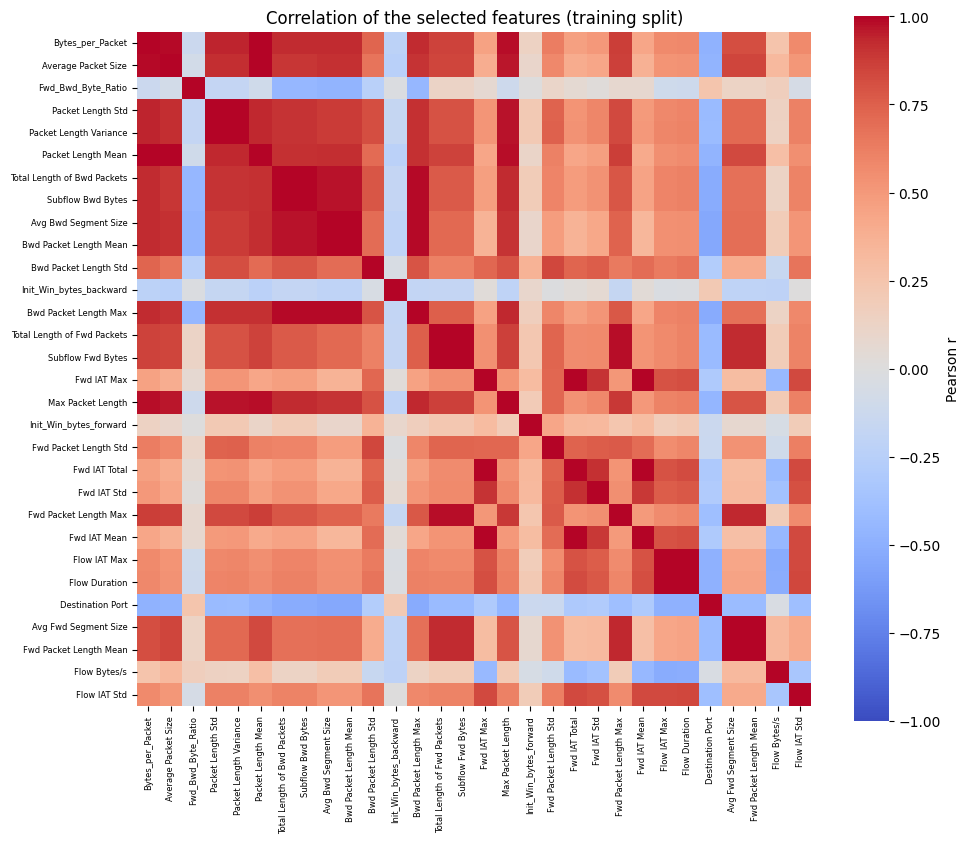

In [25]:
corr = X_train_fs.sample(min(200_000, len(X_train_fs)), random_state=RANDOM_STATE).corr()
plt.figure(figsize=(10, 8.5))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, square=True, cbar_kws={'label': 'Pearson r'},
            xticklabels=True, yticklabels=True)
plt.xticks(fontsize=6, rotation=90); plt.yticks(fontsize=6)
plt.title('Correlation of the selected features (training split)')
plt.tight_layout(); save_fig('fig_selected_feature_correlation'); plt.show()
RESULTS['selected_features'] = list(selected_features)

### 6.2 Chronological (per-class) validation — alternative split, for the robustness section of the paper

v1 tried to train on Monday–Thursday and test on Friday. That design cannot work for this dataset: PortScan, DDoS and Bot
exist **only** on Friday, so they would be absent from training, and the file-name patterns did not match, so both splits were empty.
v2 uses a *per-class chronological split*: inside every class the flows are ordered by (weekday, original row order) and the
first 80 % are used for training and the last 20 % for testing. This tests generalisation to later traffic of the same class
and removes the near-duplicate neighbours that a random split puts on both sides.
(Assumption: row order inside each CSV approximates capture time; the MachineLearningCSV release has no timestamp column.)


In [26]:

weekday_order = ['Monday-WorkingHours.pcap_ISCX.csv',
                 'Tuesday-WorkingHours.pcap_ISCX.csv',
                 'Wednesday-workingHours.pcap_ISCX.csv',
                 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv',
                 'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv',
                 'Friday-WorkingHours-Morning.pcap_ISCX.csv',
                 'Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv',
                 'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv']
missing_files = set(df_transformed['SourceDay'].unique()) - set(weekday_order)
assert not missing_files, f"Unexpected SourceDay values: {missing_files}"

day_rank = {f: i for i, f in enumerate(weekday_order)}
order_key = pd.DataFrame({'rank': df_transformed['SourceDay'].map(day_rank).values,
                          'pos': np.arange(len(df_transformed))}, index=df_transformed.index)

chrono_test_idx = []
for cls, grp in order_key.groupby(df_transformed['Label_enc']):
    g = grp.sort_values(['rank', 'pos'])
    n_test = max(1, int(round(0.2 * len(g))))
    chrono_test_idx.extend(g.index[-n_test:])          

test_mask  = df_transformed.index.isin(chrono_test_idx)
train_mask = ~test_mask

X_train_time, y_train_time = X.loc[train_mask], y.loc[train_mask]
X_test_time,  y_test_time  = X.loc[test_mask],  y.loc[test_mask]
print("Chronological split -> train:", X_train_time.shape, "test:", X_test_time.shape)
print("Classes in train:", y_train_time.nunique(), "| classes in test:", y_test_time.nunique())


Chronological split -> train: (1980767, 82) test: (495190, 82)
Classes in train: 15 | classes in test: 15


## 11. Sampling + Imbalance Pipeline
*(Family 4 & 5: Under/over/stratified sampling; SMOTE, ADASYN, class weights)*

In [27]:
from collections import Counter
print("Class distribution in TRAIN before balancing:")
print(pd.Series(y_train).value_counts().sort_index())

Class distribution in TRAIN before balancing:
Label_enc
0     1640229
1        1562
2      102397
3        8222
4      138153
5        4182
6        4299
7        4743
8           6
9          28
10      72655
11       2574
12       1176
13         17
14        522
Name: count, dtype: int64


In [28]:

from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN


SMOTE_TARGET    = 10_000
MIN_SMOTE_REAL  = 50
TINY_WEIGHT_CAP = 50.0

def resample_train(X_tr, y_tr, seed=RANDOM_STATE):
    """Apply the v2 resampling policy to a TRAINING partition. Returns X_bal, y_bal, sample_weight, plan, tiny."""
    counts = Counter(np.asarray(y_tr).tolist())
    plan = {c: SMOTE_TARGET for c, n in counts.items() if MIN_SMOTE_REAL <= n < SMOTE_TARGET}
    tiny = {c: n for c, n in counts.items() if n < MIN_SMOTE_REAL}
    if plan:
        X_b, y_b = SMOTE(sampling_strategy=plan, random_state=seed, k_neighbors=5).fit_resample(X_tr, y_tr)
    else:
        X_b, y_b = X_tr, y_tr
    tiny_w = {c: min(TINY_WEIGHT_CAP, SMOTE_TARGET / n) for c, n in tiny.items()}
    w = pd.Series(np.asarray(y_b)).map(tiny_w).fillna(1.0).to_numpy()
    return X_b, y_b, w, plan, tiny

def stratified_fraction(y, frac, seed=RANDOM_STATE, min_per_class=5):
    """Row positions of a stratified subsample that keeps >= min_per_class rows of every class."""
    rs = np.random.RandomState(seed)
    y = np.asarray(y)
    keep = []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        n = min(len(idx), max(min(len(idx), min_per_class), int(np.ceil(frac * len(idx)))))
        keep.extend(rs.choice(idx, n, replace=False))
    return np.array(sorted(keep))

X_train_bal, y_train_bal, w_bal, smote_plan, tiny_classes = resample_train(X_train_fs, y_train)
print(f"SMOTE plan (class -> target size): {smote_plan}")
inv_label_map = {v: k for k, v in label_map.items()}
print("Tiny classes (no synthetic data, capped weights):", {inv_label_map[c]: n for c, n in tiny_classes.items()})
print("Class distribution AFTER resampling (train only):")
print(pd.Series(y_train_bal).value_counts().sort_index())
print("Training rows:", len(y_train_bal), "(v1: 24,603,435)")


SMOTE plan (class -> target size): {7: 10000, 3: 10000, 1: 10000, 5: 10000, 6: 10000, 11: 10000, 14: 10000, 12: 10000}
Tiny classes (no synthetic data, capped weights): {'Heartbleed': 6, 'Web Attack - Sql Injection': 17, 'Infiltration': 28}
Class distribution AFTER resampling (train only):
Label_enc
0     1640229
1       10000
2      102397
3       10000
4      138153
5       10000
6       10000
7       10000
8           6
9          28
10      72655
11      10000
12      10000
13         17
14      10000
Name: count, dtype: int64
Training rows: 2033485 (v1: 24,603,435)


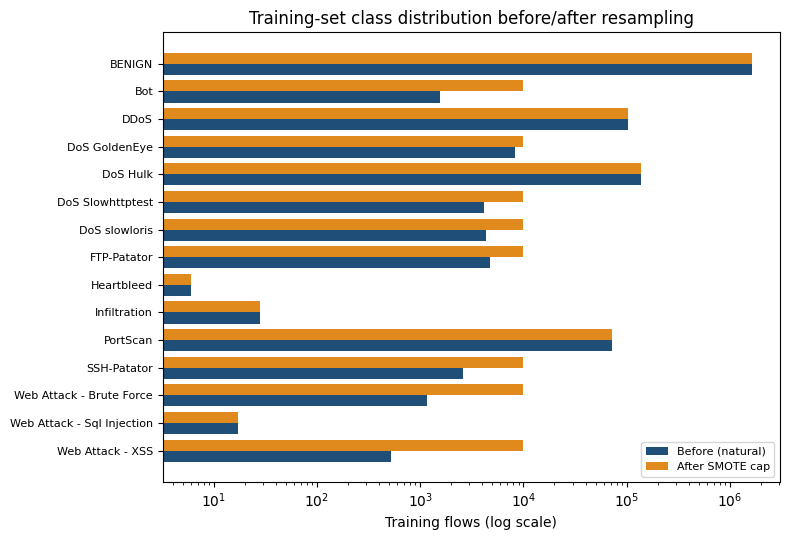

In [29]:
before = pd.Series(y_train).value_counts().sort_index()
after  = pd.Series(y_train_bal).value_counts().sort_index()
tn = [inv_label_map[i] for i in before.index]
ypos = np.arange(len(tn))
plt.figure(figsize=(8, 5.5))
plt.barh(ypos + 0.2, before.values, 0.4, label='Before (natural)', color='#1f4e79')
plt.barh(ypos - 0.2, after.reindex(before.index).values, 0.4, label='After SMOTE cap', color='#e08a1e')
plt.yticks(ypos, tn, fontsize=8); plt.gca().invert_yaxis(); plt.xscale('log')
plt.xlabel('Training flows (log scale)'); plt.legend(fontsize=8)
plt.title('Training-set class distribution before/after resampling')
plt.tight_layout(); save_fig('fig_class_distribution_resampling'); plt.show()
RESULTS['train_rows_before'] = int(len(y_train)); RESULTS['train_rows_after_resampling'] = int(len(y_train_bal))

In [30]:
from sklearn.utils.class_weight import compute_class_weight
classes_ = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes_, y=y_train)
class_weight_dict = dict(zip(classes_, weights))
print("Balanced class weights (alternative to SMOTE):")
print(class_weight_dict)

Balanced class weights (alternative to SMOTE):
{np.int64(0): np.float64(0.08050766082053176), np.int64(1): np.float64(84.53969270166453), np.int64(2): np.float64(1.289598328076018), np.int64(3): np.float64(16.060690829481878), np.int64(4): np.float64(0.9558315780330503), np.int64(5): np.float64(31.576040172166426), np.int64(6): np.float64(30.71667829727844), np.int64(7): np.float64(27.84123972169513), np.int64(8): np.float64(22008.5), np.int64(9): np.float64(4716.107142857143), np.int64(10): np.float64(1.8175073979767393), np.int64(11): np.float64(51.3018648018648), np.int64(12): np.float64(112.28826530612245), np.int64(13): np.float64(7767.705882352941), np.int64(14): np.float64(252.9712643678161)}


## 12. Simulation / Augmentation Pipeline
*(Family 11: Monte Carlo, GAN, VAE, diffusion)*


In [31]:
'''
from ctgan import CTGAN

rare_classes = [8, 9, 13]  # Heartbleed, Infiltration, Web Attack-SQLi (see label_map above)
for cls in rare_classes:
    cls_data = X_train_fs[y_train == cls]
    ctgan = CTGAN(epochs=300)
    ctgan.fit(cls_data)
    synthetic = ctgan.sample(200)
    # concat synthetic samples with X_train_bal / y_train_bal for that class
'''
print("GAN augmentation stub ready - optional extension for ultra-rare classes.")

GAN augmentation stub ready - optional extension for ultra-rare classes.


## 13. Model Training

In [32]:
import xgboost as xgb

model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=len(label_map),
    eval_metric='mlogloss',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method='hist'
)

model.fit(X_train_bal, y_train_bal, sample_weight=w_bal)
print("Training done.")

Training done.


## 14. Evaluation

In [33]:
y_pred = model.predict(X_test_fs)
y_proba = model.predict_proba(X_test_fs)

inv_label_map = {v: k for k, v in label_map.items()}
target_names = [inv_label_map[i] for i in sorted(inv_label_map)]

print(classification_report(y_test, y_pred, target_names=target_names, digits=4, zero_division=0))

                            precision    recall  f1-score   support

                    BENIGN     0.9998    0.9985    0.9992    410058
                       Bot     0.6966    0.9514    0.8043       391
                      DDoS     0.9998    0.9996    0.9997     25600
             DoS GoldenEye     0.9966    0.9985    0.9976      2055
                  DoS Hulk     0.9978    0.9990    0.9984     34538
          DoS Slowhttptest     0.9923    0.9904    0.9914      1046
             DoS slowloris     0.9944    0.9926    0.9935      1075
               FTP-Patator     1.0000    0.9992    0.9996      1186
                Heartbleed     0.5000    1.0000    0.6667         1
              Infiltration     1.0000    0.5714    0.7273         7
                  PortScan     0.9903    0.9996    0.9949     18164
               SSH-Patator     1.0000    1.0000    1.0000       643
  Web Attack - Brute Force     0.5779    0.6054    0.5914       294
Web Attack - Sql Injection     1.0000    0.2500

### 14.1 Overfitting / Underfitting Check

In [34]:

from sklearn.metrics import accuracy_score, f1_score

train_pred = model.predict(X_train_fs)
train_acc = accuracy_score(y_train, train_pred)
train_f1  = f1_score(y_train, train_pred, average='macro')

test_acc = accuracy_score(y_test, y_pred)
test_f1  = f1_score(y_test, y_pred, average='macro')

print(f"Train Accuracy: {train_acc:.4f}   |   Test Accuracy: {test_acc:.4f}   |   Gap: {train_acc-test_acc:.4f}")
print(f"Train Macro-F1: {train_f1:.4f}   |   Test Macro-F1: {test_f1:.4f}   |   Gap: {train_f1-test_f1:.4f}")
print()
print("Rule of thumb: gap > 0.05-0.10 -> investigate overfitting. Both numbers are on natural (imbalanced) data.")
RESULTS['train_test_gap'] = dict(train_acc=float(train_acc), test_acc=float(test_acc), train_macro_f1=float(train_f1), test_macro_f1=float(test_f1))


Train Accuracy: 0.9984   |   Test Accuracy: 0.9982   |   Gap: 0.0002
Train Macro-F1: 0.9238   |   Test Macro-F1: 0.8336   |   Gap: 0.0902

Rule of thumb: gap > 0.05-0.10 -> investigate overfitting. Both numbers are on natural (imbalanced) data.


In [35]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_model = xgb.XGBClassifier(**model.get_params())

cv_scores = cross_val_score(cv_model, X_train_fs, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
print("5-fold CV Macro-F1 scores:", np.round(cv_scores, 4))
print(f"Mean: {cv_scores.mean():.4f}  |  Std: {cv_scores.std():.4f}")
print()
print("Small std (e.g. < 0.02) across folds -> stable model, not just lucky on one split.")
print("If CV mean is much lower than the single test_f1 above -> the single split was optimistic; report the CV mean instead.")

5-fold CV Macro-F1 scores: [0.8764 0.8981 0.8456 0.8681 0.8623]
Mean: 0.8701  |  Std: 0.0173

Small std (e.g. < 0.02) across folds -> stable model, not just lucky on one split.
If CV mean is much lower than the single test_f1 above -> the single split was optimistic; report the CV mean instead.


fraction 0.10: n_train=  168,380  train macro-F1=0.9575  validation macro-F1=0.8350
fraction 0.25: n_train=  420,922  train macro-F1=0.9501  validation macro-F1=0.8417
fraction 0.50: n_train=  841,830  train macro-F1=0.9332  validation macro-F1=0.8729
fraction 0.75: n_train=1,262,743  train macro-F1=0.9279  validation macro-F1=0.8778
fraction 1.00: n_train=1,683,650  train macro-F1=0.9232  validation macro-F1=0.8742


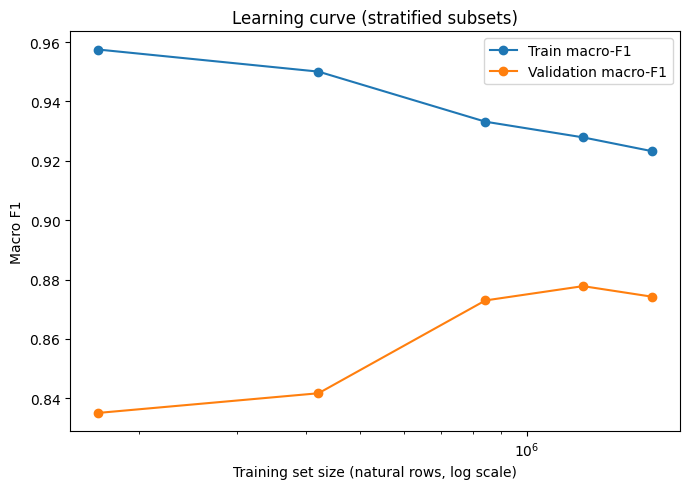

Interpretation:
 - Curves converging close together, both HIGH  -> good fit
 - Big persistent gap (train high, val low)      -> overfitting (try: lower max_depth, more regularization, fewer features)
 - Both curves LOW and flat                       -> underfitting (try: more features, higher max_depth, more estimators)


In [36]:
X_lc_tr, X_lc_val, y_lc_tr, y_lc_val = train_test_split(X_train_fs, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)
fracs = [0.1, 0.25, 0.5, 0.75, 1.0]
lc_rows = []
for fr in fracs:
    pos = stratified_fraction(y_lc_tr, fr)
    Xs, ys = X_lc_tr.iloc[pos], y_lc_tr.iloc[pos]
    Xb, yb, wb, _, _ = resample_train(Xs, ys)
    m = xgb.XGBClassifier(**model.get_params())
    m.fit(Xb, yb, sample_weight=wb)
    f_tr  = f1_score(ys, m.predict(Xs), average='macro')
    f_val = f1_score(y_lc_val, m.predict(X_lc_val), average='macro')
    lc_rows.append((len(ys), f_tr, f_val))
    print(f"fraction {fr:.2f}: n_train={len(ys):>9,}  train macro-F1={f_tr:.4f}  validation macro-F1={f_val:.4f}")
lc = pd.DataFrame(lc_rows, columns=['n_train', 'train_f1', 'val_f1'])

plt.figure(figsize=(7, 5))
plt.plot(lc['n_train'], lc['train_f1'], 'o-', label='Train macro-F1')
plt.plot(lc['n_train'], lc['val_f1'], 'o-', label='Validation macro-F1')
plt.xscale('log'); plt.xlabel('Training set size (natural rows, log scale)'); plt.ylabel('Macro F1')
plt.title('Learning curve (stratified subsets)')
plt.legend(); plt.tight_layout(); save_fig('fig_learning_curve'); plt.show()
lc.to_csv(os.path.join(FIG_DIR, 'learning_curve.csv'), index=False)
RESULTS['learning_curve'] = lc.to_dict(orient='list')

print("Interpretation:")
print(" - Curves converging close together, both HIGH  -> good fit")
print(" - Big persistent gap (train high, val low)      -> overfitting (try: lower max_depth, more regularization, fewer features)")
print(" - Both curves LOW and flat                       -> underfitting (try: more features, higher max_depth, more estimators)")


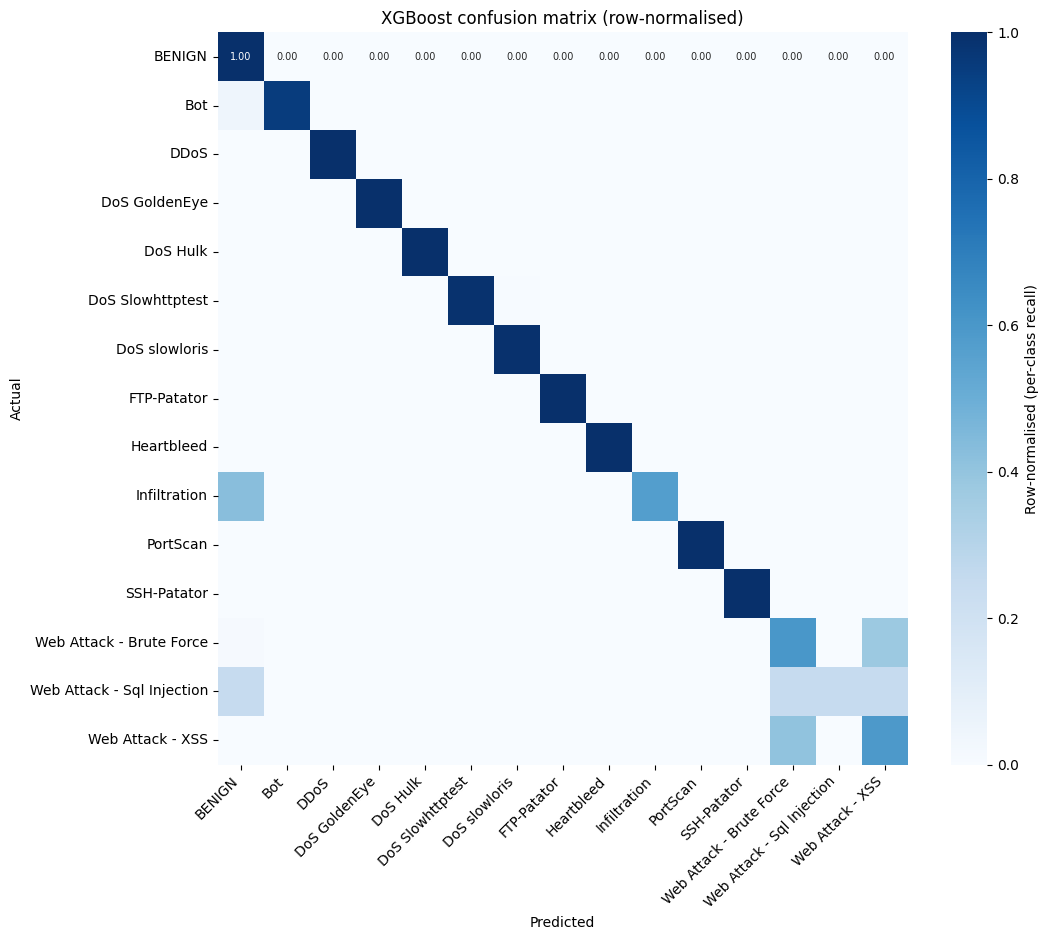

BENIGN flows misclassified: 619 of 410058
BENIGN                      409439
Bot                            162
DDoS                             3
DoS Hulk                        64
DoS Slowhttptest                 4
DoS slowloris                    1
Heartbleed                       1
PortScan                       178
Web Attack - Brute Force        75
Web Attack - XSS               131


In [37]:

# v2: v1 plotted raw counts, so the 410k BENIGN cell hid every other cell. Row-normalised (recall) matrix + counts CSV.
cm = confusion_matrix(y_test, y_pred, labels=list(range(len(target_names))))
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(11, 9.5))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, xticklabels=target_names, yticklabels=target_names,
            ax=ax, annot_kws={'size': 7}, cbar_kws={'label': 'Row-normalised (per-class recall)'})
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('XGBoost confusion matrix (row-normalised)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout(); save_fig('fig_confusion_matrix_xgb'); plt.show()
pd.DataFrame(cm, index=target_names, columns=target_names).to_csv(os.path.join(FIG_DIR, 'confusion_matrix_counts_xgb.csv'))
benign_row = pd.Series(cm[label_map['BENIGN']], index=target_names)
print("BENIGN flows misclassified:", int(benign_row.sum() - benign_row['BENIGN']), "of", int(benign_row.sum()))
print(benign_row[benign_row > 0].to_string())


In [38]:
# Macro ROC-AUC (one-vs-rest, multiclass)
try:
    macro_auc = roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro')
    print(f"Macro ROC-AUC (OvR): {macro_auc:.4f}")
except Exception as e:
    print("ROC-AUC computation note:", e)

Macro ROC-AUC (OvR): 0.9996


### 14.2 Binary view (Benign vs Attack) — the most comparable number in the IDS literature

Binary (Benign vs Attack) XGBoost: {'accuracy': 0.998613, 'precision': 0.992776, 'recall': 0.999201, 'f1': 0.995978, 'roc_auc': 0.999971, 'pr_auc': 0.999862, 'false_alarm_rate': 0.00151, 'miss_rate': 0.000799, 'TP': 85066, 'FP': 619, 'TN': 409439, 'FN': 68}


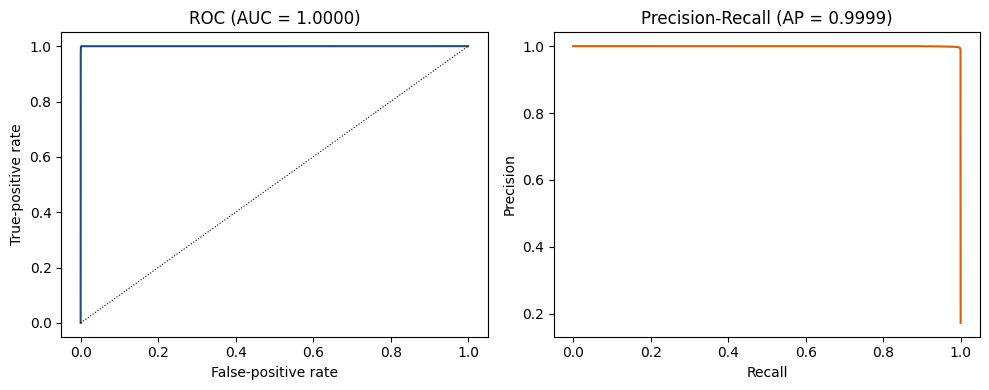

In [39]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, precision_score, recall_score

BEN = label_map['BENIGN']
y_test_bin = (np.asarray(y_test) != BEN).astype(int)
y_pred_bin = (np.asarray(y_pred) != BEN).astype(int)
p_attack   = 1.0 - y_proba[:, BEN]

tn_, fp_, fn_, tp_ = confusion_matrix(y_test_bin, y_pred_bin).ravel()
bin_metrics = dict(accuracy=float(accuracy_score(y_test_bin, y_pred_bin)),
                   precision=float(precision_score(y_test_bin, y_pred_bin)),
                   recall=float(recall_score(y_test_bin, y_pred_bin)),
                   f1=float(f1_score(y_test_bin, y_pred_bin)),
                   roc_auc=float(roc_auc_score(y_test_bin, p_attack)),
                   pr_auc=float(average_precision_score(y_test_bin, p_attack)),
                   false_alarm_rate=float(fp_ / (fp_ + tn_)), miss_rate=float(fn_ / (fn_ + tp_)),
                   TP=int(tp_), FP=int(fp_), TN=int(tn_), FN=int(fn_))
print("Binary (Benign vs Attack) XGBoost:", {k: round(v, 6) if isinstance(v, float) else v for k, v in bin_metrics.items()})
RESULTS['binary_xgb'] = bin_metrics

fpr, tpr, _ = roc_curve(y_test_bin, p_attack)
prec, rec, _ = precision_recall_curve(y_test_bin, p_attack)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(fpr, tpr, color='#1f4e79'); ax[0].plot([0, 1], [0, 1], 'k:', lw=0.8)
ax[0].set_xlabel('False-positive rate'); ax[0].set_ylabel('True-positive rate'); ax[0].set_title(f"ROC (AUC = {bin_metrics['roc_auc']:.4f})")
ax[1].plot(rec, prec, color='#d95f02'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
ax[1].set_title(f"Precision-Recall (AP = {bin_metrics['pr_auc']:.4f})")
plt.tight_layout(); save_fig('fig_binary_roc_pr'); plt.show()

## 15. Explainability Layer (SHAP) — the "X" in XThreat

এটাই আপনার original flow implement করে:
`Attack detected → Why? → Evidence → Important features → Attack behavior → Confidence → Recommended response`

In [40]:
import shap

explainer = shap.TreeExplainer(model)
sample_idx = np.random.RandomState(RANDOM_STATE).choice(X_test_fs.index, size=min(2000, len(X_test_fs)), replace=False)
X_shap_sample = X_test_fs.loc[sample_idx]

shap_values = explainer.shap_values(X_shap_sample)
print("SHAP values computed. Shape:", np.array(shap_values).shape)

SHAP values computed. Shape: (2000, 30, 15)


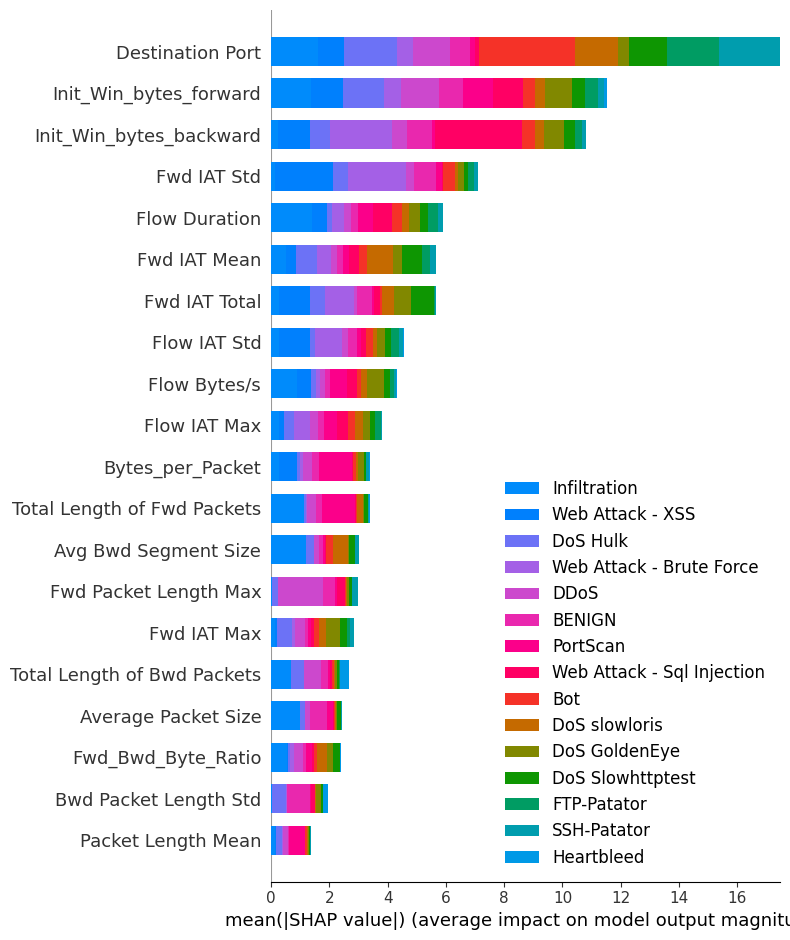

In [41]:

shap.summary_plot(shap_values, X_shap_sample, feature_names=selected_features,
                   class_names=target_names, plot_type='bar', show=False)
save_fig('fig_shap_global_stacked'); plt.show()


#### 15.1 Global importance of the *predicted* class (clearer than the stacked multi-class bar)

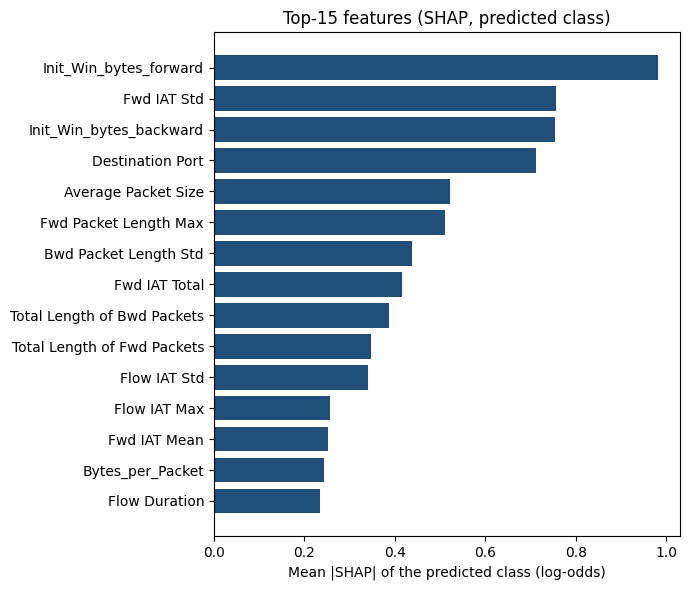

,Predicted class,n (sample),Top-1,Top-2,Top-3
0,BENIGN,1606,Init_Win_bytes_forward (0.99),Init_Win_bytes_backward (0.79),Destination Port (0.73)
1,Bot,2,Flow Bytes/s (2.62),Avg Bwd Segment Size (2.56),Flow Duration (2.28)
2,DDoS,114,Fwd Packet Length Max (1.98),Total Length of Bwd Packets (1.34),Total Length of Fwd Packets (1.04)
3,DoS GoldenEye,8,Total Length of Bwd Packets (5.19),Bwd Packet Length Std (2.93),Init_Win_bytes_forward (1.71)
4,DoS Hulk,164,Fwd IAT Std (2.01),Bwd Packet Length Std (1.79),Fwd IAT Mean (1.11)
5,DoS Slowhttptest,5,Max Packet Length (4.93),Flow IAT Std (4.68),Fwd IAT Mean (0.61)
6,DoS slowloris,6,Fwd_Bwd_Byte_Ratio (3.81),Flow Bytes/s (2.06),Flow IAT Std (1.94)
7,FTP-Patator,4,Destination Port (14.67),Avg Fwd Segment Size (0.97),Total Length of Bwd Packets (0.76)
8,PortScan,85,Total Length of Fwd Packets (2.44),Init_Win_bytes_forward (1.49),Average Packet Size (0.65)
9,SSH-Patator,2,Destination Port (11.92),Fwd Packet Length Max (2.48),Flow Bytes/s (1.63)


In [42]:
shap_arr = np.stack(shap_values, axis=-1) if isinstance(shap_values, list) else np.asarray(shap_values)   # (n, features, classes)
pred_cls_sample = model.predict(X_shap_sample)
pc_abs = np.array([np.abs(shap_arr[i, :, pred_cls_sample[i]]) for i in range(len(pred_cls_sample))])   # |SHAP| of the predicted class
imp_pc = pd.Series(pc_abs.mean(axis=0), index=selected_features).sort_values()

plt.figure(figsize=(7, 6))
plt.barh(imp_pc.tail(15).index, imp_pc.tail(15).values, color='#1f4e79')
plt.xlabel('Mean |SHAP| of the predicted class (log-odds)'); plt.title('Top-15 features (SHAP, predicted class)')
plt.tight_layout(); save_fig('fig_shap_global_predicted_class'); plt.show()
RESULTS['shap_global_top15'] = imp_pc.tail(15).iloc[::-1].to_dict()

# Per-class top-3 SHAP features (table for the paper)
rows = []
for c in np.unique(pred_cls_sample):
    m = pred_cls_sample == c
    s = pd.Series(pc_abs[m].mean(axis=0), index=selected_features).sort_values(ascending=False).head(3)
    rows.append([inv_label_map[c], int(m.sum())] + [f"{k} ({v:.2f})" for k, v in s.items()])
class_top_feats = pd.DataFrame(rows, columns=['Predicted class', 'n (sample)', 'Top-1', 'Top-2', 'Top-3'])
class_top_feats.to_csv(os.path.join(FIG_DIR, 'shap_top3_per_class.csv'), index=False)
class_top_feats

Explaining instance 1529854 — predicted class: FTP-Patator
Confidence: 1.0000


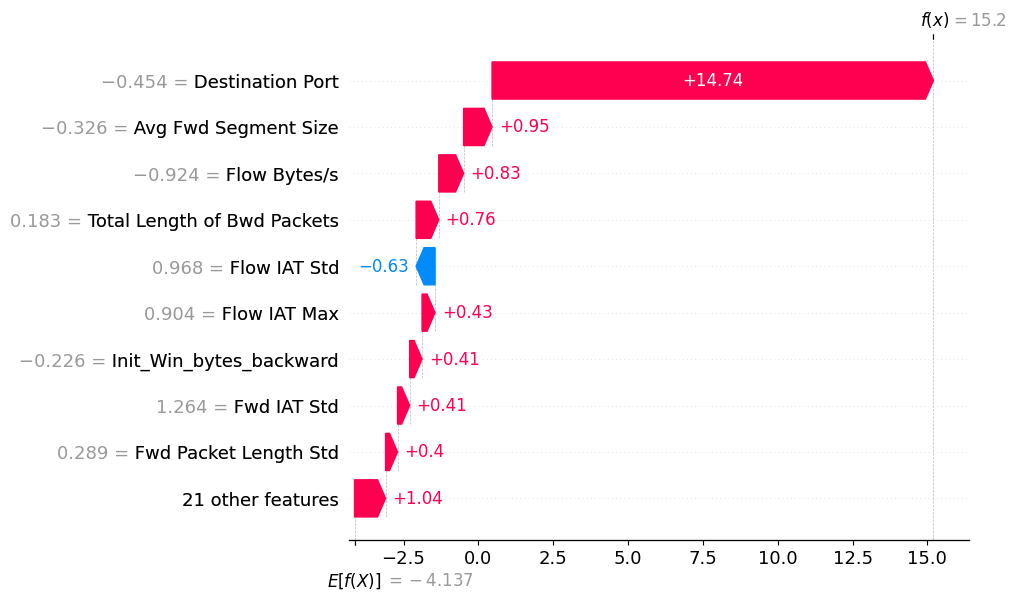

In [43]:
def get_class_shap_row(shap_values, row_pos, class_idx):
    if isinstance(shap_values, list):
        return shap_values[class_idx][row_pos]
    arr = np.asarray(shap_values)
    if arr.ndim == 3:
        return arr[row_pos, :, class_idx]
    return arr[row_pos]

def get_expected_value(explainer, class_idx):
    ev = explainer.expected_value
    if hasattr(ev, '__len__'):
        return ev[class_idx]
    return ev

brute_force_class = label_map.get('FTP-Patator', label_map.get('SSH-Patator'))
y_pred_sample = model.predict(X_shap_sample)
candidates = X_shap_sample.index[y_pred_sample == brute_force_class]

if len(candidates) > 0:
    idx = candidates[0]
    pos = X_shap_sample.index.get_loc(idx)
    print(f"Explaining instance {idx} — predicted class: {inv_label_map[model.predict(X_shap_sample.loc[[idx]])[0]]}")
    print(f"Confidence: {model.predict_proba(X_shap_sample.loc[[idx]]).max():.4f}")

    sv_row = get_class_shap_row(shap_values, pos, brute_force_class)
    ev = get_expected_value(explainer, brute_force_class)

    # v2: waterfall instead of the force plot (the force-plot feature labels overlapped and were unreadable)
    expl = shap.Explanation(values=sv_row, base_values=ev, data=X_shap_sample.loc[idx].values, feature_names=list(selected_features))
    shap.plots.waterfall(expl, max_display=10, show=False)
    save_fig('fig_shap_waterfall_' + inv_label_map[brute_force_class].replace(' ', '_'))
    plt.show()
else:
    print("No Brute-Force prediction in this sample — try a larger sample_idx or a different class.")

## 16. Second Model: LightGBM (multi-model comparison)



In [44]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split as tts

print("X_train_bal dtypes unique:", X_train_bal.dtypes.unique())
print("Any NaN in X_train_bal:", X_train_bal.isnull().values.any())
print("y_train_bal unique classes:", np.unique(y_train_bal))
print("X_train_bal shape:", X_train_bal.shape)

X_tr_lgb, X_val_lgb, y_tr_lgb, y_val_lgb, w_tr_lgb, w_val_lgb = tts(
    X_train_bal, y_train_bal, w_bal, test_size=0.1, stratify=y_train_bal, random_state=RANDOM_STATE
)

lgbm_model = lgb.LGBMClassifier(
    n_estimators=500,
    num_leaves=63,
    max_depth=-1,
    learning_rate=0.05,
    min_child_samples=50,
    reg_alpha=0.1,
    reg_lambda=0.1,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    objective='multiclass',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

lgbm_model.fit(
    X_tr_lgb, y_tr_lgb,
    sample_weight=w_tr_lgb,
    eval_set=[(X_val_lgb, y_val_lgb)],
    eval_sample_weight=[w_val_lgb],
    eval_metric='multi_logloss',
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=True)]
)

y_pred_lgbm = lgbm_model.predict(X_test_fs)

print("=== LightGBM ===")
print(classification_report(y_test, y_pred_lgbm, target_names=target_names, digits=4, zero_division=0))

X_train_bal dtypes unique: [dtype('float64')]
Any NaN in X_train_bal: False
y_train_bal unique classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
X_train_bal shape: (2033485, 30)
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[186]	valid_0's multi_logloss: 0.0189135
=== LightGBM ===
                            precision    recall  f1-score   support

                    BENIGN     0.9998    0.9982    0.9990    410058
                       Bot     0.6923    0.9668    0.8068       391
                      DDoS     0.9998    0.9995    0.9996     25600
             DoS GoldenEye     0.9966    0.9946    0.9956      2055
                  DoS Hulk     0.9977    0.9989    0.9983     34538
          DoS Slowhttptest     0.9895    0.9933    0.9914      1046
             DoS slowloris     0.9963    0.9926    0.9944      1075
               FTP-Patator     1.0000    1.0000    1.0000      1186
                Heartbleed     0.5000    1.0000  

In [45]:
# Side-by-side comparison table for the paper (Model Comparison section)
from sklearn.metrics import precision_recall_fscore_support

def model_summary(y_true, y_pred, name):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    return {'Model': name, 'Accuracy': acc, 'Macro-P': p, 'Macro-R': r, 'Macro-F1': f1}

comparison = pd.DataFrame([
    model_summary(y_test, y_pred, 'XGBoost'),
    model_summary(y_test, y_pred_lgbm, 'LightGBM'),
])
comparison

,Model,Accuracy,Macro-P,Macro-R,Macro-F1
0,XGBoost,0.998211,0.865603,0.863200,0.833588
1,LightGBM,0.997956,0.747348,0.848186,0.782088


### 16.1 Baselines (Random Forest, Logistic Regression) and per-class comparison

                         Model  Accuracy  Macro-P  Macro-R  Macro-F1
                       XGBoost    0.9982   0.8656   0.8632    0.8336
                      LightGBM    0.9980   0.7473   0.8482    0.7821
      Random Forest (baseline)    0.9981   0.8551   0.8197    0.8224
Logistic Regression (baseline)    0.9824   0.5440   0.6304    0.5614
Baseline fit+predict time: RF 26s, LR 48s (trained on 500,007 rows)


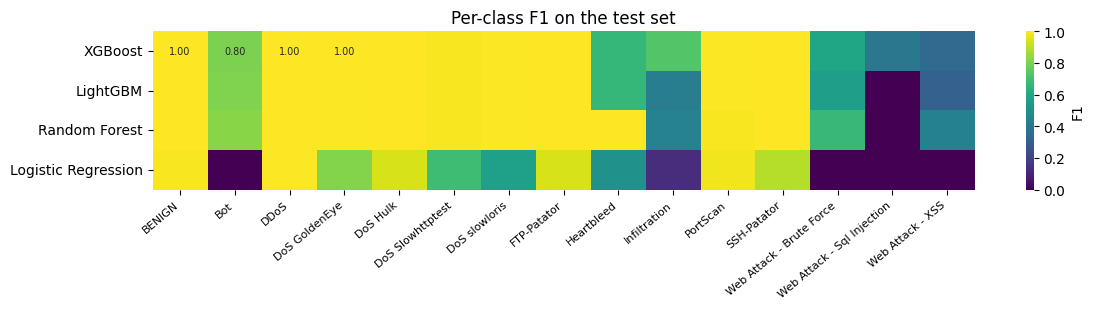

In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

K = len(target_names); ALL = list(range(K))
def per_class_f1(y_true, y_hat):
    return f1_score(y_true, y_hat, labels=ALL, average=None, zero_division=0)

# Baselines are trained on a stratified subsample of the resampled training set to keep run-time bounded.
BASELINE_N = 500_000
sub = stratified_fraction(y_train_bal, min(1.0, BASELINE_N / len(y_train_bal)))
Xb_sub, yb_sub, wb_sub = X_train_bal.iloc[sub], np.asarray(y_train_bal)[sub], w_bal[sub]

t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(Xb_sub, yb_sub, sample_weight=wb_sub)
y_pred_rf = rf.predict(X_test_fs); t_rf = time.time() - t0

t0 = time.time()
lr = LogisticRegression(max_iter=300)
lr.fit(Xb_sub, yb_sub, sample_weight=wb_sub)
y_pred_lr = lr.predict(X_test_fs); t_lr = time.time() - t0

comparison_all = pd.DataFrame([
    model_summary(y_test, y_pred, 'XGBoost'),
    model_summary(y_test, y_pred_lgbm, 'LightGBM'),
    model_summary(y_test, y_pred_rf, 'Random Forest (baseline)'),
    model_summary(y_test, y_pred_lr, 'Logistic Regression (baseline)'),
])
print(comparison_all.round(4).to_string(index=False))
print(f"Baseline fit+predict time: RF {t_rf:.0f}s, LR {t_lr:.0f}s (trained on {len(sub):,} rows)")
comparison_all.to_csv(os.path.join(FIG_DIR, 'model_comparison.csv'), index=False)
RESULTS['model_comparison'] = comparison_all.to_dict(orient='records')

# Per-class F1 heatmap (models x classes)
f1_table = pd.DataFrame({'XGBoost': per_class_f1(y_test, y_pred), 'LightGBM': per_class_f1(y_test, y_pred_lgbm),
                         'Random Forest': per_class_f1(y_test, y_pred_rf), 'Logistic Regression': per_class_f1(y_test, y_pred_lr)},
                        index=target_names).T
plt.figure(figsize=(12, 3.2))
sns.heatmap(f1_table, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1, annot_kws={'size': 7}, cbar_kws={'label': 'F1'})
plt.xticks(rotation=40, ha='right', fontsize=8); plt.title('Per-class F1 on the test set')
plt.tight_layout(); save_fig('fig_per_class_f1_heatmap'); plt.show()
f1_table.T.to_csv(os.path.join(FIG_DIR, 'per_class_f1_all_models.csv'))

### 16.2 Ablation: does the model depend on the port feature?

`Destination Port` is a legitimate behavioural feature (which service is targeted) but it is also a testbed artefact
(FTP-Patator = port 21, SSH-Patator = port 22). Retraining without the port features quantifies this dependence.

**Caution when reading the table:** the "Previous run" row (v1, with `Day_Index` and SMOTE-to-majority) differs from v2 in
*two* ways (feature set and resampling policy), so the difference between those two rows is not attributable to a single change.

                                             Setting  Accuracy  Macro-P  Macro-R  Macro-F1
Previous run (v1: with Day_Index, SMOTE to majority)    0.9994   0.9327   0.8951    0.8973
                           XGBoost v2 (no Day_Index)    0.9982   0.8656   0.8632    0.8336
                    XGBoost v2 without port features    0.9979   0.8585   0.8724    0.8540


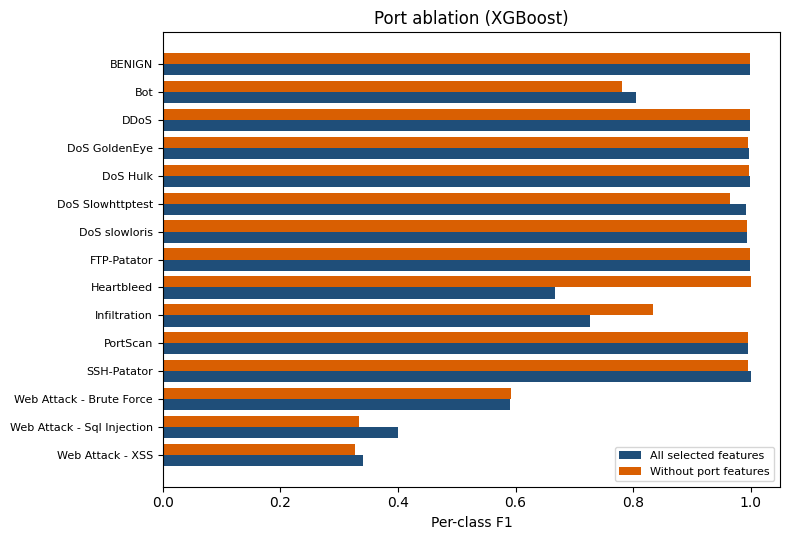

In [47]:
no_port_cols = [c for c in selected_features if c not in ('Destination Port', 'Is_WellKnown_Port')]
m_np = xgb.XGBClassifier(**model.get_params())
m_np.fit(X_train_bal[no_port_cols], y_train_bal, sample_weight=w_bal)
y_pred_np = m_np.predict(X_test_fs[no_port_cols])

def _row(setting, d):
    return {'Setting': setting, 'Accuracy': d['Accuracy'], 'Macro-P': d['Macro-P'], 'Macro-R': d['Macro-R'], 'Macro-F1': d['Macro-F1']}

PREVIOUS_RUN_WITH_DAY_INDEX = {'Accuracy': 0.999394, 'Macro-P': 0.932745, 'Macro-R': 0.895109, 'Macro-F1': 0.897327}   # v1 notebook output
ab = pd.DataFrame([
    _row('Previous run (v1: with Day_Index, SMOTE to majority)', PREVIOUS_RUN_WITH_DAY_INDEX),
    _row('XGBoost v2 (no Day_Index)', model_summary(y_test, y_pred, 'x')),
    _row('XGBoost v2 without port features', model_summary(y_test, y_pred_np, 'x')),
])
print(ab.round(4).to_string(index=False))
ab.to_csv(os.path.join(FIG_DIR, 'ablation_port.csv'), index=False)
RESULTS['ablation_port'] = ab.to_dict(orient='records')

f1_np = per_class_f1(y_test, y_pred_np); f1_main = per_class_f1(y_test, y_pred)
ypos = np.arange(K)
plt.figure(figsize=(8, 5.5))
plt.barh(ypos + 0.2, f1_main, 0.4, label='All selected features', color='#1f4e79')
plt.barh(ypos - 0.2, f1_np, 0.4, label='Without port features', color='#d95f02')
plt.yticks(ypos, target_names, fontsize=8); plt.gca().invert_yaxis(); plt.xlabel('Per-class F1'); plt.legend(fontsize=8)
plt.title('Port ablation (XGBoost)')
plt.tight_layout(); save_fig('fig_port_ablation'); plt.show()

### 16.3 Per-class chronological evaluation (uses the split defined in Section 6.2)

{'Model': 'XGBoost (chronological split)', 'Accuracy': 0.9635, 'Macro-P': 0.7102, 'Macro-R': 0.8022, 'Macro-F1': 0.7232}
                            precision    recall  f1-score   support

                    BENIGN     0.9971    0.9625    0.9795    410057
                       Bot     0.0710    0.9719    0.1323       391
                      DDoS     0.7173    0.9979    0.8346     25599
             DoS GoldenEye     0.9426    0.9985    0.9698      2055
                  DoS Hulk     0.9976    0.9407    0.9683     34538
          DoS Slowhttptest     0.7898    0.9914    0.8792      1046
             DoS slowloris     0.9906    0.7833    0.8748      1075
               FTP-Patator     1.0000    0.9781    0.9889      1186
                Heartbleed     0.0000    0.0000    0.0000         1
              Infiltration     0.7143    0.7143    0.7143         7
                  PortScan     0.9474    0.9954    0.9708     18164
               SSH-Patator     0.9952    0.9751    0.9851     

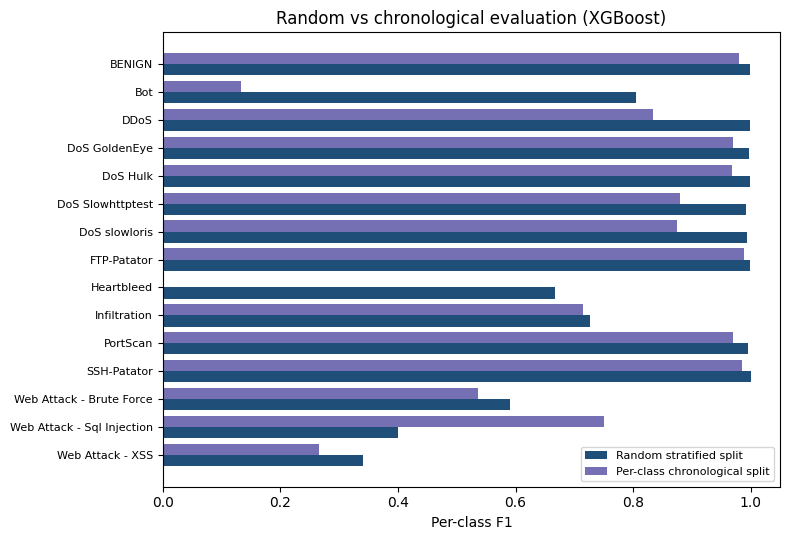

In [48]:
# Re-fit imputer / scaler / feature selection / resampling on the chronological TRAIN part only, evaluate on its LATER part.
imp_c = SimpleImputer(strategy='median').fit(X_train_time)
sc_c  = StandardScaler().fit(imp_c.transform(X_train_time))
def prep_c(Xd):
    return pd.DataFrame(sc_c.transform(imp_c.transform(Xd)), columns=Xd.columns, index=Xd.index)
Xc_tr, Xc_te = prep_c(X_train_time), prep_c(X_test_time)

sub_mi = stratified_fraction(y_train_time, min(1.0, 300_000 / len(y_train_time)))
mi = mutual_info_classif(Xc_tr.iloc[sub_mi], y_train_time.iloc[sub_mi], random_state=RANDOM_STATE)
sel_c = pd.Series(mi, index=Xc_tr.columns).sort_values(ascending=False).head(30).index.tolist()

Xc_bal, yc_bal, wc_bal, _, _ = resample_train(Xc_tr[sel_c], y_train_time)
m_c = xgb.XGBClassifier(**model.get_params())
m_c.fit(Xc_bal, yc_bal, sample_weight=wc_bal)
y_pred_c = m_c.predict(Xc_te[sel_c])

chrono = model_summary(y_test_time, y_pred_c, 'XGBoost (chronological split)')
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in chrono.items()})
print(classification_report(y_test_time, y_pred_c, labels=ALL, target_names=target_names, digits=4, zero_division=0))
RESULTS['chronological_xgb'] = chrono

f1_chr = per_class_f1(y_test_time, y_pred_c)
plt.figure(figsize=(8, 5.5))
plt.barh(ypos + 0.2, f1_main, 0.4, label='Random stratified split', color='#1f4e79')
plt.barh(ypos - 0.2, f1_chr, 0.4, label='Per-class chronological split', color='#7570b3')
plt.yticks(ypos, target_names, fontsize=8); plt.gca().invert_yaxis(); plt.xlabel('Per-class F1'); plt.legend(fontsize=8)
plt.title('Random vs chronological evaluation (XGBoost)')
plt.tight_layout(); save_fig('fig_random_vs_chronological'); plt.show()

In [49]:
# --- Transformer / GNN: STARTER STUB ONLY (not run here) ---
# These need a different data representation than the flat CSV rows used above:
#   Transformer -> treat each flow's features as a token sequence, or better, treat a WINDOW of
#                  consecutive flows (same src IP) as a sequence -> needs re-grouping by IP+time first.
#   GNN         -> build a graph where nodes = hosts/IPs and edges = flows between them, then use
#                  node/edge features with a library like PyTorch Geometric (GCN / GraphSAGE).
# Both are legitimate "future work" / extension novelty points for the paper, but require
# substantially more data-engineering than the current per-flow tabular setup.
'''
# Transformer sketch (PyTorch), operating on a single flow's features as a token sequence:
import torch, torch.nn as nn

class FlowTransformer(nn.Module):
    def __init__(self, n_features, d_model=64, n_heads=4, n_layers=2, n_classes=15):
        super().__init__()
        self.embed = nn.Linear(1, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=n_heads, batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.classifier = nn.Linear(d_model * n_features, n_classes)

    def forward(self, x):                      # x: (batch, n_features)
        x = x.unsqueeze(-1)                     # (batch, n_features, 1) -> treat each feature as a "token"
        x = self.embed(x)                       # (batch, n_features, d_model)
        x = self.encoder(x)
        x = x.flatten(1)
        return self.classifier(x)

# GNN sketch (PyTorch Geometric), operating on a host-interaction graph built from SourceDay + IP-like grouping:
# from torch_geometric.nn import GCNConv
# class FlowGCN(nn.Module):
#     def __init__(self, n_features, hidden=64, n_classes=15):
#         super().__init__()
#         self.conv1 = GCNConv(n_features, hidden)
#         self.conv2 = GCNConv(hidden, n_classes)
#     def forward(self, x, edge_index):
#         x = self.conv1(x, edge_index).relu()
#         return self.conv2(x, edge_index)
'''
print("Transformer/GNN stubs ready — extension point for later novelty work.")

Transformer/GNN stubs ready — extension point for later novelty work.


## 17. LIME Explainability

Sir-এর list-এর ২য় explainability technique। SHAP model-এর internal structure (tree splits)
ব্যবহার করে exact contribution বের করে; **LIME instance-এর চারপাশে local linear surrogate
model fit করে approximate explanation দেয়** — দুটো ভিন্ন principle, তাই দুটো ব্যবহার করাটাই
"multiple explainability techniques" novelty point হিসেবে paper-এ দেখানো যায় (একটা আরেকটাকে
cross-validate করে — যদি SHAP আর LIME একই top feature দেখায়, সেটা explanation-এর reliability
আরও শক্ত করে)।

In [50]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train_fs.values,
    feature_names=selected_features,
    class_names=target_names,
    mode='classification',
    random_state=RANDOM_STATE
)

# Same instance used for SHAP
lime_idx = idx
lime_instance = X_test_fs.loc[lime_idx].values

lime_exp = lime_explainer.explain_instance(
    lime_instance,
    model.predict_proba,
    num_features=10,
    top_labels=1
)

# Save LIME explanation as HTML
lime_exp.save_to_file("lime_explanation.html")

print("LIME explanation saved to: lime_explanation.html")

LIME explanation saved to: lime_explanation.html


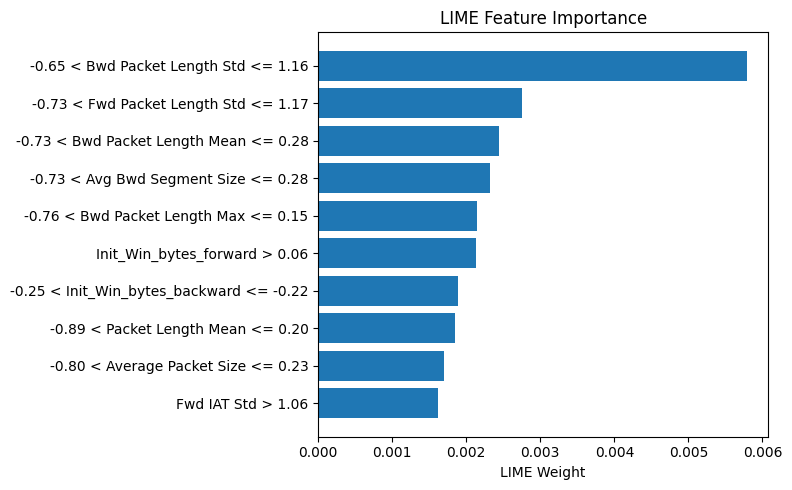

In [51]:
label = lime_exp.top_labels[0]

features = lime_exp.as_list(label=label)

features = features[::-1]

feature_names = [x[0] for x in features]
weights = [x[1] for x in features]

plt.figure(figsize=(8, 5))
plt.barh(feature_names, weights)
plt.xlabel("LIME Weight")
plt.title("LIME Feature Importance")
plt.tight_layout()
save_fig('fig_lime_ftp_patator')
plt.show()

In [52]:
# Extract LIME's top features as a plain list (for the Evidence layer in Section 19)
lime_label = lime_exp.available_labels()[0]
lime_top_features = lime_exp.as_list(label=lime_label)
print(f"LIME explanation for predicted class '{inv_label_map[lime_label]}':")
for feat, weight in lime_top_features:
    print(f"  {feat:45s}  weight={weight:+.4f}")

LIME explanation for predicted class 'FTP-Patator':
  -0.65 < Bwd Packet Length Std <= 1.16          weight=+0.0058
  -0.73 < Fwd Packet Length Std <= 1.17          weight=+0.0027
  -0.73 < Bwd Packet Length Mean <= 0.28         weight=+0.0024
  -0.73 < Avg Bwd Segment Size <= 0.28           weight=+0.0023
  -0.76 < Bwd Packet Length Max <= 0.15          weight=+0.0021
  Init_Win_bytes_forward > 0.06                  weight=+0.0021
  -0.25 < Init_Win_bytes_backward <= -0.22       weight=+0.0019
  -0.89 < Packet Length Mean <= 0.20             weight=+0.0019
  -0.80 < Average Packet Size <= 0.23            weight=+0.0017
  Fwd IAT Std > 1.06                             weight=+0.0016


## 18. Counterfactual Explanation

Sir-এর list-এর ৪র্থ technique। প্রশ্নটা এইরকম: *"এই flow-টাকে কী change করলে model একে
BENIGN হিসেবে predict করত?"* — analyst-এর কাছে এটা খুবই actionable ("যদি connection rate
কমে যেত / packet size স্বাভাবিক হতো, তাহলে এটা normal traffic মনে হতো")।

Dedicated library হিসেবে `dice-ml` আছে (`pip install dice-ml`), কিন্তু tree model-এর সাথে
মাঝে মাঝে version-conflict হয়। তাই এখানে একটা **dependency-free, transparent greedy
counterfactual search** লিখেছি যেটা sandbox-এ RandomForest দিয়ে test করে কাজ করছে confirm
করেছি — আপনার XGBoost model-এও একইভাবে কাজ করবে (শুধু `.predict` / `.predict_proba`
থাকলেই হয়, model-agnostic)।

In [53]:
def generate_counterfactual(model, instance_df, X_reference, target_class,
                             top_k=10, max_iter=60, step_frac=0.2, recompute_every=5):
    """Greedy counterfactual search: repeatedly nudge the features that differ most from the
    target class's mean, a fraction (step_frac) at a time, until the model's prediction flips
    to target_class (or max_iter is reached).
    Returns: (counterfactual_row, success_flag, n_iterations, confidence_history)"""
    inst = instance_df.copy()
    target_mean = X_reference.mean()
    history = []
    top_feats = None
    for it in range(max_iter):
        cur_pred = model.predict(inst)[0]
        cur_proba = model.predict_proba(inst)[0][target_class]
        history.append(cur_proba)
        if cur_pred == target_class:
            return inst, True, it, history
        if it % recompute_every == 0:
            gap = (target_mean - inst.iloc[0]).abs().sort_values(ascending=False)
            top_feats = gap.index[:top_k]
        for f in top_feats:
            inst.iloc[0, inst.columns.get_loc(f)] += step_frac * (target_mean[f] - inst.iloc[0][f])
    return inst, False, max_iter, history

# Apply to the same brute-force instance used above
benign_class_idx = label_map['BENIGN']
benign_reference = X_train_fs[y_train == benign_class_idx]

original_instance = X_test_fs.loc[[idx]]
cf_row, success, n_iter, conf_history = generate_counterfactual(
    model, original_instance, benign_reference, target_class=benign_class_idx
)

print(f"Counterfactual search {'SUCCEEDED' if success else 'did not converge'} in {n_iter} iterations")
print(f"BENIGN-confidence trajectory: {[round(h,3) for h in conf_history[::max(1,len(conf_history)//8)]]}")

changed = (cf_row.iloc[0] - original_instance.iloc[0]).abs().sort_values(ascending=False)
changed = changed[changed > 1e-6].head(8)
print("\nFeatures that had to change for this flow to look BENIGN (largest changes first):")
for feat, delta in changed.items():
    direction = 'increase' if cf_row.iloc[0][feat] > original_instance.iloc[0][feat] else 'decrease'
    print(f"  {feat:35s}  {direction:8s}  (Δ = {delta:.3f}, scaled units)")

Counterfactual search SUCCEEDED in 6 iterations
BENIGN-confidence trajectory: [np.float32(0.0), np.float32(0.009), np.float32(0.01), np.float32(0.034), np.float32(0.022), np.float32(0.018), np.float32(1.0)]

Features that had to change for this flow to look BENIGN (largest changes first):
  Init_Win_bytes_forward               decrease  (Δ = 1.105, scaled units)
  Fwd IAT Std                          decrease  (Δ = 1.050, scaled units)
  Fwd IAT Total                        decrease  (Δ = 0.948, scaled units)
  Fwd IAT Max                          decrease  (Δ = 0.944, scaled units)
  Fwd IAT Mean                         decrease  (Δ = 0.908, scaled units)
  Flow Duration                        decrease  (Δ = 0.755, scaled units)
  Flow IAT Std                         decrease  (Δ = 0.734, scaled units)
  Flow IAT Max                         decrease  (Δ = 0.685, scaled units)


## 19. Evidence → Attack Behavior → Recommended Response

In [54]:
# 19.1 Feature -> plain-language meaning dictionary (extend this as you study more features)
FEATURE_MEANINGS = {
    'Flow Duration':            'connection duration',
    'Flow IAT Mean':            'time gap between packets (burstiness)',
    'Flow IAT Std':             'irregularity in packet timing',
    'Flow Bytes/s':             'data transfer rate',
    'Flow Packets/s':           'packet transmission rate',
    'Total Fwd Packets':        'number of packets sent to the server',
    'Total Backward Packets':   'number of packets returned by the server',
    'SYN Flag Count':           'connection-initiation (SYN) attempts',
    'RST Flag Count':           'abruptly reset connections',
    'PSH Flag Count':           'forced data-push events',
    'ACK Flag Count':           'acknowledgement packets',
    'Fwd_Bwd_Pkt_Ratio':        'ratio of outgoing to incoming packets',
    'Bytes_per_Packet':         'average payload size per packet',
    'Fwd Packet Length Mean':   'average size of outgoing packets',
    'Bwd Packet Length Mean':   'average size of returned packets',
    'Destination Port':         'target service port',
    'Is_WellKnown_Port':        'whether a standard/well-known port is targeted',
    'Flag_Sum':                 'overall TCP flag activity',
    'Init_Win_bytes_forward':   'initial TCP window size (client side)',
    'Init_Win_bytes_backward':  'initial TCP window size (server side)',
}

def describe_feature(feat_name):
    return FEATURE_MEANINGS.get(feat_name, feat_name.lower())

# v2: well-known service ports, so that a port is described as a service rather than "abnormally low/high".
PORT_SERVICES = {20: 'FTP-data', 21: 'FTP', 22: 'SSH', 23: 'Telnet', 25: 'SMTP', 53: 'DNS', 80: 'HTTP', 110: 'POP3',
                 123: 'NTP', 143: 'IMAP', 443: 'HTTPS', 445: 'SMB', 3306: 'MySQL', 3389: 'RDP', 8080: 'HTTP-alt'}

def build_evidence_statements(top_features_with_direction, instance_row, reference_benign_mean, max_items=4, raw_port=None):
    """top_features_with_direction: list of (feature_name, shap_or_lime_value).
    raw_port: the ORIGINAL (un-scaled) destination port of the flow, used to describe the targeted service."""
    statements = []
    for feat, contribution in top_features_with_direction[:max_items]:
        if feat in ('Destination Port', 'Is_WellKnown_Port') and raw_port is not None:
            port = int(raw_port)
            svc = PORT_SERVICES.get(port, 'non-standard / unlisted service')
            statements.append(f"targets port {port} ({svc}) (feature: {feat})")
            continue
        plain = describe_feature(feat)
        val = instance_row[feat]
        ref = reference_benign_mean.get(feat, np.nan)
        if contribution > 0:
            trend = 'abnormally high' if val > ref else 'abnormally low'
        else:
            trend = 'unusual pattern in'
        statements.append(f"{trend} {plain} (feature: {feat})")
    return statements


In [55]:
# 19.2 Attack-behavior narrative templates (rule-based, per attack family -> extend as needed)
ATTACK_BEHAVIOR = {
    'FTP-Patator':               'Repeated FTP login attempts in rapid succession, consistent with automated credential guessing (brute force).',
    'SSH-Patator':                'Repeated SSH login attempts in rapid succession, consistent with automated credential guessing (brute force).',
    'DoS Hulk':                   'High-volume HTTP requests aimed at exhausting server resources (Denial-of-Service).',
    'DoS GoldenEye':              'HTTP GET/POST flood designed to exhaust server connection pool (Denial-of-Service).',
    'DoS slowloris':              'Slow, partial HTTP requests kept open to exhaust server connection slots (low-and-slow DoS).',
    'DoS Slowhttptest':           'Slow HTTP request/response manipulation to exhaust server resources (low-and-slow DoS).',
    'DDoS':                       'Coordinated high-volume traffic from the flow pattern, consistent with a distributed denial-of-service attack.',
    'PortScan':                   'Sequential probing of multiple destination ports from the same source, consistent with reconnaissance/port scanning.',
    'Bot':                        'Periodic, automated command-and-control-like traffic pattern, consistent with botnet activity.',
    'Infiltration':               'Anomalous internal traffic pattern following an initial foothold, consistent with lateral movement / infiltration.',
    'Web Attack - Brute Force':   'Repeated web-login attempts, consistent with credential brute forcing against a web application.',
    'Web Attack - XSS':           'Malformed/scripted payload pattern in web requests, consistent with cross-site scripting attempts.',
    'Web Attack - Sql Injection': 'Malformed query-like payload pattern in web requests, consistent with SQL injection attempts.',
    'Heartbleed':                 'Abnormal TLS heartbeat response pattern, consistent with the Heartbleed information-disclosure exploit.',
    'BENIGN':                     'Traffic pattern consistent with normal, legitimate usage.',
}

RECOMMENDED_RESPONSE = {
    'FTP-Patator':                'Lock/rate-limit the source IP; enforce account lockout after N failed attempts; enable MFA on FTP service.',
    'SSH-Patator':                'Rate-limit or temporarily block the source IP; enforce key-based SSH auth; enable fail2ban-style protection.',
    'DoS Hulk':                   'Enable rate-limiting/WAF rules for the target service; scale resources or activate DDoS-mitigation.',
    'DoS GoldenEye':              'Enable connection-rate limiting and WAF rules; monitor server connection pool.',
    'DoS slowloris':              'Configure server timeout limits for slow connections; deploy a reverse-proxy with slow-request protection.',
    'DoS Slowhttptest':           'Configure server timeout limits for slow connections; deploy a reverse-proxy with slow-request protection.',
    'DDoS':                       'Engage upstream DDoS mitigation/scrubbing; rate-limit at the edge; alert network operations team immediately.',
    'PortScan':                   'Flag source IP for monitoring; ensure unused ports are closed; review firewall rules.',
    'Bot':                        'Isolate the host for forensic review; block C2-suspected destinations; run malware scan on the host.',
    'Infiltration':               'Escalate to incident response immediately; isolate affected host; audit lateral-movement paths.',
    'Web Attack - Brute Force':   'Enable account lockout / CAPTCHA on login; rate-limit the source IP; enforce MFA.',
    'Web Attack - XSS':           'Sanitize/validate input on the affected endpoint; deploy/tune WAF XSS rules; review recent submissions from this source.',
    'Web Attack - Sql Injection': 'Sanitize/parameterize queries on the affected endpoint; deploy/tune WAF SQLi rules; audit database access logs.',
    'Heartbleed':                 'Patch/upgrade the affected OpenSSL version immediately; rotate certificates and secrets; audit for prior exploitation.',
    'BENIGN':                     'No action needed — continue routine monitoring.',
}
print("Behavior + response templates ready for", len(ATTACK_BEHAVIOR), "classes.")

Behavior + response templates ready for 15 classes.


In [56]:
def xthreat_report(instance_index, model, X_pool, shap_values_pool, shap_index_map,
                    explainer, benign_reference_mean, label_map, inv_label_map, run_counterfactual=True):
    row = X_pool.loc[[instance_index]]
    pred_class = model.predict(row)[0]
    pred_label = inv_label_map[pred_class]
    confidence = model.predict_proba(row).max()

    print("="*70)
    print(f"  ATTACK DETECTED: {pred_label}")
    print("="*70)

    if pred_label == 'BENIGN':
        print("No further explanation needed — this flow is classified as normal traffic.")
        print(f"Confidence: {confidence:.2%}")
        return

    # ---- Evidence + Important Features (from SHAP) ----
    pos = shap_index_map[instance_index]
    sv_row = get_class_shap_row(shap_values_pool, pos, pred_class)
    feat_importance = pd.Series(sv_row, index=X_pool.columns).sort_values(key=np.abs, ascending=False)
    top_features = list(feat_importance.head(4).items())

    print("\nWhy? -> Evidence (top contributing features, SHAP):")
    raw_port = df.loc[instance_index, 'Destination Port'] if ('Destination Port' in df.columns and instance_index in df.index) else None
    evidence = build_evidence_statements(top_features, row.iloc[0], benign_reference_mean, raw_port=raw_port)
    for e in evidence:
        print(f"  - {e}")

    print("\nImportant features (ranked by |SHAP value|):")
    for feat, val in top_features:
        print(f"  - {feat}: SHAP={val:+.4f}")

    print(f"\nAttack behavior:\n  {ATTACK_BEHAVIOR.get(pred_label, 'No template defined for this class yet.')}")

    print(f"\nConfidence: {confidence:.2%}")

    print(f"\nRecommended response:\n  {RECOMMENDED_RESPONSE.get(pred_label, 'No template defined for this class yet.')}")

    if run_counterfactual:
        benign_class_idx = label_map['BENIGN']
        benign_ref = X_train_fs[y_train == benign_class_idx]
        cf_row, success, n_iter, _ = generate_counterfactual(model, row, benign_ref, target_class=benign_class_idx,
                                                               max_iter=40)
        if success:
            changed = (cf_row.iloc[0] - row.iloc[0]).abs().sort_values(ascending=False).head(3)
            print(f"\nCounterfactual (what would make this look BENIGN):")
            for feat, delta in changed.items():
                direction = 'increase' if cf_row.iloc[0][feat] > row.iloc[0][feat] else 'decrease'
                print(f"  - {direction} {describe_feature(feat)} (feature: {feat})")
    print("="*70)


# --- Demo on 2 different predicted attack instances ---
shap_index_map = {sample_idx[i]: i for i in range(len(sample_idx))}
benign_reference_mean = X_train_fs[y_train == label_map['BENIGN']].mean()

demo_targets = [idx]  # the brute-force instance from Section 15/17/18
other_attack_idx = X_shap_sample.index[(model.predict(X_shap_sample) != label_map['BENIGN']) &
                                        (X_shap_sample.index != idx)]
if len(other_attack_idx) > 0:
    demo_targets.append(other_attack_idx[0])

for t in demo_targets:
    xthreat_report(t, model, X_shap_sample, shap_values, shap_index_map,
                    explainer, benign_reference_mean, label_map, inv_label_map)
    print()

  ATTACK DETECTED: FTP-Patator

Why? -> Evidence (top contributing features, SHAP):
  - targets port 21 (FTP) (feature: Destination Port)
  - abnormally low avg fwd segment size (feature: Avg Fwd Segment Size)
  - abnormally low data transfer rate (feature: Flow Bytes/s)
  - abnormally high total length of bwd packets (feature: Total Length of Bwd Packets)

Important features (ranked by |SHAP value|):
  - Destination Port: SHAP=+14.7437
  - Avg Fwd Segment Size: SHAP=+0.9500
  - Flow Bytes/s: SHAP=+0.8294
  - Total Length of Bwd Packets: SHAP=+0.7570

Attack behavior:
  Repeated FTP login attempts in rapid succession, consistent with automated credential guessing (brute force).

Confidence: 100.00%

Recommended response:
  Lock/rate-limit the source IP; enforce account lockout after N failed attempts; enable MFA on FTP service.

Counterfactual (what would make this look BENIGN):
  - decrease initial TCP window size (client side) (feature: Init_Win_bytes_forward)
  - decrease fwd iat st

## 20. Quantitative evaluation of the explanations

A single case study is not evidence. Here SHAP and LIME are compared on a stratified set of predicted-attack flows
(up to 3 per predicted class), and the counterfactual search is run on the same flows.

* **Overlap@5** — fraction of SHAP's top-5 features that are also LIME's top-5 (same instance, predicted class).
* **Sign agreement** — among SHAP top-5 features that LIME also reports, the fraction with the same sign.
* **Top-1 agreement** — whether both methods rank the same feature first.
* **Counterfactual** — success rate, iterations and L2 distance (standardised units) of the greedy search towards BENIGN.

Evaluating explanations on 29 predicted-attack flows from 11 classes
                          overlap_at5  sign_agreement  top1_agree
cls                                                              
Bot                             0.200           0.833       0.000
DDoS                            0.067           1.000       0.000
DoS GoldenEye                   0.400           1.000       0.000
DoS Hulk                        0.467           1.000       0.667
DoS Slowhttptest                0.400           1.000       0.000
DoS slowloris                   0.200           0.833       0.000
FTP-Patator                     0.133           0.750       0.000
PortScan                        0.400           1.000       0.333
SSH-Patator                     0.500           0.800       0.500
Web Attack - Brute Force        0.267           0.778       0.000
Web Attack - XSS                0.600           0.750       0.000
{'n': 29, 'overlap_at5_mean': 0.31034482758620685, 'sign_agreement_mean':

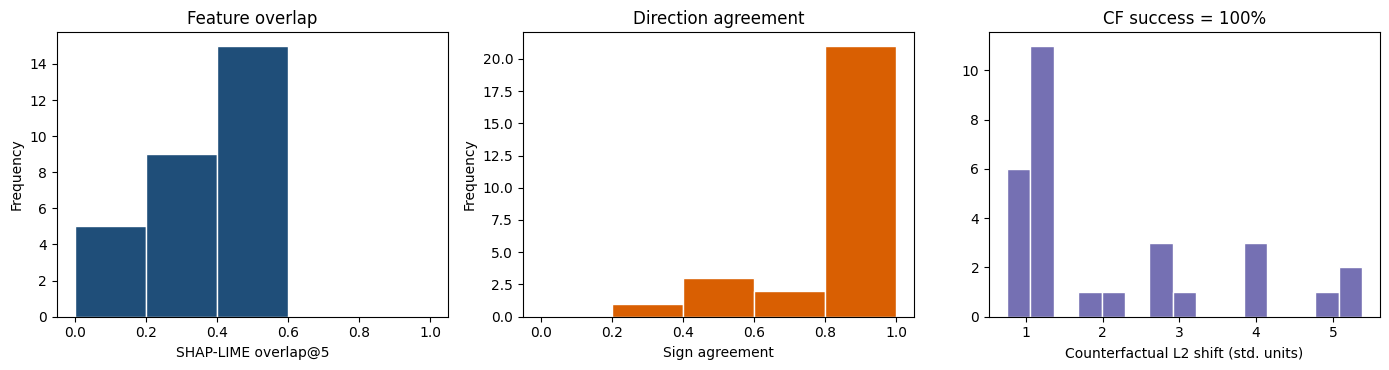

In [57]:
rs = np.random.RandomState(RANDOM_STATE)
pred_sample = model.predict(X_shap_sample)
attack_pos = np.where(pred_sample != label_map['BENIGN'])[0]
chosen = []
for c in np.unique(pred_sample[attack_pos]):
    pos_c = attack_pos[pred_sample[attack_pos] == c]
    chosen.extend(rs.choice(pos_c, size=min(3, len(pos_c)), replace=False).tolist())
print(f"Evaluating explanations on {len(chosen)} predicted-attack flows from {len(np.unique(pred_sample[attack_pos]))} classes")

TOPK = 5
agree_rows = []
for pos in chosen:
    c = int(pred_sample[pos])
    sv = shap_arr[pos, :, c]
    shap_top = np.argsort(-np.abs(sv))[:TOPK]
    exp_i = lime_explainer.explain_instance(X_shap_sample.iloc[pos].values, model.predict_proba,
                                            num_features=10, labels=(c,), num_samples=2000)
    lw = dict(exp_i.as_map()[c])                                   # {feature index: LIME weight}
    lime_top = sorted(lw, key=lambda j: -abs(lw[j]))[:TOPK]
    common = [j for j in shap_top if j in lw]
    agree_rows.append(dict(cls=inv_label_map[c],
                           overlap_at5=len(set(shap_top) & set(lime_top)) / TOPK,
                           sign_agreement=float(np.mean([np.sign(sv[j]) == np.sign(lw[j]) for j in common])) if common else np.nan,
                           top1_agree=bool(shap_top[0] == lime_top[0])))
agree = pd.DataFrame(agree_rows)
print(agree.groupby('cls')[['overlap_at5', 'sign_agreement', 'top1_agree']].mean().round(3))
summary_agree = dict(n=len(agree), overlap_at5_mean=float(agree['overlap_at5'].mean()),
                     sign_agreement_mean=float(agree['sign_agreement'].mean()), top1_agreement_rate=float(agree['top1_agree'].mean()))
print(summary_agree)
RESULTS['shap_lime_agreement'] = summary_agree
agree.to_csv(os.path.join(FIG_DIR, 'shap_lime_agreement.csv'), index=False)

# Counterfactual statistics on the same flows
benign_ref = X_train_fs[y_train == label_map['BENIGN']]
cf_rows = []
for pos in chosen:
    row = X_shap_sample.iloc[[pos]]
    cf, ok, n_it, hist = generate_counterfactual(model, row, benign_ref, target_class=label_map['BENIGN'], max_iter=60)
    delta = cf.iloc[0] - row.iloc[0]
    cf_rows.append(dict(cls=inv_label_map[int(pred_sample[pos])], success=bool(ok), iterations=int(n_it),
                        l2=float(np.linalg.norm(delta.values)), final_benign_prob=float(hist[-1])))
cfs = pd.DataFrame(cf_rows)
print(cfs.groupby('cls')[['success', 'iterations', 'l2']].mean().round(3))
summary_cf = dict(success_rate=float(cfs['success'].mean()), median_iterations=float(cfs['iterations'].median()),
                  median_l2=float(cfs['l2'].median()))
print(summary_cf)
RESULTS['counterfactual'] = summary_cf
cfs.to_csv(os.path.join(FIG_DIR, 'counterfactual_stats.csv'), index=False)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
agree['overlap_at5'].plot.hist(bins=np.linspace(0, 1, 6), ax=ax[0], color='#1f4e79', edgecolor='white'); ax[0].set_xlabel('SHAP-LIME overlap@5'); ax[0].set_title('Feature overlap')
agree['sign_agreement'].dropna().plot.hist(bins=np.linspace(0, 1, 6), ax=ax[1], color='#d95f02', edgecolor='white'); ax[1].set_xlabel('Sign agreement'); ax[1].set_title('Direction agreement')
ax[2].hist(cfs['l2'], bins=15, color='#7570b3', edgecolor='white'); ax[2].set_xlabel('Counterfactual L2 shift (std. units)'); ax[2].set_title(f"CF success = {summary_cf['success_rate']:.0%}")
plt.tight_layout(); save_fig('fig_explanation_evaluation'); plt.show()

In [58]:
# Export every number needed by the paper/report in one file, and list the saved figures.
import json
def _js(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
RESULTS['xgb_per_class'] = classification_report(y_test, y_pred, target_names=target_names, digits=4, zero_division=0, output_dict=True)
RESULTS['lgbm_per_class'] = classification_report(y_test, y_pred_lgbm, target_names=target_names, digits=4, zero_division=0, output_dict=True)
RESULTS['macro_roc_auc_ovr_xgb'] = float(roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro'))
with open(os.path.join(FIG_DIR, 'results_summary.json'), 'w') as f:
    json.dump(RESULTS, f, indent=2, default=_js)
print("Saved:", sorted(os.listdir(FIG_DIR)))

Saved: ['ablation_port.csv', 'confusion_matrix_counts_xgb.csv', 'counterfactual_stats.csv', 'fig_binary_roc_pr.pdf', 'fig_binary_roc_pr.png', 'fig_class_distribution_raw.pdf', 'fig_class_distribution_raw.png', 'fig_class_distribution_resampling.pdf', 'fig_class_distribution_resampling.png', 'fig_confusion_matrix_xgb.pdf', 'fig_confusion_matrix_xgb.png', 'fig_explanation_evaluation.pdf', 'fig_explanation_evaluation.png', 'fig_key_feature_distributions.pdf', 'fig_key_feature_distributions.png', 'fig_learning_curve.pdf', 'fig_learning_curve.png', 'fig_lime_ftp_patator.pdf', 'fig_lime_ftp_patator.png', 'fig_per_class_f1_heatmap.pdf', 'fig_per_class_f1_heatmap.png', 'fig_port_ablation.pdf', 'fig_port_ablation.png', 'fig_random_vs_chronological.pdf', 'fig_random_vs_chronological.png', 'fig_selected_feature_correlation.pdf', 'fig_selected_feature_correlation.png', 'fig_shap_global_predicted_class.pdf', 'fig_shap_global_predicted_class.png', 'fig_shap_global_stacked.pdf', 'fig_shap_global_stac

## 21. v3 extensions — the experiments a strict Q1 reviewer will ask for
Sections 1–20 are unchanged (v2). Everything below is **append-only**: it re-uses the variables created above (`X`, `y`, `model`, `X_train_fs`, `shap_arr`, ...) and does not modify them. Run the notebook top-to-bottom.

| Reviewer concern | v3 answer | Cell |
|---|---|---|
| Single run, no uncertainty, no significance test | paired bootstrap CIs, McNemar, MCC, **multi-seed** mean ± SD / t-interval, feature-selection stability | 21.1, 21.2 |
| Random split inflated by near-duplicate flows | near-duplicate leakage rate + **group-aware split** | 21.3 |
| SMOTE vs weights never compared (single factor) | imbalance ablation | 21.4 |
| "Confidence" in the report is an uncalibrated softmax | **calibration (ECE/Brier/T-scaling) + split-conformal prediction sets** | 21.5 |
| Explanations evaluated only by agreement (no chance level, no fidelity) | chance-corrected agreement, cluster-level agreement, **deletion/sufficiency fidelity**, **stability** | 21.6 |
| Counterfactuals unconstrained and unvalidated | immutable features, benign-range bounds, pruning, plausibility (kNN) | 21.7 |
| Transformer required by the brief but missing | FT-Transformer-style model, paired comparison with XGBoost, Integrated Gradients | 21.8 |
| Single dataset | optional **cross-dataset test on CSE-CIC-IDS2018** (+ no-port variant) | 21.9 |

Set `XTHREAT_FAST=1` for a quick smoke test; default settings are the full experiment. Optional: `XTHREAT_DATA_DIR_2018` for cross-dataset.

In [59]:
# 21.0  Configuration and helper functions for the v3 (journal-grade) experiments
import json, math, itertools
from scipy.stats import spearmanr, binomtest, t as student_t
from sklearn.metrics import matthews_corrcoef, balanced_accuracy_score
from sklearn.model_selection import GroupShuffleSplit
import lightgbm as lgb

FAST = os.environ.get("XTHREAT_FAST", "0") == "1"   # XTHREAT_FAST=1 -> quick smoke test with reduced sizes
N_SEEDS        = 2 if FAST else 3                    # repeated-split seeds (Section 21.2)
BOOT_B         = 200 if FAST else 1000               # bootstrap replicates
EXPL_PER_CLASS = 3 if FAST else 8                    # flows per predicted class in the explanation audit
LIME_SAMPLES   = 500 if FAST else 1500
DL_TRAIN_ROWS  = 40_000 if FAST else 400_000         # rows for the tabular Transformer
DL_EPOCHS      = 3 if FAST else 10
RESULTS_V3 = {}
K = len(target_names); ALL = list(range(K))
print(f"FAST={FAST} | seeds={N_SEEDS} | bootstrap={BOOT_B} | audit flows/class={EXPL_PER_CLASS}")

def cm_fast(y, p, k=K):
    """Confusion matrix via bincount (fast enough for 1,000 bootstrap replicates on 495k rows)."""
    return np.bincount(np.asarray(y) * k + np.asarray(p), minlength=k * k).reshape(k, k)

def scores_from_cm(cm):
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    prec = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    rec  = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) > 0)
    f1   = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    present = cm.sum(1) > 0
    return dict(acc=tp.sum() / cm.sum(), macro_f1=f1[present].mean(), f1=f1, recall=rec)

def ece_score(proba, y, n_bins=15):
    """Expected calibration error of the top-label confidence."""
    proba = np.asarray(proba); y = np.asarray(y)
    conf = proba.max(1); correct = (proba.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1); e = 0.0
    for lo_, hi_ in zip(edges[:-1], edges[1:]):
        m = (conf > lo_) & (conf <= hi_)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)

def brier_multiclass(proba, y):
    oh = np.eye(proba.shape[1])[np.asarray(y)]
    return float(((np.asarray(proba) - oh) ** 2).sum(1).mean())

def mean_ci(v, B=1000, seed=0):
    """Mean and 95% bootstrap CI of a 1-D array (NaNs dropped)."""
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if len(v) == 0: return np.nan, (np.nan, np.nan)
    rs_ = np.random.RandomState(seed)
    bs = [v[rs_.randint(0, len(v), len(v))].mean() for _ in range(B)]
    return float(v.mean()), tuple(np.percentile(bs, [2.5, 97.5]))

def fit_eval_pipeline(Xtr, ytr, Xte, yte, seed=RANDOM_STATE, models=("xgb",), mi_rows=300_000, n_features=30):
    """The full leakage-safe pipeline on ANY split: median-impute -> scale -> MI top-k (train subsample)
    -> capped resampling -> fit -> predict. Everything is fitted on the training part only."""
    Xtr = Xtr.copy(); Xte = Xte.copy(); ytr = pd.Series(np.asarray(ytr), index=Xtr.index)
    imp = SimpleImputer(strategy="median").fit(Xtr)
    sc = StandardScaler().fit(imp.transform(Xtr))
    prep = lambda Z: pd.DataFrame(sc.transform(imp.transform(Z)), columns=Z.columns, index=Z.index)
    Xtr_s, Xte_s = prep(Xtr), prep(Xte)
    sub = stratified_fraction(ytr.values, min(1.0, mi_rows / len(ytr)), seed=seed)
    mi = mutual_info_classif(Xtr_s.iloc[sub], ytr.values[sub], random_state=seed)
    sel = pd.Series(mi, index=Xtr_s.columns).sort_values(ascending=False).head(n_features).index.tolist()
    Xb, yb, wb, _, _ = resample_train(Xtr_s[sel], ytr, seed=seed)
    present = np.unique(np.asarray(yb)); remap = {c: i for i, c in enumerate(present)}
    yb_r = np.array([remap[c] for c in np.asarray(yb)])
    out = {"selected": sel, "preds": {}, "proba": {}, "fit_seconds": {}, "present_train": present.tolist()}
    for name in models:
        t0 = time.time()
        if name == "xgb":
            m = xgb.XGBClassifier(**{**model.get_params(), "random_state": seed, "num_class": len(present)})
            m.fit(Xb, yb_r, sample_weight=wb)
        elif name == "lgbm":
            nest = int(getattr(lgbm_model, "best_iteration_", None) or 200)
            m = lgb.LGBMClassifier(**{**lgbm_model.get_params(), "n_estimators": nest, "random_state": seed})
            m.fit(Xb, yb_r, sample_weight=wb)
        elif name == "rf":
            s2 = stratified_fraction(yb_r, min(1.0, BASELINE_N / len(yb_r)), seed=seed)
            m = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=seed)
            m.fit(Xb.iloc[s2], yb_r[s2], sample_weight=wb[s2])
        P = np.zeros((len(Xte_s), K)); P[:, present[np.asarray(m.classes_, dtype=int)]] = m.predict_proba(Xte_s[sel])
        out["proba"][name] = P; out["preds"][name] = P.argmax(1); out["fit_seconds"][name] = time.time() - t0
    return out
print("v3 helpers ready.")

FAST=False | seeds=3 | bootstrap=1000 | audit flows/class=8
v3 helpers ready.


### 21.1 Paired bootstrap, MCC and McNemar on the main split
Why: with 1–7 test flows in three classes, a single macro-F1 number has a wide uncertainty. Resampling test rows gives a CI for each model, and resampling *the same rows* for two models gives a **paired** CI for the difference. If the CI of the difference contains 0, the ranking of the two models is not supported by the data. MCC and balanced accuracy are added because accuracy is uninformative at 83 % benign.

In [60]:
# 21.1  Paired bootstrap confidence intervals, MCC and McNemar tests on the main test split
y_te = np.asarray(y_test)
P_main = {"XGBoost": np.asarray(y_pred), "LightGBM": np.asarray(y_pred_lgbm),
          "Random Forest": np.asarray(y_pred_rf), "Logistic Regression": np.asarray(y_pred_lr)}
rs_b = np.random.RandomState(RANDOM_STATE); n_te = len(y_te)
boot = {k: {"acc": [], "f1": []} for k in P_main}
for b in range(BOOT_B):
    ii = rs_b.randint(0, n_te, n_te); yb_ = y_te[ii]
    for k, p in P_main.items():
        s = scores_from_cm(cm_fast(yb_, p[ii])); boot[k]["acc"].append(s["acc"]); boot[k]["f1"].append(s["macro_f1"])

rows = []
for k, p in P_main.items():
    s = scores_from_cm(cm_fast(y_te, p))
    lo_, hi_ = np.percentile(boot[k]["f1"], [2.5, 97.5])
    d = np.array(boot[k]["f1"]) - np.array(boot["XGBoost"]["f1"])
    if k == "XGBoost":
        delta, pgt, pmc = "-", "-", "-"
    else:
        dl, dh = np.percentile(d, [2.5, 97.5]); delta = f"{d.mean():+.3f} [{dl:+.3f}, {dh:+.3f}]"
        pgt = f"{(d > 0).mean():.2f}"
        b01 = int(((P_main['XGBoost'] == y_te) & (p != y_te)).sum()); c01 = int(((P_main['XGBoost'] != y_te) & (p == y_te)).sum())
        pmc = f"{binomtest(b01, b01 + c01, 0.5).pvalue:.2e}" if (b01 + c01) > 0 else "n/a"
    rows.append({"Model": k, "Accuracy": s["acc"], "Macro-F1": s["macro_f1"], "Macro-F1 95% CI": f"[{lo_:.3f}, {hi_:.3f}]",
                 "MCC": matthews_corrcoef(y_te, p), "Balanced acc.": balanced_accuracy_score(y_te, p),
                 "Delta F1 vs XGB (paired)": delta, "P(model > XGB)": pgt, "McNemar p (acc)": pmc})
paired_tbl = pd.DataFrame(rows)
print(paired_tbl.round(4).to_string(index=False))
paired_tbl.to_csv(os.path.join(FIG_DIR, "v3_paired_bootstrap.csv"), index=False)
RESULTS_V3["paired_bootstrap"] = paired_tbl.to_dict(orient="records")
print("\nReading guide: if the paired CI of 'Delta F1' contains 0, the two models are NOT significantly different on this test set.")

              Model  Accuracy  Macro-F1 Macro-F1 95% CI    MCC  Balanced acc. Delta F1 vs XGB (paired) P(model > XGB) McNemar p (acc)
            XGBoost    0.9982    0.8336  [0.785, 0.887] 0.9942         0.8632                        -              -               -
           LightGBM    0.9980    0.7821  [0.759, 0.818] 0.9933         0.8482  -0.047 [-0.098, +0.001]           0.03        9.61e-09
      Random Forest    0.9981    0.8224  [0.777, 0.848] 0.9936         0.8197  -0.021 [-0.076, +0.030]           0.24        8.94e-03
Logistic Regression    0.9824    0.5614  [0.548, 0.600] 0.9420         0.6304  -0.267 [-0.319, -0.217]           0.00        0.00e+00

Reading guide: if the paired CI of 'Delta F1' contains 0, the two models are NOT significantly different on this test set.


### 21.2 Repeated stratified splits (multi-seed)
Why: the seed controls the split, SMOTE, feature selection and model initialisation. Mean ± SD and a t-based 95 % interval over seeds show whether conclusions survive a different split. The **stability of the mutual-information feature selection** (Jaccard across seeds) is reported because SHAP conclusions depend on which 30 features were selected. Cost: roughly `N_SEEDS` × (the full XGBoost + LightGBM + RF training of Sections 13–16); reduce `MS_MODELS` or `N_SEEDS` if needed.

In [61]:
# 21.2  Repeated stratified splits (multi-seed): mean +/- SD, t-interval, feature-selection stability
RUN_MULTISEED = True
SEEDS = [11, 22, 33, 44, 55][:N_SEEDS]
MS_MODELS = ("xgb", "lgbm", "rf")          # drop models here to save run-time
ms_rows, ms_sel, ms_f1 = [], {}, {}
if RUN_MULTISEED:
    for sd in SEEDS:
        t0 = time.time()
        Xtr_, Xte_, ytr_, yte_ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=sd)
        res = fit_eval_pipeline(Xtr_, ytr_, Xte_, yte_, seed=sd, models=MS_MODELS)
        ms_sel[sd] = res["selected"]
        for nm in MS_MODELS:
            p_ = res["preds"][nm]; s = scores_from_cm(cm_fast(np.asarray(yte_), p_))
            ms_rows.append({"seed": sd, "model": nm, "accuracy": s["acc"], "macro_f1": s["macro_f1"],
                            "mcc": matthews_corrcoef(np.asarray(yte_), p_)})
            ms_f1[(sd, nm)] = s["f1"]
        print(f"seed {sd} done in {time.time()-t0:.0f}s: " + ", ".join(f"{nm} F1={ms_rows[-len(MS_MODELS)+i]['macro_f1']:.4f}" for i, nm in enumerate(MS_MODELS)))
        del Xtr_, Xte_, ytr_, yte_, res; gc.collect()
    ms = pd.DataFrame(ms_rows)
    summ = []
    for nm, g in ms.groupby("model"):
        n_ = len(g); tq = student_t.ppf(0.975, n_ - 1) if n_ > 1 else np.nan
        row = {"model": nm, "n_seeds": n_}
        for m_ in ("accuracy", "macro_f1", "mcc"):
            sd_ = g[m_].std(ddof=1) if n_ > 1 else np.nan
            row[m_ + "_mean"] = g[m_].mean(); row[m_ + "_sd"] = sd_; row[m_ + "_ci95_half"] = tq * sd_ / np.sqrt(n_) if n_ > 1 else np.nan
        summ.append(row)
    ms_summary = pd.DataFrame(summ)
    print(ms_summary.round(4).to_string(index=False))
    ms.to_csv(os.path.join(FIG_DIR, "v3_multiseed_runs.csv"), index=False); ms_summary.to_csv(os.path.join(FIG_DIR, "v3_multiseed_summary.csv"), index=False)
    # feature-selection stability (Jaccard of the selected 30-feature sets across seeds)
    jac = [len(set(a) & set(b)) / len(set(a) | set(b)) for a, b in itertools.combinations(ms_sel.values(), 2)]
    core = set.intersection(*[set(v) for v in ms_sel.values()])
    print(f"Feature-selection stability: mean pairwise Jaccard = {np.mean(jac):.3f}; {len(core)} features selected in ALL seeds.")
    # per-class F1 dispersion (which classes are unstable?)
    pcs = pd.DataFrame({nm: np.mean([ms_f1[(sd, nm)] for sd in SEEDS], axis=0) for nm in MS_MODELS}, index=target_names)
    pcs_sd = pd.DataFrame({nm: np.std([ms_f1[(sd, nm)] for sd in SEEDS], axis=0, ddof=1) if len(SEEDS) > 1 else np.nan for nm in MS_MODELS}, index=target_names)
    pcs_out = pd.concat({"mean_F1": pcs, "sd_F1": pcs_sd}, axis=1)
    print(pcs_out.round(3).to_string()); pcs_out.to_csv(os.path.join(FIG_DIR, "v3_multiseed_per_class.csv"))
    RESULTS_V3["multiseed_summary"] = ms_summary.to_dict(orient="records")
    RESULTS_V3["feature_selection_stability"] = dict(mean_jaccard=float(np.mean(jac)), n_core=len(core), core=sorted(core))

seed 11 done in 697s: xgb F1=0.8583, lgbm F1=0.7976, rf F1=0.8283
seed 22 done in 733s: xgb F1=0.8247, lgbm F1=0.8285, rf F1=0.8100
seed 33 done in 712s: xgb F1=0.8522, lgbm F1=0.8042, rf F1=0.8327
model  n_seeds  accuracy_mean  accuracy_sd  accuracy_ci95_half  macro_f1_mean  macro_f1_sd  macro_f1_ci95_half  mcc_mean  mcc_sd  mcc_ci95_half
 lgbm        3         0.9976       0.0001              0.0002         0.8101       0.0163              0.0404    0.9921  0.0003         0.0007
   rf        3         0.9981       0.0001              0.0002         0.8237       0.0121              0.0300    0.9936  0.0003         0.0007
  xgb        3         0.9976       0.0000              0.0001         0.8451       0.0179              0.0445    0.9921  0.0001         0.0002
Feature-selection stability: mean pairwise Jaccard = 1.000; 30 features selected in ALL seeds.
                           mean_F1                sd_F1              
                               xgb   lgbm     rf    xgb   lgb

### 21.3 Near-duplicate leakage and a group-aware split
Why: CICFlowMeter produces many almost identical flows (scans, floods). A random split places siblings on both sides of the split and rewards memorisation. We (i) measure what fraction of random-split test flows have a near-identical flow (same rounded 30-feature key) in the training set and (ii) re-evaluate with `GroupShuffleSplit`, which keeps near-duplicate groups together. This is stricter than de-duplicating exact rows.

In [62]:
# 21.3  Near-duplicate leakage diagnostic and a group-aware (near-duplicate-safe) split
def make_keys(decimals):
    return pd.Series(pd.util.hash_pandas_object(X[selected_features].round(decimals), index=False).values, index=X.index)

leak_rows = []
for dec in (1, 0):
    ks_ = make_keys(dec); tr_k = set(ks_.loc[X_train.index].tolist())
    dup = ks_.loc[X_test.index].isin(tr_k).values
    yt = np.asarray(y_test)
    leak_rows.append({"rounding (log-scale decimals)": dec, "test flows with a near-duplicate in train": float(dup.mean()),
                      **{f"  {inv_label_map[c]}": float(dup[yt == c].mean()) if (yt == c).any() else np.nan for c in ALL}})
leak_tbl = pd.DataFrame(leak_rows).set_index("rounding (log-scale decimals)").T
print("Share of random-split TEST flows that have a near-identical flow (same rounded 30-feature key) in TRAIN:")
print(leak_tbl.round(3).to_string())
leak_tbl.to_csv(os.path.join(FIG_DIR, "v3_near_duplicate_leakage.csv"))
RESULTS_V3["near_duplicate_leakage_overall"] = {str(k): float(v) for k, v in leak_tbl.iloc[0].items()}

keys_g = make_keys(0); groups = pd.factorize(keys_g)[0]
print(f"\nGroup-aware split: {len(np.unique(groups)):,} near-duplicate groups over {len(X):,} flows")
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_i, te_i = next(gss.split(X, y, groups))
Xg_tr, Xg_te, yg_tr, yg_te = X.iloc[tr_i], X.iloc[te_i], y.iloc[tr_i], y.iloc[te_i]
miss_tr = sorted(set(ALL) - set(np.unique(yg_tr))); miss_te = sorted(set(ALL) - set(np.unique(yg_te)))
print("Classes absent from group-split TRAIN:", [inv_label_map[c] for c in miss_tr], "| absent from TEST:", [inv_label_map[c] for c in miss_te])
res_g = fit_eval_pipeline(Xg_tr, yg_tr, Xg_te, yg_te, models=("xgb",))
pg = res_g["preds"]["xgb"]; sg = scores_from_cm(cm_fast(np.asarray(yg_te), pg))
present_te = np.unique(np.asarray(yg_te))
f1_rand_same = per_class_f1(y_test, y_pred)[present_te].mean()
print(f"Group-aware split : accuracy={sg['acc']:.4f}  macro-F1 (classes present in test)={sg['macro_f1']:.4f}")
print(f"Random split      : macro-F1 over the SAME classes = {f1_rand_same:.4f}")
gtab = pd.DataFrame({"class": target_names, "test_support_group": np.bincount(np.asarray(yg_te), minlength=K), "F1_group_split": sg["f1"],
                     "F1_random_split": per_class_f1(y_test, y_pred)})
print(gtab.round(4).to_string(index=False)); gtab.to_csv(os.path.join(FIG_DIR, "v3_group_split.csv"), index=False)
RESULTS_V3["group_split"] = dict(macro_f1_group=float(sg["macro_f1"]), macro_f1_random_same_classes=float(f1_rand_same), acc_group=float(sg["acc"]),
                                  absent_train=[inv_label_map[c] for c in miss_tr], absent_test=[inv_label_map[c] for c in miss_te])
del Xg_tr, Xg_te; gc.collect()

Share of random-split TEST flows that have a near-identical flow (same rounded 30-feature key) in TRAIN:
rounding (log-scale decimals)                  1      0
test flows with a near-duplicate in train  0.514  0.739
  BENIGN                                   0.472  0.689
  Bot                                      0.517  0.581
  DDoS                                     0.691  0.989
  DoS GoldenEye                            0.525  0.930
  DoS Hulk                                 0.809  0.993
  DoS Slowhttptest                         0.975  0.992
  DoS slowloris                            0.954  0.988
  FTP-Patator                              0.760  0.999
  Heartbleed                               0.000  0.000
  Infiltration                             0.000  0.143
  PortScan                                 0.544  0.941
  SSH-Patator                              0.774  0.981
  Web Attack - Brute Force                 0.969  0.983
  Web Attack - Sql Injection               0.250  0.250

209

### 21.4 Single-factor imbalance ablation
Why: v2 changed several things at once, so SMOTE's contribution was never isolated. Here only the imbalance handling changes (same features, same split, same hyper-parameters): natural data vs. capped sqrt-inverse-frequency class weights vs. the capped SMOTE policy used in this notebook.

In [63]:
# 21.4  Single-factor imbalance ablation: natural vs sqrt-inverse-frequency weights vs capped SMOTE (current)
cnt_ = pd.Series(np.asarray(y_train)).value_counts()
w_sqrt = np.minimum(50.0, np.sqrt(cnt_.max() / cnt_))                 # capped sqrt-inverse-frequency class weights
sw_sqrt = pd.Series(np.asarray(y_train)).map(w_sqrt).to_numpy()
abl = {}
for tag, sw in [("A: natural, unweighted", None), ("B: natural + capped sqrt-inverse weights", sw_sqrt)]:
    t0 = time.time()
    m_ = xgb.XGBClassifier(**model.get_params()); m_.fit(X_train_fs, y_train, sample_weight=sw)
    abl[tag] = m_.predict(X_test_fs); print(f"{tag}: fitted in {time.time()-t0:.0f}s")
abl["C: capped SMOTE + tiny-class weights (used)"] = np.asarray(y_pred)
rows = []
for tag, p in abl.items():
    s = scores_from_cm(cm_fast(y_te, p))
    rows.append({"Variant": tag, "Accuracy": s["acc"], "Macro-F1": s["macro_f1"], "MCC": matthews_corrcoef(y_te, p),
                 **{f"F1 {inv_label_map[c]}": s["f1"][c] for c in ALL if inv_label_map[c] in
                    ("Bot", "Infiltration", "Web Attack - Brute Force", "Web Attack - Sql Injection", "Web Attack - XSS", "Heartbleed")}})
imb = pd.DataFrame(rows); print(imb.round(4).to_string(index=False))
imb.to_csv(os.path.join(FIG_DIR, "v3_imbalance_ablation.csv"), index=False)
RESULTS_V3["imbalance_ablation"] = imb.to_dict(orient="records")

A: natural, unweighted: fitted in 415s
B: natural + capped sqrt-inverse weights: fitted in 463s
                                    Variant  Accuracy  Macro-F1    MCC  F1 Bot  F1 Heartbleed  F1 Infiltration  F1 Web Attack - Brute Force  F1 Web Attack - Sql Injection  F1 Web Attack - XSS
                     A: natural, unweighted    0.9986    0.8915 0.9955  0.8279         1.0000           0.8333                       0.6621                         0.8571               0.2159
   B: natural + capped sqrt-inverse weights    0.9983    0.8284 0.9946  0.8102         0.6667           0.6154                       0.6311                         0.4000               0.3286
C: capped SMOTE + tiny-class weights (used)    0.9982    0.8336 0.9942  0.8043         0.6667           0.7273                       0.5914                         0.4000               0.3400


### 21.5 Calibrated confidence and conformal prediction sets
Why: the report contains a "Confidence" stage, but a raw softmax is not a probability of being right. We measure **ECE/Brier/NLL**, fit a **temperature** on a calibration part of the test set, and build **split-conformal prediction sets** (marginal and class-conditional/Mondrian) with a target coverage of 95 %. A flow with a singleton set can be auto-accepted; a multi-label set is routed to an analyst. The shift check re-uses the thresholds on the chronological split: under distribution shift the coverage guarantee is expected to break, which is itself a finding.

Calibration part: 148,555 flows | evaluation part: 346,637 flows
                     Probabilities     ECE   Brier     NLL
                       XGBoost raw 0.00049 0.00256 0.00508
after temperature scaling (T=1.07) 0.00046 0.00255 0.00502


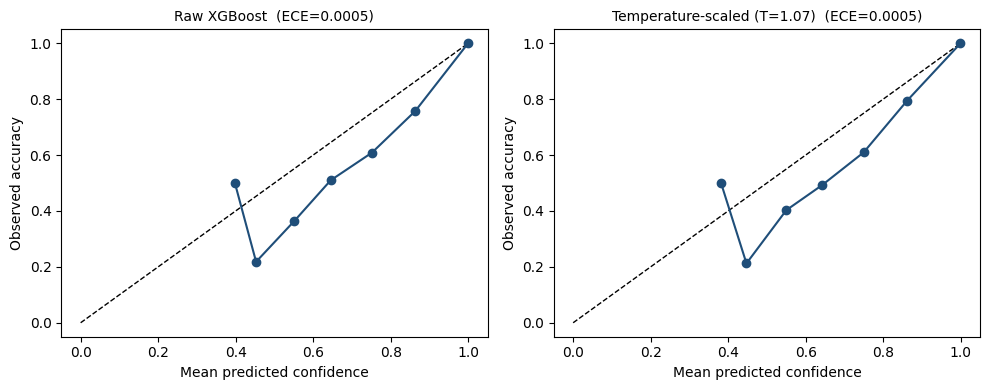

alpha=0.05: target coverage >= 0.95. Classes with < 20 calibration flows use the marginal threshold: ['Heartbleed', 'Infiltration', 'Web Attack - Sql Injection']
                          method  coverage  avg_set_size  singleton_rate  min_class_coverage
                  marginal (LAC)    0.9982        1.0000          1.0000                 0.0
class-conditional (Mondrian LAC)    0.9984        1.0012          0.9988                 0.0
                            marginal  class-conditional
BENIGN                         0.998              0.998
Bot                            0.964              0.985
DDoS                           1.000              1.000
DoS GoldenEye                  0.999              0.999
DoS Hulk                       0.999              0.999
DoS Slowhttptest               0.989              0.989
DoS slowloris                  0.991              0.991
FTP-Patator                    1.000              1.000
Heartbleed                     1.000              1.000

In [64]:
# 21.5  The "Confidence" stage done properly: calibration (ECE/Brier, temperature scaling) + split-conformal prediction sets
from scipy.optimize import minimize_scalar

def split_cal_eval(y, cal_frac=0.3, seed=RANDOM_STATE):
    rs_ = np.random.RandomState(seed); cal, ev = [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]; rs_.shuffle(idx)
        n_cal = int(round(cal_frac * len(idx))) if len(idx) >= 2 else 0
        cal.extend(idx[:n_cal]); ev.extend(idx[n_cal:])
    return np.array(cal), np.array(ev)

cal_i, ev_i = split_cal_eval(y_te)
P_all = np.asarray(y_proba); P_cal, P_ev, y_cal, y_ev = P_all[cal_i], P_all[ev_i], y_te[cal_i], y_te[ev_i]
print(f"Calibration part: {len(cal_i):,} flows | evaluation part: {len(ev_i):,} flows")

def fit_temperature(P, y):
    L = np.log(np.clip(P, 1e-12, 1))
    def nll(T):
        z = L / T; z = z - z.max(1, keepdims=True); lp = z - np.log(np.exp(z).sum(1, keepdims=True))
        return -lp[np.arange(len(y)), y].mean()
    return float(minimize_scalar(nll, bounds=(0.05, 20), method="bounded").x)

def apply_temperature(P, T):
    z = np.log(np.clip(P, 1e-12, 1)) / T; z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

T_opt = fit_temperature(P_cal, y_cal); P_ev_ts = apply_temperature(P_ev, T_opt)
cal_tbl = pd.DataFrame([
    {"Probabilities": "XGBoost raw", "ECE": ece_score(P_ev, y_ev), "Brier": brier_multiclass(P_ev, y_ev), "NLL": float(-np.log(np.clip(P_ev[np.arange(len(y_ev)), y_ev], 1e-12, 1)).mean())},
    {"Probabilities": f"after temperature scaling (T={T_opt:.2f})", "ECE": ece_score(P_ev_ts, y_ev), "Brier": brier_multiclass(P_ev_ts, y_ev), "NLL": float(-np.log(np.clip(P_ev_ts[np.arange(len(y_ev)), y_ev], 1e-12, 1)).mean())}])
print(cal_tbl.round(5).to_string(index=False)); cal_tbl.to_csv(os.path.join(FIG_DIR, "v3_calibration.csv"), index=False)
RESULTS_V3["calibration"] = cal_tbl.to_dict(orient="records")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, P_, ttl in [(ax[0], P_ev, "Raw XGBoost"), (ax[1], P_ev_ts, f"Temperature-scaled (T={T_opt:.2f})")]:
    conf_ = P_.max(1); corr_ = (P_.argmax(1) == y_ev).astype(float); edges = np.linspace(0.0, 1.0, 11); xs, ys, ns = [], [], []
    for lo_, hi_ in zip(edges[:-1], edges[1:]):
        m = (conf_ > lo_) & (conf_ <= hi_)
        if m.sum() > 0: xs.append(conf_[m].mean()); ys.append(corr_[m].mean()); ns.append(m.sum())
    a.plot([0, 1], [0, 1], "k--", lw=1); a.plot(xs, ys, "o-", color="#1f4e79"); a.set_xlabel("Mean predicted confidence"); a.set_ylabel("Observed accuracy")
    a.set_title(f"{ttl}  (ECE={ece_score(P_, y_ev):.4f})", fontsize=10)
plt.tight_layout(); save_fig("fig_v3_reliability"); plt.show()

# ---- split-conformal prediction (LAC score), marginal and class-conditional (Mondrian)
ALPHA = 0.05
def conformal_q(scores, alpha):
    n_ = len(scores)
    if n_ == 0: return 1.0
    lvl = min(1.0, math.ceil((n_ + 1) * (1 - alpha)) / n_)
    return float(np.quantile(scores, lvl, method="higher"))

s_cal = 1.0 - P_cal[np.arange(len(y_cal)), y_cal]
q_marg = conformal_q(s_cal, ALPHA)
min_n = math.ceil(1 / ALPHA)
q_cls = np.array([conformal_q(s_cal[y_cal == k], ALPHA) if (y_cal == k).sum() >= min_n else q_marg for k in ALL])
fallback = [inv_label_map[k] for k in ALL if (y_cal == k).sum() < min_n]

def conformal_eval(P, y_true, q, name):
    sets = (1.0 - P) <= (q[None, :] if np.ndim(q) else q)
    empty = ~sets.any(1); sets[empty, P[empty].argmax(1)] = True
    cov = sets[np.arange(len(y_true)), y_true]; size = sets.sum(1)
    per_cls = {inv_label_map[k]: float(cov[y_true == k].mean()) for k in ALL if (y_true == k).any()}
    return dict(method=name, coverage=float(cov.mean()), avg_set_size=float(size.mean()), singleton_rate=float((size == 1).mean()),
                min_class_coverage=float(min(per_cls.values())), per_class_coverage=per_cls), sets

r_marg, sets_marg = conformal_eval(P_ev, y_ev, q_marg, "marginal (LAC)")
r_mond, sets_mond = conformal_eval(P_ev, y_ev, q_cls, "class-conditional (Mondrian LAC)")
print(f"alpha={ALPHA}: target coverage >= {1-ALPHA:.2f}. Classes with < {min_n} calibration flows use the marginal threshold: {fallback}")
conf_tbl = pd.DataFrame([{k: v for k, v in r.items() if k != "per_class_coverage"} for r in (r_marg, r_mond)])
print(conf_tbl.round(4).to_string(index=False))
pc = pd.DataFrame({"marginal": r_marg["per_class_coverage"], "class-conditional": r_mond["per_class_coverage"]}); print(pc.round(3).to_string())
pc.to_csv(os.path.join(FIG_DIR, "v3_conformal_per_class_coverage.csv")); conf_tbl.to_csv(os.path.join(FIG_DIR, "v3_conformal_summary.csv"), index=False)

# Analyst-triage view: singleton sets can be auto-accepted, multi-label sets go to a human
single = sets_mond.sum(1) == 1; correct_ev = (P_ev.argmax(1) == y_ev)
print(f"\nTriage: {single.mean():.2%} of flows receive a single-label set (accuracy among them {correct_ev[single].mean():.4f}); "
      f"{(~single).mean():.2%} are ambiguous (accuracy among them {correct_ev[~single].mean():.4f}) -> route to an analyst.")

# Shift check: do the guarantees survive the chronological split? (calibrate on random split, evaluate on later-in-time flows)
P_chr = m_c.predict_proba(Xc_te[sel_c]); y_chr = np.asarray(y_test_time)
r_marg_c, _ = conformal_eval(P_chr, y_chr, q_marg, "marginal, chronological test")
r_mond_c, _ = conformal_eval(P_chr, y_chr, q_cls, "class-conditional, chronological test")
print("Under temporal shift (exchangeability violated):")
print(pd.DataFrame([{k: v for k, v in r.items() if k != "per_class_coverage"} for r in (r_marg_c, r_mond_c)]).round(4).to_string(index=False))
RESULTS_V3["conformal"] = dict(alpha=ALPHA, random=dict(marginal={k: v for k, v in r_marg.items() if k != "per_class_coverage"}, mondrian={k: v for k, v in r_mond.items() if k != "per_class_coverage"}),
                               chronological=dict(marginal={k: v for k, v in r_marg_c.items() if k != "per_class_coverage"}, mondrian={k: v for k, v in r_mond_c.items() if k != "per_class_coverage"}),
                               triage=dict(single_rate=float(single.mean()), acc_single=float(correct_ev[single].mean()), acc_ambiguous=float(correct_ev[~single].mean()) if (~single).any() else None))

### 21.6 Explanation audit v2 (agreement vs chance, fidelity, stability)
Why: v2 reported SHAP–LIME overlap@5 = 0.31 without a chance level (random 5-of-30 rankings overlap by 0.167), without any fidelity test and without stability. This cell adds: **chance-corrected agreement**, **Spearman** over all 30 features, **cluster-level agreement** (correlated features merged, which tests the "credit splitting" hypothesis), **deletion fidelity / sufficiency** against a random ranking (replacing features by the benign mean; caveat: perturbed inputs can be off-manifold), **SHAP stability under noise** and **LIME self-consistency** (two seeds).

Explanation audit on 55 predicted-attack flows from 11 classes
30 selected features form 13 clusters of mutually correlated features (|r|>0.9)
LIME (x2 seeds) done in 6s
Chance level of overlap@k for random rankings: k=3: 0.100, k=5: 0.167, k=10: 0.333 | cluster-level@3: 0.231 | permutation check@5: 0.165

Fidelity (replace-by-benign-mean; caveat: perturbed inputs may be off-manifold):
                   AOPC deletion (higher=better)  Sufficiency@5 (higher=better)  Deletion drop @3
SHAP                                      0.8058                         0.1451            0.8197
LIME                                      0.5894                         0.0463            0.5463
Global SHAP order                         0.6082                         0.1948            0.5767
Random                                    0.2539                         0.0000            0.1120


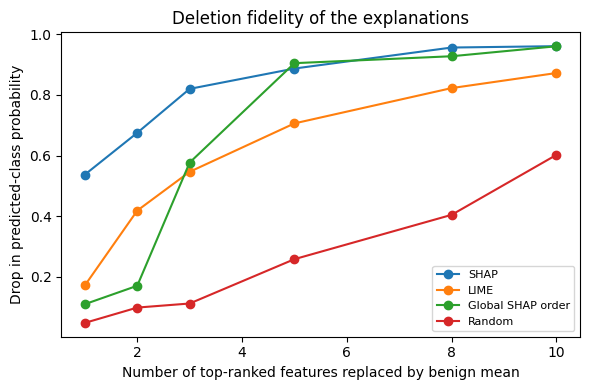


SHAP stability under N(0,0.1^2) noise (28 perturbed flows with unchanged prediction): top-5 Jaccard=0.602, Spearman=0.855

                                               Metric  Mean  CI95_low  CI95_high  Chance
                                 SHAP-LIME overlap@3 0.242     0.182      0.303   0.100
                                 SHAP-LIME overlap@5 0.273     0.218      0.324   0.167
                                SHAP-LIME overlap@10 0.387     0.353      0.418   0.333
                          SHAP-LIME Spearman(|attr|) 0.141     0.087      0.191   0.000
            SHAP-LIME sign agreement (top-5, shared) 0.880     0.844      0.913   0.500
Cluster-level overlap@3 (correlated features merged) 0.509     0.455      0.558   0.231
           LIME re-seed overlap@5 (self-consistency) 0.411     0.353      0.465   0.167
                SHAP noise stability (top-5 Jaccard) 0.602     0.519      0.687     NaN
                     SHAP noise stability (Spearman) 0.855     0.809      0.897   0

In [65]:
# 21.6  Explanation audit v2: chance-corrected agreement, cluster-level agreement, fidelity (deletion/sufficiency), stability
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

def shap_to_arr(sv):
    return np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)

p_feat = len(selected_features)
rs_e = np.random.RandomState(RANDOM_STATE)
pred_s = model.predict(X_shap_sample); att_pos = np.where(pred_s != label_map['BENIGN'])[0]
flows = []
for c in np.unique(pred_s[att_pos]):
    pc_ = att_pos[pred_s[att_pos] == c]
    flows.extend(rs_e.choice(pc_, size=min(EXPL_PER_CLASS, len(pc_)), replace=False).tolist())
flows = np.array(sorted(flows)); NF = len(flows); cls_f = pred_s[flows]
Xf = X_shap_sample.iloc[flows]; Xf_np = Xf.values
print(f"Explanation audit on {NF} predicted-attack flows from {len(np.unique(cls_f))} classes")

# correlated-feature clusters (|r| > 0.9 on average linkage) -> grouped attributions
Cm = X_train_fs.sample(min(100_000, len(X_train_fs)), random_state=RANDOM_STATE).corr().fillna(0).values
D = 1 - np.abs(Cm); np.fill_diagonal(D, 0); D = (D + D.T) / 2
clusters = fcluster(linkage(squareform(D, checks=False), method="average"), t=0.1, criterion="distance")
cl_ids = np.unique(clusters); n_cl = len(cl_ids)
print(f"{p_feat} selected features form {n_cl} clusters of mutually correlated features (|r|>0.9)")
agg = lambda v: np.array([v[clusters == g].sum() for g in cl_ids])

# SHAP and LIME (full 30-feature weight vectors) for the same flows
lime2 = LimeTabularExplainer(training_data=X_train_fs.values, feature_names=selected_features, class_names=target_names, mode='classification', random_state=7)
sv_f, lw_f, lw2_f = [], [], []
t0 = time.time()
for i, pos in enumerate(flows):
    c = int(cls_f[i]); sv_f.append(shap_arr[pos, :, c])
    for expl_, store in ((lime_explainer, lw_f), (lime2, lw2_f)):
        e_ = expl_.explain_instance(Xf_np[i], model.predict_proba, num_features=p_feat, labels=(c,), num_samples=LIME_SAMPLES)
        w_ = np.zeros(p_feat)
        for j, wt in e_.as_map()[c]: w_[j] = wt
        store.append(w_)
sv_f, lw_f, lw2_f = np.array(sv_f), np.array(lw_f), np.array(lw2_f)
print(f"LIME (x2 seeds) done in {time.time()-t0:.0f}s")

topk = lambda v, k: set(np.argsort(-np.abs(v))[:k].tolist())
ov = lambda a, b, k: len(topk(a, k) & topk(b, k)) / k
rows = []
for i in range(NF):
    r = {"cls": inv_label_map[int(cls_f[i])]}
    for k in (3, 5, 10): r[f"overlap@{k}"] = ov(sv_f[i], lw_f[i], k)
    r["spearman_abs"] = spearmanr(np.abs(sv_f[i]), np.abs(lw_f[i]))[0]
    t5 = list(topk(sv_f[i], 5)); nz = [j for j in t5 if lw_f[i][j] != 0]
    r["sign_agree@5"] = float(np.mean([np.sign(sv_f[i][j]) == np.sign(lw_f[i][j]) for j in nz])) if nz else np.nan
    r["cluster_overlap@3"] = ov(agg(sv_f[i]), agg(lw_f[i]), min(3, n_cl))
    r["lime_seed_overlap@5"] = ov(lw_f[i], lw2_f[i], 5)
    rows.append(r)
aud = pd.DataFrame(rows)
chance = {k: k / p_feat for k in (3, 5, 10)}; chance_cl = min(3, n_cl) / n_cl
rs_p = np.random.RandomState(0)
perm5 = np.mean([len(set(rs_p.permutation(p_feat)[:5]) & topk(lw_f[i], 5)) / 5 for i in range(NF) for _ in range(20)])
print(f"Chance level of overlap@k for random rankings: " + ", ".join(f"k={k}: {v:.3f}" for k, v in chance.items()) + f" | cluster-level@3: {chance_cl:.3f} | permutation check@5: {perm5:.3f}")

# Fidelity: replace the top-k features by the benign mean and measure the drop of the predicted-class probability
bg = X_train_fs[y_train == label_map['BENIGN']].mean().values
base_p = model.predict_proba(Xf)[np.arange(NF), cls_f]
glob_rank = np.argsort(-np.abs(shap_arr[np.arange(len(pred_s)), :, pred_s]).mean(0))      # global importance of predicted class
rank_sets = {"SHAP": np.argsort(-np.abs(sv_f), axis=1), "LIME": np.argsort(-np.abs(lw_f), axis=1),
             "Global SHAP order": np.tile(glob_rank, (NF, 1))}
rs_r = np.random.RandomState(3); rank_sets["Random"] = np.array([rs_r.permutation(p_feat) for _ in range(NF)])
KS = (1, 2, 3, 5, 8, 10)
def perturbed_prob(order, k, keep_top):
    Xp = Xf_np.copy()
    for i in range(NF):
        cols = order[i, :k] if not keep_top else order[i, k:]
        Xp[i, cols] = bg[cols]
    return model.predict_proba(pd.DataFrame(Xp, columns=selected_features))[np.arange(NF), cls_f]
fid = {}
for nm, order in rank_sets.items():
    comp = np.array([base_p - perturbed_prob(order, k, False) for k in KS])            # comprehensiveness (higher = better)
    suff = np.array([perturbed_prob(order, k, True) / np.maximum(base_p, 1e-9) for k in KS])  # sufficiency retention (higher = better)
    fid[nm] = dict(comp=comp, suff=suff)
fid_tbl = pd.DataFrame({nm: {"AOPC deletion (higher=better)": mean_ci(v["comp"].mean(0))[0], "Sufficiency@5 (higher=better)": v["suff"][KS.index(5)].mean(),
                             "Deletion drop @3": v["comp"][KS.index(3)].mean()} for nm, v in fid.items()}).T
print("\nFidelity (replace-by-benign-mean; caveat: perturbed inputs may be off-manifold):"); print(fid_tbl.round(4).to_string())
fid_tbl.to_csv(os.path.join(FIG_DIR, "v3_fidelity.csv"))
plt.figure(figsize=(6, 4))
for nm, v in fid.items(): plt.plot(KS, v["comp"].mean(1), "o-", label=nm)
plt.xlabel("Number of top-ranked features replaced by benign mean"); plt.ylabel("Drop in predicted-class probability"); plt.legend(fontsize=8); plt.title("Deletion fidelity of the explanations")
plt.tight_layout(); save_fig("fig_v3_deletion_fidelity"); plt.show()

# Stability of SHAP under small input noise (and LIME re-seeding, above)
SIGMA, R = 0.1, 5; rn = np.random.RandomState(1); j5, rho = [], []
for _ in range(R):
    Xn = pd.DataFrame(Xf_np + rn.normal(0, SIGMA, Xf_np.shape), columns=selected_features)
    keep = model.predict(Xn) == cls_f
    svn = shap_to_arr(explainer.shap_values(Xn))
    for i in np.where(keep)[0]:
        v = svn[i, :, int(cls_f[i])]
        j5.append(len(topk(v, 5) & topk(sv_f[i], 5)) / len(topk(v, 5) | topk(sv_f[i], 5))); rho.append(spearmanr(np.abs(v), np.abs(sv_f[i]))[0])
print(f"\nSHAP stability under N(0,{SIGMA}^2) noise ({len(j5)} perturbed flows with unchanged prediction): top-5 Jaccard={np.mean(j5):.3f}, Spearman={np.mean(rho):.3f}")

def row_ci(name, v, chance_v=None):
    m, (l, h) = mean_ci(v); return {"Metric": name, "Mean": m, "CI95_low": l, "CI95_high": h, "Chance": chance_v}
audit_tbl = pd.DataFrame([
    row_ci("SHAP-LIME overlap@3", aud["overlap@3"], chance[3]), row_ci("SHAP-LIME overlap@5", aud["overlap@5"], chance[5]),
    row_ci("SHAP-LIME overlap@10", aud["overlap@10"], chance[10]), row_ci("SHAP-LIME Spearman(|attr|)", aud["spearman_abs"], 0.0),
    row_ci("SHAP-LIME sign agreement (top-5, shared)", aud["sign_agree@5"], 0.5), row_ci("Cluster-level overlap@3 (correlated features merged)", aud["cluster_overlap@3"], chance_cl),
    row_ci("LIME re-seed overlap@5 (self-consistency)", aud["lime_seed_overlap@5"], chance[5]),
    row_ci("SHAP noise stability (top-5 Jaccard)", j5), row_ci("SHAP noise stability (Spearman)", rho, 0.0)])
print("\n", audit_tbl.round(3).to_string(index=False)); audit_tbl.to_csv(os.path.join(FIG_DIR, "v3_explanation_audit.csv"), index=False)
aud.to_csv(os.path.join(FIG_DIR, "v3_explanation_audit_per_flow.csv"), index=False)
RESULTS_V3["explanation_audit"] = audit_tbl.to_dict(orient="records"); RESULTS_V3["fidelity"] = fid_tbl.reset_index().to_dict(orient="records")
RESULTS_V3["n_feature_clusters"] = int(n_cl); RESULTS_V3["n_audit_flows"] = int(NF)

### 21.7 Constrained counterfactuals
Why: the v2 search changes 10 features at once, may change the destination port and has no plausibility check. v3 freezes `Destination Port` (the attacker's target), keeps features inside the benign 1–99 % range, **prunes** the solution to a minimal change set and checks **plausibility** with a kNN distance to benign flows. Reported: validity, L1/L2 proximity, sparsity, immutable-feature violations, plausibility.

In [66]:
# 21.7  Constrained counterfactuals: immutable port, benign-range bounds, pruning to minimal change, plausibility check
from sklearn.neighbors import NearestNeighbors
benign_idx_ = label_map['BENIGN']; Xb_ref = X_train_fs[y_train == benign_idx_]
lo_b, hi_b = Xb_ref.quantile(0.01), Xb_ref.quantile(0.99); mu_b = Xb_ref.mean()
IMMUTABLE = ['Destination Port']                       # the attacker's target service cannot be changed to evade detection
ref_s = Xb_ref.sample(min(40_000, len(Xb_ref)), random_state=1)
nn_ref, nn_eval = ref_s.iloc[:-2000], ref_s.iloc[-2000:]
nn = NearestNeighbors(n_neighbors=5).fit(nn_ref.values)
d_ben = nn.kneighbors(nn_eval.values)[0].mean(1); PLAUS_THR = float(np.percentile(d_ben, 95))
plaus = lambda x: float(nn.kneighbors(np.asarray(x, float).reshape(1, -1))[0].mean())
print(f"Plausibility threshold (95th pct of benign-to-benign kNN distance): {PLAUS_THR:.3f}")

def cf_constrained(row, target, top_k=5, step=0.25, max_iter=80, p_min=0.5, prune=True):
    x = row.copy(); mutable = [c for c in x.index if c not in IMMUTABLE]
    ok = lambda v: (lambda pr: pr.argmax() == target and pr[target] >= p_min)(model.predict_proba(v.to_frame().T)[0])
    it = 0
    while it < max_iter and not ok(x):
        gap = (mu_b[mutable] - x[mutable]).abs().sort_values(ascending=False); feats = gap.index[:top_k]
        for f in feats: x[f] = float(np.clip(x[f] + step * (mu_b[f] - x[f]), lo_b[f], hi_b[f]))
        it += 1
    success = ok(x)
    if success and prune:                                # greedy pruning: revert the smallest changes while the counterfactual stays valid
        for f in (x - row).abs().sort_values().index:
            if abs(x[f] - row[f]) > 1e-9:
                old = x[f]; x[f] = row[f]
                if not ok(x): x[f] = old
    return x, success, it

def cf_metrics(orig, cf, success):
    d = cf - orig
    return dict(valid=bool(success), L1=float(d.abs().sum()), L2=float(np.linalg.norm(d.values)), sparsity=int((d.abs() > 1e-6).sum()),
                port_changed=bool(abs(d.get('Destination Port', 0.0)) > 1e-6), plausible=bool(plaus(cf.values) <= PLAUS_THR),
                benign_prob=float(model.predict_proba(cf.to_frame().T)[0][benign_idx_]))
cf_rows = []
t0 = time.time()
for i, pos in enumerate(flows):
    row = Xf.iloc[i]
    cu, su, nu, _ = generate_counterfactual(model, Xf.iloc[[i]], Xb_ref, target_class=benign_idx_, max_iter=60)
    cc, sc_, nc = cf_constrained(row, benign_idx_)
    cf_rows.append({"cls": inv_label_map[int(cls_f[i])], "method": "greedy (v2, unconstrained)", **cf_metrics(row, cu.iloc[0], su)})
    cf_rows.append({"cls": inv_label_map[int(cls_f[i])], "method": "constrained + pruned (v3)", **cf_metrics(row, cc, sc_)})
cfd = pd.DataFrame(cf_rows)
cf_tbl = cfd.groupby("method").agg(validity=("valid", "mean"), L1=("L1", "median"), L2=("L2", "median"), sparsity=("sparsity", "median"),
                                    port_changed=("port_changed", "mean"), plausible=("plausible", "mean"), benign_prob=("benign_prob", "median"))
print(f"({time.time()-t0:.0f}s)"); print(cf_tbl.round(3).to_string()); cf_tbl.to_csv(os.path.join(FIG_DIR, "v3_counterfactual_comparison.csv")); cfd.to_csv(os.path.join(FIG_DIR, "v3_counterfactual_per_flow.csv"), index=False)
RESULTS_V3["counterfactual_comparison"] = cf_tbl.reset_index().to_dict(orient="records")

Plausibility threshold (95th pct of benign-to-benign kNN distance): 0.660
(15s)
                            validity     L1     L2  sparsity  port_changed  plausible  benign_prob
method                                                                                            
constrained + pruned (v3)        1.0  1.086  0.905       2.0         0.000      0.273        0.699
greedy (v2, unconstrained)       1.0  5.621  1.820      10.0         0.182      0.000        0.985


### 21.8 Tabular Transformer (FT-Transformer style) and Integrated Gradients
Why: the project brief requires a Transformer. The CSV has no IPs or timestamps, so a *sequence* Transformer is impossible, but a **feature-token Transformer** (Gorishniy et al., 2021) can be trained on the same 30 features and compared with XGBoost with the same paired-bootstrap protocol. Integrated Gradients (baseline = benign mean) explains it; completeness is checked and IG is compared with SHAP(XGBoost) and with a random ranking. Requires PyTorch (`pip install torch`); the cell is skipped otherwise. The GNN is *not* implemented here: it needs host/IP information (see the roadmap).

In [67]:
# 21.8  Tabular Transformer (FT-Transformer style) + Integrated Gradients, compared with XGBoost on the same split
try:
    import torch, torch.nn as nn
    HAVE_TORCH = True
except Exception as e:
    HAVE_TORCH = False; print("PyTorch not available -> section skipped. Install with: pip install torch  (", e, ")")

if HAVE_TORCH:
    torch.manual_seed(RANDOM_STATE); np.random.seed(RANDOM_STATE)
    DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("device:", DEV)

    class FTTransformer(nn.Module):
        """Feature tokenizer (one learned affine embedding per feature) + [CLS] token + pre-norm Transformer encoder."""
        def __init__(self, n_feat, n_cls, d=32, heads=4, layers=2, ff=64, drop=0.1):
            super().__init__()
            self.W = nn.Parameter(torch.randn(n_feat, d) * 0.1); self.b = nn.Parameter(torch.zeros(n_feat, d))
            self.cls = nn.Parameter(torch.zeros(1, 1, d))
            layer = nn.TransformerEncoderLayer(d, heads, ff, drop, batch_first=True, norm_first=True)
            self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
            self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, n_cls))
        def forward(self, x):
            tok = x.unsqueeze(-1) * self.W + self.b                  # (B, n_feat, d)
            h = self.enc(torch.cat([self.cls.expand(len(x), -1, -1), tok], dim=1))
            return self.head(h[:, 0])

    sub_dl = stratified_fraction(y_train_bal, min(1.0, DL_TRAIN_ROWS / len(y_train_bal)), seed=RANDOM_STATE)
    Xd = torch.tensor(X_train_bal.iloc[sub_dl].values, dtype=torch.float32); yd = torch.tensor(np.asarray(y_train_bal)[sub_dl], dtype=torch.long)
    wd = torch.tensor(w_bal[sub_dl], dtype=torch.float32)
    Xd = torch.clamp(Xd, -10, 10)                                   # guard against extreme standardised values
    ft = FTTransformer(len(selected_features), K).to(DEV)
    opt = torch.optim.AdamW(ft.parameters(), lr=1e-3, weight_decay=1e-4)
    n_steps = DL_EPOCHS * math.ceil(len(Xd) / 1024); sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=n_steps)
    lossf = nn.CrossEntropyLoss(reduction="none"); t0 = time.time()
    for ep in range(DL_EPOCHS):
        ft.train(); perm = torch.randperm(len(Xd)); tot = 0.0
        for s in range(0, len(Xd), 1024):
            bi = perm[s:s + 1024]; xb_, yb_t, wb_t = Xd[bi].to(DEV), yd[bi].to(DEV), wd[bi].to(DEV)
            opt.zero_grad(); loss = (lossf(ft(xb_), yb_t) * wb_t).mean(); loss.backward()
            nn.utils.clip_grad_norm_(ft.parameters(), 1.0); opt.step(); sched.step(); tot += float(loss) * len(bi)
        print(f"epoch {ep+1}/{DL_EPOCHS}  train loss {tot/len(Xd):.4f}  ({time.time()-t0:.0f}s)")
    ft.eval()
    def ft_proba(Xdf, bs=8192):
        out = []
        with torch.no_grad():
            for s in range(0, len(Xdf), bs):
                xb_ = torch.clamp(torch.tensor(np.asarray(Xdf)[s:s + bs], dtype=torch.float32), -10, 10).to(DEV)
                out.append(torch.softmax(ft(xb_), -1).cpu().numpy())
        return np.vstack(out)
    P_ft = ft_proba(X_test_fs); y_pred_ft = P_ft.argmax(1)
    s_ft = scores_from_cm(cm_fast(y_te, y_pred_ft))
    dl_tbl = pd.DataFrame([
        {"Model": "XGBoost", "Accuracy": scores_from_cm(cm_fast(y_te, P_main["XGBoost"]))["acc"], "Macro-F1": scores_from_cm(cm_fast(y_te, P_main["XGBoost"]))["macro_f1"], "MCC": matthews_corrcoef(y_te, P_main["XGBoost"]), "ECE": ece_score(y_proba, y_te)},
        {"Model": "Tabular Transformer (FT-style)", "Accuracy": s_ft["acc"], "Macro-F1": s_ft["macro_f1"], "MCC": matthews_corrcoef(y_te, y_pred_ft), "ECE": ece_score(P_ft, y_te)}])
    print(dl_tbl.round(4).to_string(index=False)); dl_tbl.to_csv(os.path.join(FIG_DIR, "v3_transformer_vs_xgb.csv"), index=False)
    # paired bootstrap of the F1 difference (Transformer - XGBoost)
    rs_t = np.random.RandomState(5); dd = []
    for b in range(BOOT_B):
        ii = rs_t.randint(0, n_te, n_te); dd.append(scores_from_cm(cm_fast(y_te[ii], y_pred_ft[ii]))["macro_f1"] - scores_from_cm(cm_fast(y_te[ii], P_main["XGBoost"][ii]))["macro_f1"])
    print(f"Delta macro-F1 (Transformer - XGBoost) = {np.mean(dd):+.3f}  95% CI [{np.percentile(dd, 2.5):+.3f}, {np.percentile(dd, 97.5):+.3f}]")
    RESULTS_V3["transformer_vs_xgb"] = dict(table=dl_tbl.to_dict(orient="records"), delta_f1_mean=float(np.mean(dd)), delta_f1_ci=[float(np.percentile(dd, 2.5)), float(np.percentile(dd, 97.5))], epochs=DL_EPOCHS, train_rows=int(len(Xd)))

    # ---- Integrated Gradients (baseline = benign mean) on the audit flows, with a completeness check
    bg_t = torch.tensor(bg, dtype=torch.float32, device=DEV)
    def integrated_gradients(x_np, target, steps=48):
        x = torch.clamp(torch.tensor(x_np, dtype=torch.float32, device=DEV), -10, 10)
        al = torch.linspace(0, 1, steps, device=DEV).view(-1, 1); xs = (bg_t + al * (x - bg_t)).requires_grad_(True)
        out = torch.softmax(ft(xs), -1)[:, target].sum(); g = torch.autograd.grad(out, xs)[0]
        att = ((x - bg_t) * g.mean(0)).detach().cpu().numpy()
        with torch.no_grad(): delta = float(torch.softmax(ft(x[None]), -1)[0, target] - torch.softmax(ft(bg_t[None]), -1)[0, target])
        return att, delta
    pred_ft_f = ft_proba(Xf).argmax(1); same = pred_ft_f == cls_f
    ig_all, comp_err = [], []
    for i in range(NF):
        a_, d_ = integrated_gradients(Xf_np[i], int(pred_ft_f[i])); ig_all.append(a_); comp_err.append(abs(a_.sum() - d_))
    ig_all = np.array(ig_all)
    print(f"IG completeness |sum(attr) - (f(x)-f(baseline))|: median {np.median(comp_err):.4f}, max {np.max(comp_err):.4f}")
    ov_x = [ov(ig_all[i], sv_f[i], 5) for i in np.where(same)[0]]
    print(f"Cross-model agreement on {same.sum()} flows both models label identically: IG(Transformer) vs SHAP(XGBoost) overlap@5 = {np.mean(ov_x):.3f} (chance {5/p_feat:.3f})")
    # fidelity of IG on the Transformer itself (deletion with benign mean) vs random ranking
    base_ft = ft_proba(Xf)[np.arange(NF), pred_ft_f]
    def ft_drop(order, k):
        Xp = Xf_np.copy()
        for i in range(NF): Xp[i, order[i, :k]] = bg[order[i, :k]]
        return base_ft - ft_proba(pd.DataFrame(Xp, columns=selected_features))[np.arange(NF), pred_ft_f]
    ig_rank = np.argsort(-np.abs(ig_all), axis=1); rnd_rank = np.array([rs_r.permutation(p_feat) for _ in range(NF)])
    aopc_ig = np.mean([ft_drop(ig_rank, k).mean() for k in KS]); aopc_rd = np.mean([ft_drop(rnd_rank, k).mean() for k in KS])
    print(f"Deletion AOPC on the Transformer: IG = {aopc_ig:.4f} vs random = {aopc_rd:.4f}")
    RESULTS_V3["integrated_gradients"] = dict(completeness_median=float(np.median(comp_err)), cross_model_overlap5=float(np.mean(ov_x)), aopc_ig=float(aopc_ig), aopc_random=float(aopc_rd))
else:
    RESULTS_V3["transformer_vs_xgb"] = "skipped (PyTorch not installed)"

device: cpu
epoch 1/10  train loss 0.6592  (112s)
epoch 2/10  train loss 0.1262  (226s)
epoch 3/10  train loss 0.0826  (337s)
epoch 4/10  train loss 0.0703  (449s)
epoch 5/10  train loss 0.0614  (565s)
epoch 6/10  train loss 0.0545  (671s)
epoch 7/10  train loss 0.0495  (770s)
epoch 8/10  train loss 0.0477  (869s)
epoch 9/10  train loss 0.0435  (977s)
epoch 10/10  train loss 0.0417  (1085s)
                         Model  Accuracy  Macro-F1    MCC    ECE
                       XGBoost    0.9982    0.8336 0.9942 0.0005
Tabular Transformer (FT-style)    0.9922    0.6697 0.9750 0.0024
Delta macro-F1 (Transformer - XGBoost) = -0.153  95% CI [-0.215, -0.099]
IG completeness |sum(attr) - (f(x)-f(baseline))|: median 0.0308, max 0.5452
Cross-model agreement on 53 flows both models label identically: IG(Transformer) vs SHAP(XGBoost) overlap@5 = 0.185 (chance 0.167)
Deletion AOPC on the Transformer: IG = 0.8444 vs random = 0.5721


### 21.9 Cross-dataset evaluation (optional but strongly recommended)
Why: near-perfect in-dataset scores that collapse across datasets are a documented problem for CIC-IDS2017/2018 (Cantone et al., IEEE Access 2024; Şengül & Kılıç, IEEE Access 2026). Download *CSE-CIC-IDS2018 – Processed Traffic Data for ML Algorithms*, set `XTHREAT_DATA_DIR_2018` to the folder and re-run this cell. No retraining: the 2017 imputer, scaler, feature list and models are applied. **Check the printed list of unmapped columns against your CSV headers** — the rename map in this cell is a best effort.

In [68]:
# 21.9  OPTIONAL cross-dataset evaluation: train on CIC-IDS2017 (above), test on CSE-CIC-IDS2018 without any retraining
# Set the environment variable XTHREAT_DATA_DIR_2018 to the folder with the CSE-CIC-IDS2018 "Processed Traffic Data for ML" CSV files.
DIR_2018 = os.environ.get("XTHREAT_DATA_DIR_2018", "")
COL_2018 = {'Dst Port': 'Destination Port', 'Tot Fwd Pkts': 'Total Fwd Packets', 'Tot Bwd Pkts': 'Total Backward Packets',
 'TotLen Fwd Pkts': 'Total Length of Fwd Packets', 'TotLen Bwd Pkts': 'Total Length of Bwd Packets',
 'Fwd Pkt Len Max': 'Fwd Packet Length Max', 'Fwd Pkt Len Min': 'Fwd Packet Length Min', 'Fwd Pkt Len Mean': 'Fwd Packet Length Mean', 'Fwd Pkt Len Std': 'Fwd Packet Length Std',
 'Bwd Pkt Len Max': 'Bwd Packet Length Max', 'Bwd Pkt Len Min': 'Bwd Packet Length Min', 'Bwd Pkt Len Mean': 'Bwd Packet Length Mean', 'Bwd Pkt Len Std': 'Bwd Packet Length Std',
 'Flow Byts/s': 'Flow Bytes/s', 'Flow Pkts/s': 'Flow Packets/s', 'Fwd IAT Tot': 'Fwd IAT Total', 'Bwd IAT Tot': 'Bwd IAT Total',
 'Fwd Header Len': 'Fwd Header Length', 'Bwd Header Len': 'Bwd Header Length', 'Fwd Pkts/s': 'Fwd Packets/s', 'Bwd Pkts/s': 'Bwd Packets/s',
 'Pkt Len Min': 'Min Packet Length', 'Pkt Len Max': 'Max Packet Length', 'Pkt Len Mean': 'Packet Length Mean', 'Pkt Len Std': 'Packet Length Std', 'Pkt Len Var': 'Packet Length Variance',
 'FIN Flag Cnt': 'FIN Flag Count', 'SYN Flag Cnt': 'SYN Flag Count', 'RST Flag Cnt': 'RST Flag Count', 'PSH Flag Cnt': 'PSH Flag Count', 'ACK Flag Cnt': 'ACK Flag Count',
 'URG Flag Cnt': 'URG Flag Count', 'ECE Flag Cnt': 'ECE Flag Count', 'Pkt Size Avg': 'Average Packet Size', 'Fwd Seg Size Avg': 'Avg Fwd Segment Size', 'Bwd Seg Size Avg': 'Avg Bwd Segment Size',
 'Fwd Byts/b Avg': 'Fwd Avg Bytes/Bulk', 'Fwd Pkts/b Avg': 'Fwd Avg Packets/Bulk', 'Fwd Blk Rate Avg': 'Fwd Avg Bulk Rate',
 'Bwd Byts/b Avg': 'Bwd Avg Bytes/Bulk', 'Bwd Pkts/b Avg': 'Bwd Avg Packets/Bulk', 'Bwd Blk Rate Avg': 'Bwd Avg Bulk Rate',
 'Subflow Fwd Pkts': 'Subflow Fwd Packets', 'Subflow Fwd Byts': 'Subflow Fwd Bytes', 'Subflow Bwd Pkts': 'Subflow Bwd Packets', 'Subflow Bwd Byts': 'Subflow Bwd Bytes',
 'Init Fwd Win Byts': 'Init_Win_bytes_forward', 'Init Bwd Win Byts': 'Init_Win_bytes_backward', 'Fwd Act Data Pkts': 'act_data_pkt_fwd', 'Fwd Seg Size Min': 'min_seg_size_forward'}
LAB_2018 = {'benign': 'BENIGN', 'bot': 'Bot', 'ftp-bruteforce': 'FTP-Patator', 'ssh-bruteforce': 'SSH-Patator', 'dos attacks-goldeneye': 'DoS GoldenEye',
 'dos attacks-slowloris': 'DoS slowloris', 'dos attacks-hulk': 'DoS Hulk', 'dos attacks-slowhttptest': 'DoS Slowhttptest', 'ddos attacks-loic-http': 'DDoS',
 'ddos attack-hoic': 'DDoS', 'ddos attack-loic-udp': 'DDoS', 'brute force -web': 'Web Attack - Brute Force', 'brute force -xss': 'Web Attack - XSS',
 'sql injection': 'Web Attack - Sql Injection', 'infilteration': 'Infiltration', 'infiltration': 'Infiltration'}

if not DIR_2018:
    print("XTHREAT_DATA_DIR_2018 is not set -> cross-dataset section skipped (this is optional but strongly recommended for a Q1 submission).")
    RESULTS_V3["cross_dataset"] = "skipped (XTHREAT_DATA_DIR_2018 not set)"
else:
    PER_CLASS_CAP = 3_000 if FAST else 30_000
    parts = []
    for f in sorted(glob.glob(os.path.join(DIR_2018, "*.csv"))):
        d2 = pd.read_csv(f, low_memory=False); d2.columns = d2.columns.str.strip()
        d2 = d2[d2['Label'].astype(str).str.strip().str.lower() != 'label']            # repeated header rows occur in some 2018 files
        d2 = d2.rename(columns=COL_2018); d2['Label'] = d2['Label'].astype(str).str.strip().str.lower().map(LAB_2018)
        d2 = d2.dropna(subset=['Label'])
        parts.append(pd.concat([g.sample(min(len(g), PER_CLASS_CAP), random_state=RANDOM_STATE) for _, g in d2.groupby('Label')])); print(os.path.basename(f), len(d2), "mapped rows")
    d18 = pd.concat(parts, ignore_index=True); del parts; gc.collect()
    raw_cols = [c for c in df.columns if c not in ['Label', 'Label_enc', 'Binary_Label', 'SourceDay', 'Fwd_Bwd_Pkt_Ratio', 'Bytes_per_Packet', 'Fwd_Bwd_Byte_Ratio', 'Flag_Sum', 'Is_WellKnown_Port']]
    miss_cols = [c for c in raw_cols if c not in d18.columns]
    print(f"Target rows: {len(d18):,} | raw feature columns missing after renaming: {miss_cols}")
    for c in raw_cols:
        d18[c] = pd.to_numeric(d18[c], errors='coerce') if c in d18.columns else np.nan
    d18[raw_cols] = d18[raw_cols].replace([np.inf, -np.inf], np.nan)
    d18 = d18[~(d18[[c for c in invalid_time_cols if c in d18.columns]] < 0).any(axis=1)].reset_index(drop=True)
    d18['Fwd_Bwd_Pkt_Ratio'] = d18['Total Fwd Packets'] / (d18['Total Backward Packets'] + 1)
    d18['Bytes_per_Packet'] = (d18['Total Length of Fwd Packets'] + d18['Total Length of Bwd Packets']) / (d18['Total Fwd Packets'] + d18['Total Backward Packets'] + 1)
    d18['Fwd_Bwd_Byte_Ratio'] = d18['Total Length of Fwd Packets'] / (d18['Total Length of Bwd Packets'] + 1)
    d18['Flag_Sum'] = d18[['FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count']].sum(axis=1)
    d18['Is_WellKnown_Port'] = (d18['Destination Port'] <= 1023).astype(int)
    X18 = d18[feature_cols].copy(); y18 = d18['Label'].map(label_map).astype(int).values
    X18[log_candidates] = np.log1p(X18[log_candidates].clip(lower=0))
    X18_s = pd.DataFrame(scaler.transform(imputer_final.transform(X18)), columns=feature_cols, index=X18.index)
    present18 = np.unique(y18); print("Classes present in target:", [inv_label_map[c] for c in present18])

    def eval_target(m, cols, tag):
        P = m.predict_proba(X18_s[cols]); p = P.argmax(1)
        f1m = f1_score(y18, p, labels=list(present18), average="macro", zero_division=0)
        bin_t, bin_p = (y18 != label_map['BENIGN']).astype(int), (p != label_map['BENIGN']).astype(int)
        tp_, fp_ = int(((bin_t == 1) & (bin_p == 1)).sum()), int(((bin_t == 0) & (bin_p == 1)).sum()); fn_, tn_ = int(((bin_t == 1) & (bin_p == 0)).sum()), int(((bin_t == 0) & (bin_p == 0)).sum())
        rec = {inv_label_map[c]: float((p[y18 == c] == c).mean()) for c in present18}
        return dict(setting=tag, accuracy=float((p == y18).mean()), macro_f1=float(f1m), MCC=float(matthews_corrcoef(y18, p)), binary_F1=2 * tp_ / max(1, 2 * tp_ + fp_ + fn_),
                    false_alarm_rate=fp_ / max(1, fp_ + tn_), miss_rate=fn_ / max(1, fn_ + tp_), ECE=ece_score(P, y18), per_class_recall=rec)
    res_x = [eval_target(model, selected_features, "XGBoost (all 30 features)"), eval_target(m_np, no_port_cols, "XGBoost (no port features)")]
    xt = pd.DataFrame([{k: v for k, v in r.items() if k != "per_class_recall"} for r in res_x]); print(xt.round(4).to_string(index=False))
    pcr_18 = pd.DataFrame({r["setting"]: r["per_class_recall"] for r in res_x}); print(pcr_18.round(3).to_string()); pcr_18.to_csv(os.path.join(FIG_DIR, "v3_cross_dataset_per_class_recall.csv"))
    print("\nIn-domain reference (CIC-IDS2017 random split): macro-F1 =", round(float(RESULTS.get('train_test_gap', {}).get('test_macro_f1', np.nan)), 4))
    xt.to_csv(os.path.join(FIG_DIR, "v3_cross_dataset.csv"), index=False); RESULTS_V3["cross_dataset"] = [{k: v for k, v in r.items()} for r in res_x]

XTHREAT_DATA_DIR_2018 is not set -> cross-dataset section skipped (this is optional but strongly recommended for a Q1 submission).


### 21.10 Export of all v3 numbers

In [69]:
# 21.10  Export every v3 number for the paper
def _js2(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (set, tuple)): return list(o)
    return str(o)
with open(os.path.join(FIG_DIR, "results_summary_v3.json"), "w") as f:
    json.dump(RESULTS_V3, f, indent=2, default=_js2)
print("v3 results saved to figures/results_summary_v3.json; sections present:", sorted(RESULTS_V3))
print("v3 files:", sorted(x for x in os.listdir(FIG_DIR) if x.startswith(("v3_", "fig_v3_"))))

v3 results saved to figures/results_summary_v3.json; sections present: ['calibration', 'conformal', 'counterfactual_comparison', 'cross_dataset', 'explanation_audit', 'feature_selection_stability', 'fidelity', 'group_split', 'imbalance_ablation', 'integrated_gradients', 'multiseed_summary', 'n_audit_flows', 'n_feature_clusters', 'near_duplicate_leakage_overall', 'paired_bootstrap', 'transformer_vs_xgb']
v3 files: ['fig_v3_deletion_fidelity.pdf', 'fig_v3_deletion_fidelity.png', 'fig_v3_reliability.pdf', 'fig_v3_reliability.png', 'v3_calibration.csv', 'v3_conformal_per_class_coverage.csv', 'v3_conformal_summary.csv', 'v3_counterfactual_comparison.csv', 'v3_counterfactual_per_flow.csv', 'v3_explanation_audit.csv', 'v3_explanation_audit_per_flow.csv', 'v3_fidelity.csv', 'v3_group_split.csv', 'v3_imbalance_ablation.csv', 'v3_multiseed_per_class.csv', 'v3_multiseed_runs.csv', 'v3_multiseed_summary.csv', 'v3_near_duplicate_leakage.csv', 'v3_paired_bootstrap.csv', 'v3_transformer_vs_xgb.csv']


## 22. Publication-quality figures (Q1 figure set)
Run **after Section 21** (the figures read its variables and `figures/v3_*.csv`). Every figure is saved as a 300-dpi PNG and a vector PDF in `figures/` (`fig_pub_*`). Design rules: colour-blind-safe Okabe–Ito palette, one colour per attack family, constrained layout (no overlapping labels), uncertainty shown wherever a number is estimated, and a "chance / reference" marker wherever a score needs one. A figure is skipped with a message (never an error) if its inputs were not produced.

| Figure | Reviewer question it answers | Claim it supports |
|---|---|---|
| A (22.1) | Which classes work, and how reliable is each estimate? | High aggregate scores hide scarce classes; CIs and support are shown together |
| B (22.2) | Are model differences real? | Paired CIs, seed spread, Transformer baseline |
| C (22.3) | Where exactly does the model fail? | Error routes, e.g. rare attacks absorbed into BENIGN |
| D (22.4) | Is the reported confidence trustworthy? | Temperature scaling lowers ECE; risk–coverage curve |
| E (22.5) | Can an analyst rely on uncertainty sets? | Per-class conformal coverage and set sizes |
| F (22.6) | Is it usable in a SOC? | Detection rate at a fixed false-alarm budget |
| G (22.7) | Are the explanations trustworthy? | Agreement beyond chance, deletion fidelity, per-class consistency |
| H (22.8) | When do SHAP and LIME disagree? | Case-level rank comparison |
| I (22.9) | Does the full required pipeline work end to end? | Attack → Why → Evidence → Features → Behaviour → Confidence → Response |
| J (22.10) | Are counterfactuals actionable? | Constrained search keeps the port fixed and changes fewer features |
| K (22.10) | Is the protocol leakage-safe? | Imbalance ablation, group split, near-duplicate audit |
| L (22.11) | Does it generalise? | Train 2017 → test 2018, with/without port features |
| M (22.11) | Is it deployable? | Latency of detection vs explanation |

In [70]:
# 22.0  Publication figure style, colour system and helpers (all figures below share them)
import re
import textwrap
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, Rectangle
import matplotlib.ticker as mtick

# Okabe-Ito colour-blind-safe palette (distinguishable in greyscale print as well)
C = dict(blue="#0072B2", verm="#D55E00", green="#009E73", orange="#E69F00", sky="#56B4E9", purple="#CC79A7",
         ink="#1F2937", grey="#6B7280", light="#E5E7EB", paper="#FFFFFF")
CMAP_SEQ = LinearSegmentedColormap.from_list("xt_seq", ["#F7FBFF", "#C6DBEF", "#6BAED6", "#2171B5", "#08306B"])
CMAP_DIV = LinearSegmentedColormap.from_list("xt_div", [C["blue"], "#F5F5F5", C["verm"]])
CMAP_QUAL = LinearSegmentedColormap.from_list("xt_good", ["#FBE9E0", "#F6C9A8", "#F2EBC0", "#9ED3C0", "#00806A"])  # bad -> good

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "axes.labelcolor": C["ink"], "xtick.labelsize": 8, "ytick.labelsize": 8, "text.color": C["ink"],
    "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": C["light"], "grid.linewidth": 0.7, "legend.frameon": False, "legend.fontsize": 8,
    "xtick.color": C["ink"], "ytick.color": C["ink"], "pdf.fonttype": 42, "ps.fonttype": 42, "figure.constrained_layout.use": True,
    "figure.constrained_layout.h_pad": 0.08, "figure.constrained_layout.w_pad": 0.08})

import re
def short(s):
    """Compact class names for tick labels; robust to the mis-decoded dash in the CIC web-attack labels."""
    m = re.match(r"^Web Attack\W+(.*)$", str(s))
    if m: return "Web: " + m.group(1).replace("Sql Injection", "SQL Injection")
    return str(s)
def _family_rank(n):
    n_ = n.lower()
    for r, key in enumerate(["benign", "ddos", "dos", "patator", "web", "bot", "infil", "portscan", "heartbleed"]):
        if key in n_: return r
    return 99
CLASS_ORDER = sorted(range(K), key=lambda k: (_family_rank(target_names[k]), target_names[k]))   # families grouped: DoS -> brute force -> web -> others
FAMILY_COLOR = {"benign": C["grey"], "ddos": C["blue"], "dos": C["blue"], "patator": C["green"], "web": C["verm"], "bot": C["purple"],
                "infil": C["orange"], "portscan": C["sky"], "heartbleed": C["ink"]}
def fam_color(n):
    for key, col in FAMILY_COLOR.items():
        if key in n.lower(): return col
    return C["grey"]

def save_pub(fig, name):
    """Save PNG (300 dpi) + vector PDF and show."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=300, bbox_inches="tight", facecolor="white")
    fig.savefig(os.path.join(FIG_DIR, name + ".pdf"), bbox_inches="tight", facecolor="white")
    plt.show(); plt.close(fig)

def ptitle(ax, letter, text):
    ax.set_title(f"({letter}) {text}", loc="left", pad=6)
def clean(ax, grid="x"):
    ax.tick_params(length=3, width=0.8)
    if grid: ax.grid(axis=grid, zorder=0); ax.set_axisbelow(True)
def boxlabel(ax, text, loc=(0.97, 0.05), ha="right", va="bottom", fs=8):
    ax.text(*loc, text, transform=ax.transAxes, ha=ha, va=va, fontsize=fs, color=C["ink"],
            bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#9CA3AF", lw=0.7, alpha=0.95), zorder=10)
def need(*names):
    miss = [n for n in names if n not in globals()]
    if miss: print("  skipped (run the earlier cells first; missing:", ", ".join(miss) + ")"); return False
    return True
def read_csv_safe(name, **kw):
    p = os.path.join(FIG_DIR, name)
    if not os.path.exists(p): print(f"  skipped ({name} not found - run its section first)"); return None
    return pd.read_csv(p, **kw)
print("Figure style ready. Palette:", {k: v for k, v in C.items() if k not in ("paper",)})

Figure style ready. Palette: {'blue': '#0072B2', 'verm': '#D55E00', 'green': '#009E73', 'orange': '#E69F00', 'sky': '#56B4E9', 'purple': '#CC79A7', 'ink': '#1F2937', 'grey': '#6B7280', 'light': '#E5E7EB'}


### 22.1 Figure A – per-class F1 with bootstrap CIs and test support

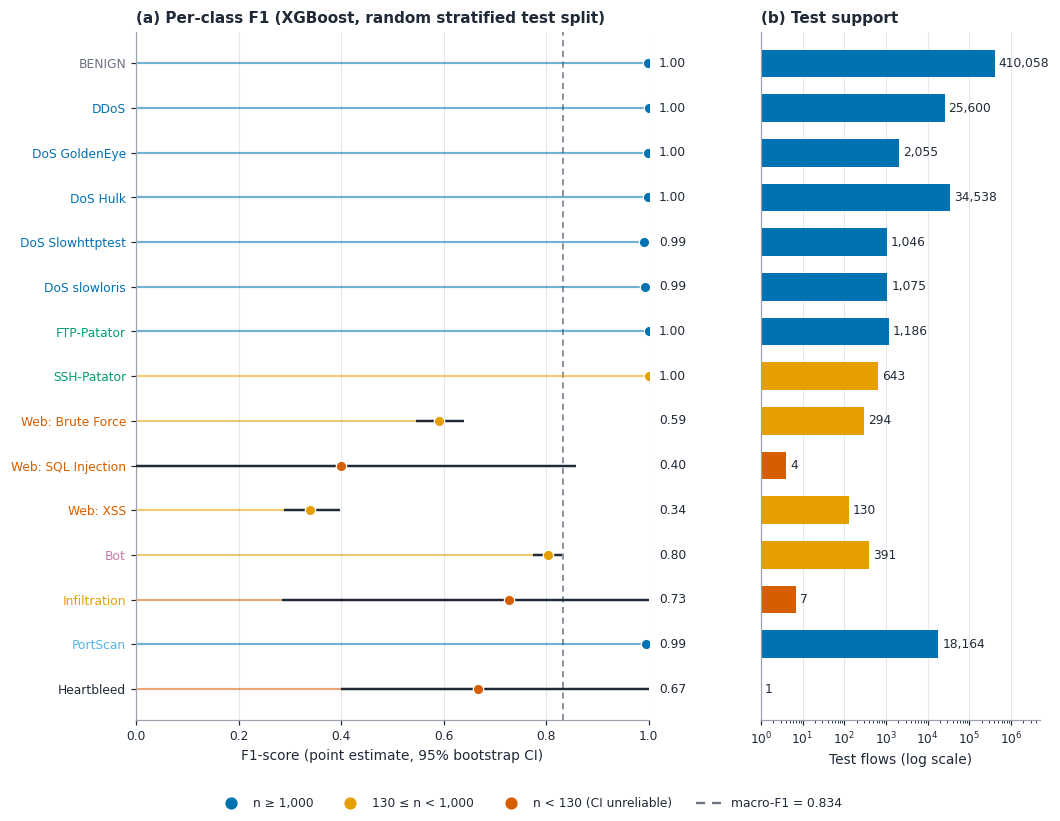

In [71]:
# 22.1  Figure A - per-class performance with bootstrap CIs, shown next to the test support (data scarcity vs. separability)
if need("y_test", "y_pred", "target_names"):
    yt_, yp_ = np.asarray(y_test), np.asarray(y_pred); rs_ = np.random.RandomState(7)
    B_ = min(BOOT_B, 400); f1_bs = np.full((B_, K), np.nan)
    for b in range(B_):
        ix = rs_.randint(0, len(yt_), len(yt_)); cm_b = cm_fast(yt_[ix], yp_[ix]); sc_b = scores_from_cm(cm_b)
        f1_bs[b] = np.where(cm_b.sum(1) > 0, sc_b["f1"], np.nan)
    f1_pt = scores_from_cm(cm_fast(yt_, yp_))["f1"]; sup = np.bincount(yt_, minlength=K)
    lo_, hi_ = np.nanpercentile(f1_bs, 2.5, axis=0), np.nanpercentile(f1_bs, 97.5, axis=0)
    order = [k for k in CLASS_ORDER if sup[k] > 0][::-1]          # top-to-bottom = family order
    tier = lambda n: C["blue"] if n >= 1000 else (C["orange"] if n >= 130 else C["verm"])
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 0.36 * len(order) + 2.0), sharey=True, gridspec_kw=dict(width_ratios=[2.3, 1.25]))
    ypos = np.arange(len(order))
    for i, k in enumerate(order):
        a1.hlines(i, 0, f1_pt[k], color=tier(sup[k]), lw=1.4, alpha=0.55, zorder=2)
        a1.hlines(i, lo_[k], hi_[k], color=C["ink"], lw=1.6, zorder=3)
        a1.scatter(f1_pt[k], i, s=46, color=tier(sup[k]), edgecolor="white", linewidth=0.8, zorder=4)
        a1.text(1.02, i, f"{f1_pt[k]:.2f}", va="center", ha="left", fontsize=8, color=C["ink"])
    macro_ = np.mean([f1_pt[k] for k in order]); a1.axvline(macro_, color=C["grey"], ls=(0, (4, 3)), lw=1.0, zorder=1, label=f"macro-F1 = {macro_:.3f}")
    a1.set_xlim(0, 1.0); a1.set_ylim(-0.7, len(order) - 0.3); a1.set_yticks(ypos); a1.set_yticklabels([short(target_names[k]) for k in order])
    for t, k in zip(a1.get_yticklabels(), order): t.set_color(fam_color(target_names[k]))
    a1.set_xlabel("F1-score (point estimate, 95% bootstrap CI)"); clean(a1, "x"); ptitle(a1, "a", "Per-class F1 (XGBoost, random stratified test split)")
    a1.set_clip_on(False)
    a2.barh(ypos, [sup[k] for k in order], color=[tier(sup[k]) for k in order], height=0.62, zorder=2)
    for i, k in enumerate(order): a2.text(sup[k] * 1.25, i, f"{sup[k]:,}", va="center", fontsize=8)
    a2.set_xscale("log"); a2.set_xlim(max(1, sup[sup > 0].min() * 0.5), sup.max() * 12); a2.set_xlabel("Test flows (log scale)"); clean(a2, "x")
    ptitle(a2, "b", "Test support"); a2.tick_params(axis="y", length=0)
    mh, ml = a1.get_legend_handles_labels()
    from matplotlib.lines import Line2D
    fig.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=l, markersize=7) for c, l in [(C["blue"], "n ≥ 1,000"), (C["orange"], "130 ≤ n < 1,000"), (C["verm"], "n < 130 (CI unreliable)")]] + [Line2D([], [], color=C["grey"], ls=(0, (4, 3)), label=ml[0])],
               loc="outside lower center", ncol=4, title=None)
    fig.get_layout_engine().set(wspace=0.12)
    save_pub(fig, "fig_pub_A_per_class")

### 22.2 Figure B – model comparison with paired differences

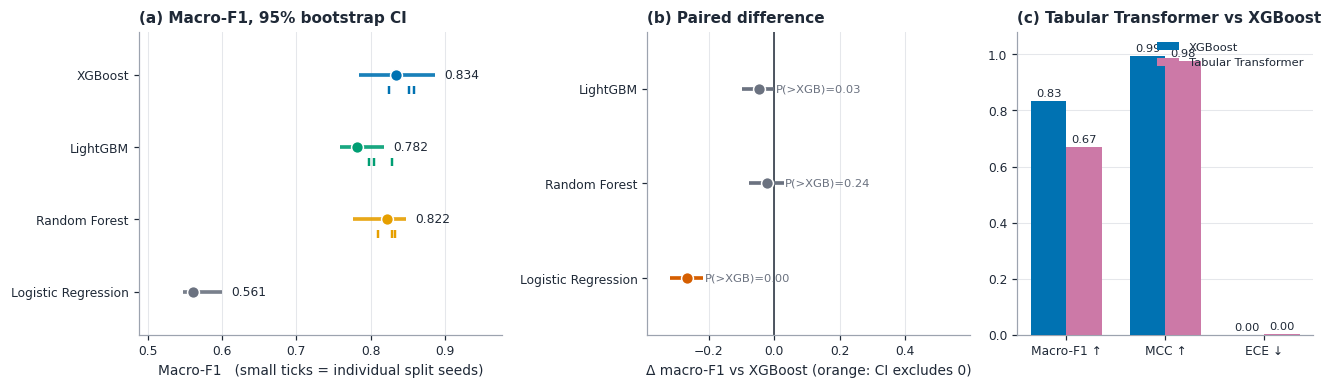

In [72]:
# 22.2  Figure B - model comparison with uncertainty: bootstrap CI, paired differences, seed variability, deep-learning baseline
pb_ = read_csv_safe("v3_paired_bootstrap.csv")
if pb_ is not None:
    ms_runs = read_csv_safe("v3_multiseed_runs.csv"); dl_ = read_csv_safe("v3_transformer_vs_xgb.csv")
    parse_ci = lambda s: [float(x) for x in re.findall(r"[-+]?\d*\.\d+", str(s))[:2]] if isinstance(s, str) and "[" in s else [np.nan, np.nan]
    pb_["lo"], pb_["hi"] = zip(*pb_["Macro-F1 95% CI"].map(parse_ci))
    ncols = 3 if dl_ is not None else 2
    fig, axs = plt.subplots(1, ncols, figsize=(3.6 * ncols + 1.2, 3.5), gridspec_kw=dict(width_ratios=[1.35, 1.2] + ([1.1] if dl_ is not None else [])))
    a = axs[0]; mod_col = {"XGBoost": C["blue"], "LightGBM": C["green"], "Random Forest": C["orange"], "Logistic Regression": C["grey"]}
    yy = np.arange(len(pb_))[::-1]
    for y_, (_, r) in zip(yy, pb_.iterrows()):
        col = mod_col.get(r["Model"], C["purple"]); a.hlines(y_, r["lo"], r["hi"], color=col, lw=2.4, alpha=0.9, zorder=3)
        a.scatter(r["Macro-F1"], y_, s=60, color=col, edgecolor="white", zorder=4)
        a.text(r["hi"] + 0.012, y_, f"{r['Macro-F1']:.3f}", va="center", fontsize=8)
        if ms_runs is not None:
            key = {"XGBoost": "xgb", "LightGBM": "lgbm", "Random Forest": "rf"}.get(r["Model"])
            if key is not None:
                v = ms_runs.loc[ms_runs["model"] == key, "macro_f1"].values
                a.scatter(v, np.full(len(v), y_ - 0.2), s=22, marker="|", color=col, linewidths=1.6, zorder=3)
    a.set_yticks(yy); a.set_yticklabels(pb_["Model"]); a.set_xlabel("Macro-F1"); clean(a, "x"); ptitle(a, "a", "Macro-F1, 95% bootstrap CI")
    a.set_xlim(max(0, np.nanmin(pb_["lo"]) - 0.06), np.nanmax(pb_["hi"]) + 0.09)
    a.set_ylim(-0.6, len(pb_) - 0.4)
    if ms_runs is not None: a.set_xlabel("Macro-F1   (small ticks = individual split seeds)")
    a = axs[1]; d = pb_.iloc[1:].copy()
    d["dm"], d["dlo"], d["dhi"] = zip(*d["Delta F1 vs XGB (paired)"].map(lambda s: (lambda v: (v + [np.nan] * 3)[:3])([float(x) for x in re.findall(r"[-+]?\d*\.\d+", str(s))]) ))
    yy2 = np.arange(len(d))[::-1]; a.axvline(0, color=C["ink"], lw=1)
    for y_, (_, r) in zip(yy2, d.iterrows()):
        sig = not (r["dlo"] <= 0 <= r["dhi"]); col = C["verm"] if sig else C["grey"]
        a.hlines(y_, r["dlo"], r["dhi"], color=col, lw=2.4, zorder=3); a.scatter(r["dm"], y_, s=60, color=col, edgecolor="white", zorder=4)
        a.text(r["dhi"] + 0.004, y_, f"P(>XGB)={r['P(model > XGB)']}", va="center", fontsize=7.5, color=C["grey"])
    a.set_yticks(yy2); a.set_yticklabels(d["Model"]); clean(a, "x"); ptitle(a, "b", "Paired difference")
    lim = np.nanmax(np.abs(d[["dlo", "dhi"]].values)) * 1.15 + 0.02; a.set_xlim(-lim, lim * 1.55)
    a.set_ylim(-0.6, len(d) - 0.4); a.set_xlabel("Δ macro-F1 vs XGBoost (orange: CI excludes 0)")
    if dl_ is not None:
        a = axs[2]; mets = ["Macro-F1", "MCC", "ECE"]; w = 0.36; xx = np.arange(len(mets))
        for j, (_, r) in enumerate(dl_.iterrows()):
            vals = [r[m] for m in mets]; b = a.bar(xx + (j - 0.5) * w, vals, w, color=[C["blue"], C["purple"]][j % 2], label=r["Model"].replace(" (FT-style)", ""), zorder=3)
            for xi, v in zip(xx + (j - 0.5) * w, vals): a.text(xi, v + 0.015, f"{v:.2f}", ha="center", fontsize=7.5)
        a.set_xticks(xx); a.set_xticklabels(["Macro-F1 ↑", "MCC ↑", "ECE ↓"]); a.set_ylim(0, 1.08); clean(a, "y"); ptitle(a, "c", "Tabular Transformer vs XGBoost")
        a.legend(loc="upper right", ncol=1, fontsize=7.5)
    save_pub(fig, "fig_pub_B_model_comparison")

### 22.3 Figure C – confusion matrix and error routes

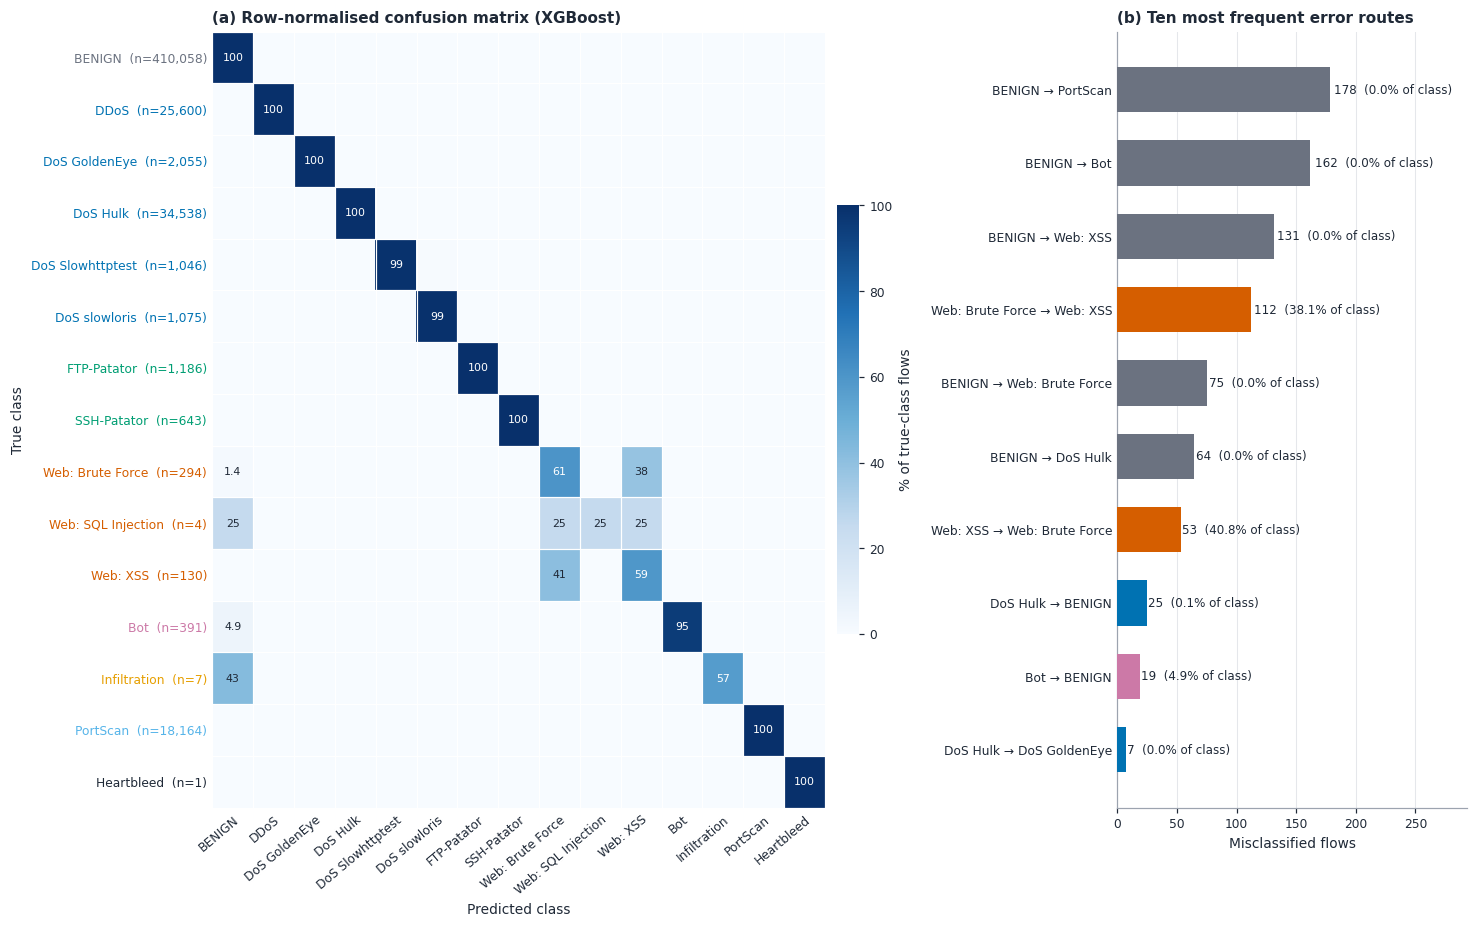

In [73]:
# 22.3  Figure C - row-normalised confusion matrix (family-ordered) + the most frequent error routes
if need("y_test", "y_pred", "target_names"):
    cm_ = cm_fast(np.asarray(y_test), np.asarray(y_pred)); present = [k for k in CLASS_ORDER if cm_[k].sum() > 0]
    cmr = cm_[np.ix_(present, present)]; rown = cmr / np.maximum(cmr.sum(1, keepdims=True), 1) * 100
    nP = len(present); lab = [short(target_names[k]) for k in present]
    off = [(cm_[i, j], i, j) for i in present for j in present if i != j and cm_[i, j] > 0]; off.sort(reverse=True); off = off[:10]
    fig, (a, b) = plt.subplots(1, 2, figsize=(13.4, 0.40 * nP + 2.4), gridspec_kw=dict(width_ratios=[1.75, 1]))
    im = a.imshow(rown, cmap=CMAP_SEQ, vmin=0, vmax=100, aspect="auto")
    for i in range(nP):
        for j in range(nP):
            v = rown[i, j]
            if v >= 0.5: a.text(j, i, f"{v:.0f}" if v >= 9.5 else f"{v:.1f}", ha="center", va="center", fontsize=7.2, color="white" if v > 55 else C["ink"])
    a.set_xticks(range(nP)); a.set_xticklabels(lab, rotation=40, ha="right", rotation_mode="anchor"); a.set_yticks(range(nP))
    a.set_yticklabels([f"{l}  (n={cmr[i].sum():,})" for i, l in enumerate(lab)])
    for t, k in zip(a.get_yticklabels(), present): t.set_color(fam_color(target_names[k]))
    a.set_xlabel("Predicted class"); a.set_ylabel("True class"); a.set_xticks(np.arange(-.5, nP, 1), minor=True); a.set_yticks(np.arange(-.5, nP, 1), minor=True)
    a.grid(which="minor", color="white", lw=0.8); a.tick_params(which="both", length=0)
    for s_ in a.spines.values(): s_.set_visible(False)
    cb = fig.colorbar(im, ax=a, fraction=0.035, pad=0.02); cb.set_label("% of true-class flows"); cb.outline.set_visible(False); ptitle(a, "a", "Row-normalised confusion matrix (XGBoost)")
    yy = np.arange(len(off))[::-1]
    b.barh(yy, [o[0] for o in off], color=[fam_color(target_names[o[1]]) for o in off], height=0.62, zorder=3)
    for y_, o in zip(yy, off): b.text(o[0] * 1.02 + 0.5, y_, f"{o[0]:,}  ({o[0] / cm_[o[1]].sum() * 100:.1f}% of class)", va="center", fontsize=7.8)
    b.set_yticks(yy); b.set_yticklabels([f"{short(target_names[o[1]])} → {short(target_names[o[2]])}" for o in off]); clean(b, "x")
    b.set_xlabel("Misclassified flows"); b.set_xlim(0, max(o[0] for o in off) * 1.65); ptitle(b, "b", "Ten most frequent error routes"); b.tick_params(axis="y", length=0)
    save_pub(fig, "fig_pub_C_confusion")

### 22.4 Figure D – calibration and selective prediction

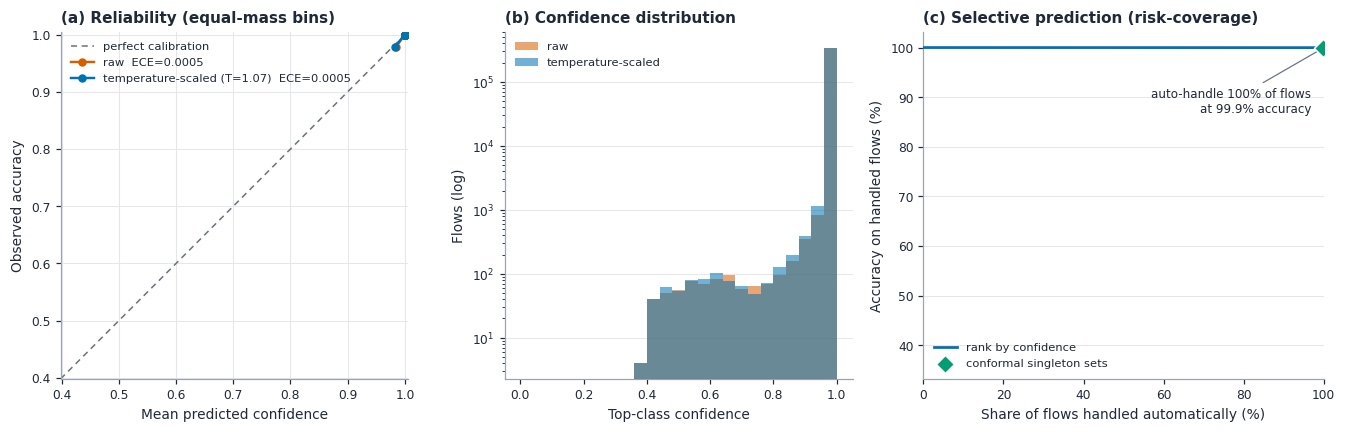

In [74]:
# 22.4  Figure D - probability calibration and selective prediction (does the 'Confidence' field of the analyst report deserve trust?)
if need("P_ev", "P_ev_ts", "y_ev", "T_opt"):
    def reliab(P, y, nb=12):
        conf = P.max(1); cor = (P.argmax(1) == y).astype(float); qs = np.unique(np.quantile(conf, np.linspace(0, 1, nb + 1)))
        idx = np.clip(np.digitize(conf, qs[1:-1]), 0, len(qs) - 2); xs, ys, ns = [], [], []
        for q in range(len(qs) - 1):
            m = idx == q
            if m.sum() >= 5: xs.append(conf[m].mean()); ys.append(cor[m].mean()); ns.append(m.sum())
        return np.array(xs), np.array(ys), np.array(ns)
    fig, axs = plt.subplots(1, 3, figsize=(12.2, 3.9), gridspec_kw=dict(width_ratios=[1.15, 1, 1.15]))
    a = axs[0]; lo_lim = min(0.5, np.min(P_ev.max(1)))
    a.plot([lo_lim, 1], [lo_lim, 1], color=C["grey"], ls=(0, (4, 3)), lw=1, label="perfect calibration")
    for P_, col, nm in [(P_ev, C["verm"], "raw"), (P_ev_ts, C["blue"], f"temperature-scaled (T={T_opt:.2f})")]:
        x_, y_, n_ = reliab(P_, y_ev); a.plot(x_, y_, "-o", color=col, lw=1.6, ms=4.5, label=f"{nm}  ECE={ece_score(P_, y_ev):.4f}", zorder=3)
    a.set_xlim(lo_lim, 1.005); a.set_ylim(lo_lim, 1.005); a.set_aspect("equal", adjustable="box"); a.set_xlabel("Mean predicted confidence"); a.set_ylabel("Observed accuracy")
    a.legend(loc="upper left", fontsize=7.5); clean(a, "both"); ptitle(a, "a", "Reliability (equal-mass bins)")
    a = axs[1]; bins = np.linspace(0, 1, 26)
    a.hist(P_ev.max(1), bins=bins, color=C["verm"], alpha=0.55, label="raw", zorder=3); a.hist(P_ev_ts.max(1), bins=bins, color=C["blue"], alpha=0.55, label="temperature-scaled", zorder=3)
    a.set_yscale("log"); a.set_xlabel("Top-class confidence"); a.set_ylabel("Flows (log)"); a.legend(loc="upper left", fontsize=7.5); clean(a, "y"); ptitle(a, "b", "Confidence distribution")
    a = axs[2]; conf = P_ev_ts.max(1); o = np.argsort(-conf); cor = (P_ev_ts.argmax(1) == y_ev)[o]; cov = np.arange(1, len(o) + 1) / len(o); acc = np.cumsum(cor) / np.arange(1, len(o) + 1)
    step = max(1, len(o) // 600); a.plot(cov[::step] * 100, acc[::step] * 100, color=C["blue"], lw=1.8, label="rank by confidence", zorder=3)
    if need("single", "correct_ev"):
        a.scatter([single.mean() * 100], [correct_ev[single].mean() * 100], s=70, marker="D", color=C["green"], edgecolor="white", zorder=5, label="conformal singleton sets")
        a.annotate(f"auto-handle {single.mean() * 100:.0f}% of flows\nat {correct_ev[single].mean() * 100:.1f}% accuracy", (single.mean() * 100, correct_ev[single].mean() * 100),
                   xytext=(-8, -42), textcoords="offset points", ha="right", fontsize=7.8, arrowprops=dict(arrowstyle="-", color=C["grey"], lw=0.8))
        a.scatter([(~single).mean() * 100], [correct_ev[~single].mean() * 100], s=0)
    a.set_xlabel("Share of flows handled automatically (%)"); a.set_ylabel("Accuracy on handled flows (%)"); a.set_xlim(0, 100); a.legend(loc="lower left", fontsize=7.5); clean(a, "y"); ptitle(a, "c", "Selective prediction (risk-coverage)")
    a.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.0f"))
    save_pub(fig, "fig_pub_D_calibration")

### 22.5 Figure E – conformal coverage and set sizes

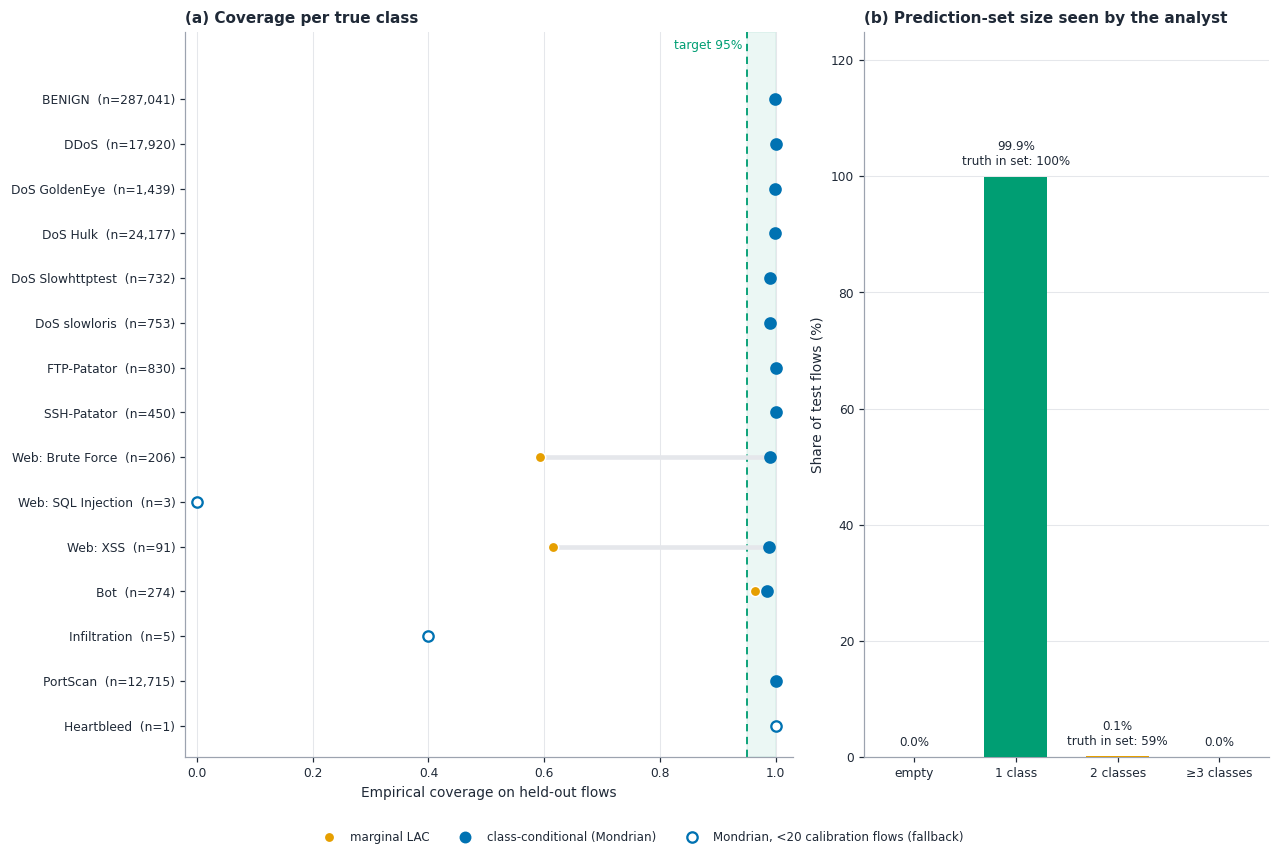

In [75]:
# 22.5  Figure E - conformal prediction: class-wise coverage and what the prediction sets look like to an analyst
pc_ = read_csv_safe("v3_conformal_per_class_coverage.csv", index_col=0)
if pc_ is not None and need("sets_mond", "y_ev", "y_cal", "ALPHA", "min_n", "P_ev"):
    ncal = np.bincount(y_cal, minlength=K); nev = np.bincount(y_ev, minlength=K)
    cls_ = [k for k in CLASS_ORDER if nev[k] > 0][::-1]; names_ = [target_names[k] for k in cls_]
    fig, (a, b) = plt.subplots(1, 2, figsize=(11.6, 0.34 * len(cls_) + 2.6), gridspec_kw=dict(width_ratios=[1.5, 1]))
    yy = np.arange(len(cls_)); a.axvspan(1 - ALPHA, 1.0, color=C["green"], alpha=0.08, zorder=0); a.axvline(1 - ALPHA, color=C["green"], lw=1.2, ls=(0, (4, 3)), zorder=1)
    for y_, k, n_ in zip(yy, cls_, names_):
        m_, c_ = float(pc_.loc[n_, "marginal"]), float(pc_.loc[n_, "class-conditional"]); a.hlines(y_, min(m_, c_), max(m_, c_), color=C["light"], lw=3, zorder=2)
        fb = ncal[k] < min_n
        a.scatter(m_, y_, s=46, color=C["orange"], edgecolor="white", zorder=4, label="marginal LAC" if y_ == yy[0] else None)
        a.scatter(c_, y_, s=46, color="white" if fb else C["blue"], edgecolor=C["blue"], linewidth=1.5, zorder=5, label=None)
    a.scatter([], [], s=46, color=C["blue"], label="class-conditional (Mondrian)"); a.scatter([], [], s=46, color="white", edgecolor=C["blue"], linewidth=1.5, label=f"Mondrian, <{min_n} calibration flows (fallback)")
    a.set_yticks(yy); a.set_yticklabels([f"{short(n_)}  (n={nev[k]:,})" for k, n_ in zip(cls_, names_)]); a.set_xlim(-0.02, 1.03); a.set_xlabel("Empirical coverage on held-out flows"); clean(a, "x")
    a.set_ylim(-0.7, len(cls_) + 0.5); a.text(1 - ALPHA - 0.008, len(cls_) + 0.2, f"target {1 - ALPHA:.0%}", ha="right", va="center", fontsize=8, color=C["green"])
    h_, l_ = a.get_legend_handles_labels(); fig.legend(h_, l_, loc="outside lower center", ncol=3, fontsize=7.8); ptitle(a, "a", "Coverage per true class")
    sz = sets_mond.sum(1); cats = [0, 1, 2, 3]; labs = ["empty", "1 class", "2 classes", "≥3 classes"]
    cnt = [(sz == 0).sum(), (sz == 1).sum(), (sz == 2).sum(), (sz >= 3).sum()]; incl = [np.nan if c == 0 else (sets_mond[(sz == k_ if k_ < 3 else sz >= 3)][np.arange(c), y_ev[(sz == k_ if k_ < 3 else sz >= 3)]].mean()) for k_, c in zip(cats, cnt)]
    cols = [C["grey"], C["green"], C["orange"], C["verm"]]; b.bar(range(4), np.array(cnt) / len(sz) * 100, color=cols, width=0.62, zorder=3)
    for i, (c, v) in enumerate(zip(cnt, incl)):
        b.text(i, c / len(sz) * 100 + 1.5, f"{c / len(sz) * 100:.1f}%" + ("" if np.isnan(v) else f"\ntruth in set: {v * 100:.0f}%"), ha="center", va="bottom", fontsize=7.8)
    b.set_xticks(range(4)); b.set_xticklabels(labs); b.set_ylabel("Share of test flows (%)"); b.set_ylim(0, max(np.array(cnt) / len(sz) * 100) * 1.25); clean(b, "y"); ptitle(b, "b", "Prediction-set size seen by the analyst")
    save_pub(fig, "fig_pub_E_conformal")

### 22.6 Figure F – SOC operating point (alert budget)

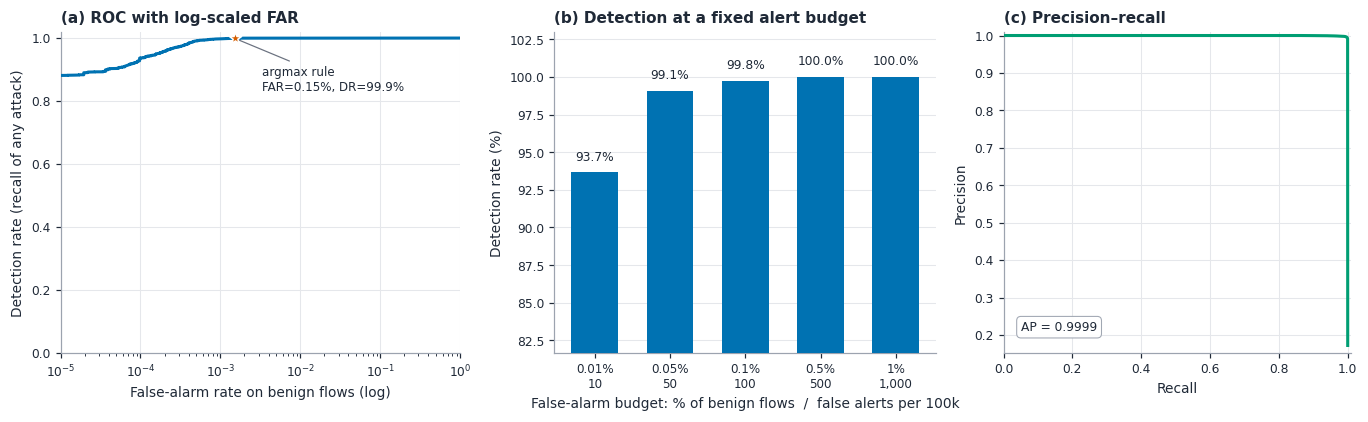

In [76]:
# 22.6  Figure F - SOC operating-point analysis: detection rate at a fixed false-alarm budget (binary attack-vs-benign view)
if need("y_test", "y_proba", "label_map"):
    from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
    ben = label_map["BENIGN"]; s_att = 1.0 - np.asarray(y_proba)[:, ben]; yb = (np.asarray(y_test) != ben).astype(int)
    fpr, tpr, thr = roc_curve(yb, s_att); prec, rec, _ = precision_recall_curve(yb, s_att); ap = average_precision_score(yb, s_att)
    fig, axs = plt.subplots(1, 3, figsize=(12.4, 3.8), gridspec_kw=dict(width_ratios=[1.15, 1.1, 1]))
    a = axs[0]; a.plot(np.maximum(fpr, 1e-6), tpr, color=C["blue"], lw=2, zorder=3); a.set_xscale("log"); a.set_xlim(1e-5, 1); a.set_ylim(0.0, 1.02)
    p_def = np.argmax(np.asarray(y_proba), 1) != ben; fa_d = (p_def & (yb == 0)).sum() / max(1, (yb == 0).sum()); tp_d = (p_def & (yb == 1)).sum() / max(1, yb.sum())
    a.scatter([max(fa_d, 1e-6)], [tp_d], s=70, marker="*", color=C["verm"], edgecolor="white", zorder=5)
    a.annotate(f"argmax rule\nFAR={fa_d * 100:.2f}%, DR={tp_d * 100:.1f}%", (max(fa_d, 1e-6), tp_d), xytext=(18, -34), textcoords="offset points", fontsize=7.8, arrowprops=dict(arrowstyle="-", color=C["grey"], lw=0.8))
    a.set_xlabel("False-alarm rate on benign flows (log)"); a.set_ylabel("Detection rate (recall of any attack)"); clean(a, "both"); ptitle(a, "a", "ROC with log-scaled FAR")
    a = axs[1]; budgets = [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]; dr = [float(np.interp(b_, fpr, tpr)) for b_ in budgets]
    bars = a.bar(range(len(budgets)), np.array(dr) * 100, color=C["blue"], width=0.62, zorder=3)
    for i, (b_, d_) in enumerate(zip(budgets, dr)): a.text(i, d_ * 100 + 0.8, f"{d_ * 100:.1f}%", ha="center", fontsize=8)
    a.set_xticks(range(len(budgets))); a.set_xticklabels([f"{b_ * 100:g}%\n{int(b_ * 1e5):,}" for b_ in budgets], fontsize=7.8)
    a.set_ylim(max(0, min(dr) * 100 - 12), 103); a.set_xlabel("False-alarm budget: % of benign flows  /  false alerts per 100k"); a.set_ylabel("Detection rate (%)"); clean(a, "y"); ptitle(a, "b", "Detection at a fixed alert budget")
    a = axs[2]; a.plot(rec, prec, color=C["green"], lw=2, zorder=3); a.set_xlim(0, 1.01); a.set_ylim(max(0, np.nanmin(prec) - 0.02), 1.01); a.set_xlabel("Recall"); a.set_ylabel("Precision")
    boxlabel(a, f"AP = {ap:.4f}", loc=(0.05, 0.06), ha="left"); clean(a, "both"); ptitle(a, "c", "Precision–recall")
    save_pub(fig, "fig_pub_F_operating_point")

### 22.7 Figure G – explanation audit

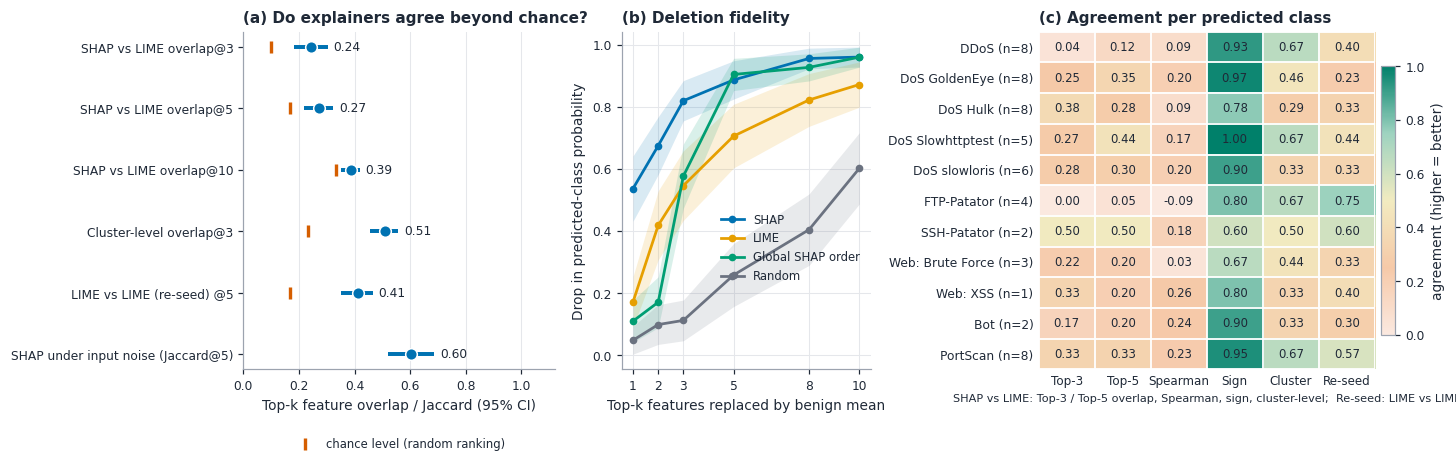

In [77]:
# 22.7  Figure G - explanation audit: agreement vs chance, fidelity curves, per-class consistency
au_ = read_csv_safe("v3_explanation_audit.csv"); pf_ = read_csv_safe("v3_explanation_audit_per_flow.csv")
if au_ is not None and pf_ is not None and need("fid", "KS"):
    fig, axs = plt.subplots(1, 3, figsize=(13.2, 4.2), gridspec_kw=dict(width_ratios=[1.25, 1, 1.35]))
    a = axs[0]; sel = au_[au_["Metric"].str.contains("overlap|stability \\(top-5", regex=True)].reset_index(drop=True)
    lab = [m.replace("SHAP-LIME ", "SHAP vs LIME ").replace("Cluster-level overlap@3 (correlated features merged)", "Cluster-level overlap@3").replace("LIME re-seed overlap@5 (self-consistency)", "LIME vs LIME (re-seed) @5").replace("SHAP noise stability (top-5 Jaccard)", "SHAP under input noise (Jaccard@5)") for m in sel["Metric"]]
    yy = np.arange(len(sel))[::-1]
    for y_, (_, r), l in zip(yy, sel.iterrows(), lab):
        a.hlines(y_, r["CI95_low"], r["CI95_high"], color=C["blue"], lw=2.6, zorder=3); a.scatter(r["Mean"], y_, s=58, color=C["blue"], edgecolor="white", zorder=4)
        if pd.notna(r["Chance"]): a.scatter(r["Chance"], y_, s=60, marker="|", color=C["verm"], linewidths=2.2, zorder=5)
        a.text(min(1.0, r["CI95_high"]) + 0.02, y_, f"{r['Mean']:.2f}", va="center", fontsize=8)
    a.set_yticks(yy); a.set_yticklabels(lab); a.set_xlim(0, 1.12); a.set_xlabel("Top-k feature overlap / Jaccard (95% CI)"); clean(a, "x"); ptitle(a, "a", "Do explainers agree beyond chance?")
    a.scatter([], [], marker="|", s=60, color=C["verm"], linewidths=2.2, label="chance level (random ranking)"); a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), fontsize=7.6)
    a = axs[1]; cm_col = {"SHAP": C["blue"], "LIME": C["orange"], "Global SHAP order": C["green"], "Random": C["grey"]}
    for nm, v in fid.items():
        m_ = v["comp"].mean(1); se = v["comp"].std(1) / np.sqrt(v["comp"].shape[1]); a.fill_between(KS, m_ - 1.96 * se, m_ + 1.96 * se, color=cm_col.get(nm, C["purple"]), alpha=0.15, lw=0, zorder=2)
        a.plot(KS, m_, "-o", color=cm_col.get(nm, C["purple"]), lw=1.8, ms=4, label=nm, zorder=3)
    a.set_xlabel("Top-k features replaced by benign mean"); a.set_ylabel("Drop in predicted-class probability"); a.set_xticks(KS); a.legend(loc="center right", bbox_to_anchor=(1.0, 0.36), fontsize=7.6); clean(a, "both"); ptitle(a, "b", "Deletion fidelity")
    a = axs[2]; cols = [("overlap@3", "Top-3"), ("overlap@5", "Top-5"), ("spearman_abs", "Spearman"), ("sign_agree@5", "Sign"), ("cluster_overlap@3", "Cluster"), ("lime_seed_overlap@5", "Re-seed")]
    G = pf_.groupby("cls")[[c for c, _ in cols]].mean(); G = G.loc[sorted(G.index, key=lambda n: (_family_rank(n), n))]; cnt_ = pf_.groupby("cls").size().reindex(G.index)
    im = a.imshow(G.values, cmap=CMAP_QUAL, vmin=0, vmax=1, aspect="auto")
    for i in range(G.shape[0]):
        for j in range(G.shape[1]): a.text(j, i, "n/a" if pd.isna(G.values[i, j]) else f"{G.values[i, j]:.2f}", ha="center", va="center", fontsize=7.6, color=C["ink"])
    a.set_xticks(range(len(cols))); a.set_xticklabels([l for _, l in cols], fontsize=7.8); a.set_xlabel("SHAP vs LIME: Top-3 / Top-5 overlap, Spearman, sign, cluster-level;  Re-seed: LIME vs LIME", fontsize=7.4); a.set_yticks(range(G.shape[0])); a.set_yticklabels([f"{short(n)} (n={int(c)})" for n, c in zip(G.index, cnt_)])
    a.tick_params(length=0); [s_.set_visible(False) for s_ in a.spines.values()]
    a.set_xticks(np.arange(-.5, len(cols), 1), minor=True); a.set_yticks(np.arange(-.5, G.shape[0], 1), minor=True); a.grid(which="minor", color="white", lw=1.2); a.tick_params(which="minor", length=0)
    fig.colorbar(im, ax=a, fraction=0.04, pad=0.02).set_label("agreement (higher = better)"); a.set_title("(c) Agreement per predicted class", loc="left", pad=6)
    save_pub(fig, "fig_pub_G_explanation_audit")

### 22.8 Figure H – SHAP vs LIME rank disagreement case studies

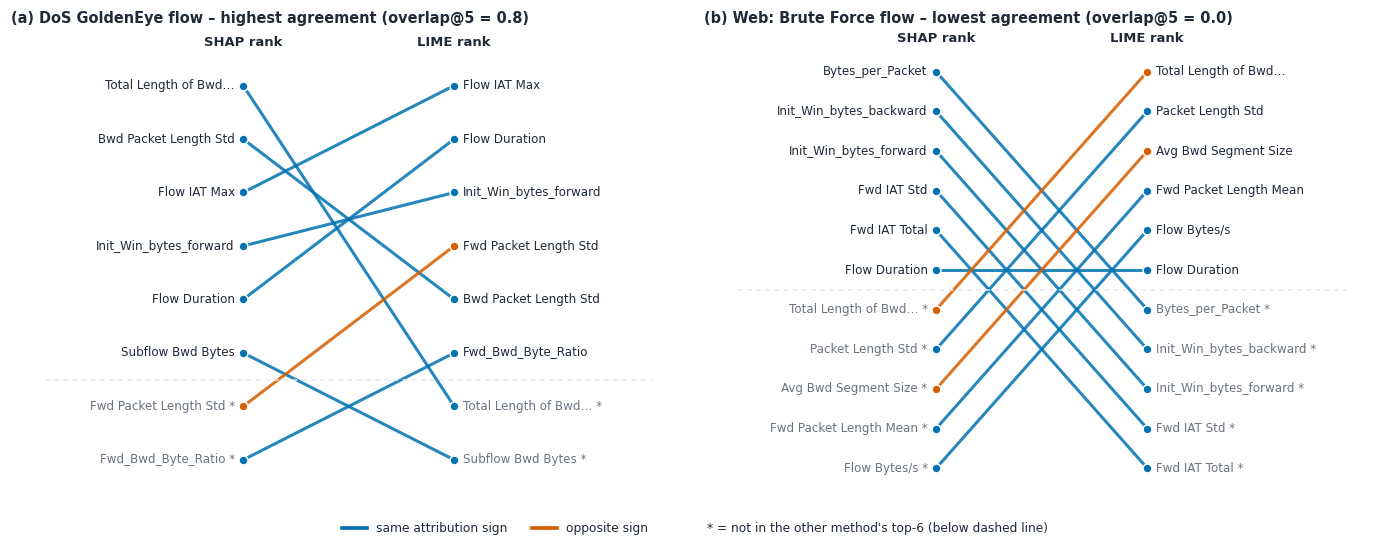

In [78]:
# 22.8  Figure H - where SHAP and LIME disagree: rank slope-charts for the most and least consistent audited flows
if need("sv_f", "lw_f", "NF", "cls_f", "selected_features", "topk"):
    ov5 = np.array([len(topk(sv_f[i], 5) & topk(lw_f[i], 5)) / 5 for i in range(NF)]); cases = [("highest agreement", int(np.argmax(ov5))), ("lowest agreement", int(np.argmin(ov5)))]
    fig, axs = plt.subplots(1, 2, figsize=(12.6, 4.9)); TOP = 6
    for a, (ttl, i) in zip(axs, cases):
        rs_, rl_ = np.argsort(-np.abs(sv_f[i])), np.argsort(-np.abs(lw_f[i])); S, L = list(rs_[:TOP]), list(rl_[:TOP]); feats = list(dict.fromkeys(S + L))
        def slot(f, lst):
            if f in lst: return lst.index(f)
            return TOP + [g for g in feats if g not in lst].index(f)
        for f in feats:
            ys_, yl_ = slot(f, S), slot(f, L); same = np.sign(sv_f[i][f]) == np.sign(lw_f[i][f]); col = C["blue"] if same else C["verm"]
            a.plot([0, 1], [ys_, yl_], color=col, lw=2.0, alpha=0.85, zorder=2, solid_capstyle="round"); a.scatter([0, 1], [ys_, yl_], s=34, color=col, edgecolor="white", zorder=3)
            nm = textwrap.shorten(str(selected_features[f]), 26, placeholder="…")
            a.text(-0.04, ys_, nm + (" *" if f not in S else ""), ha="right", va="center", fontsize=7.8, color=C["ink"] if f in S else C["grey"])
            a.text(1.04, yl_, nm + (" *" if f not in L else ""), ha="left", va="center", fontsize=7.8, color=C["ink"] if f in L else C["grey"])
        nrows = max(len(feats), TOP); a.set_ylim(nrows - 0.4, -1.0); a.set_xlim(-1.1, 2.1); a.axis("off")
        a.axhline(TOP - 0.5, color=C["light"], lw=1, xmin=0.05, xmax=0.95, ls=(0, (3, 3)))
        a.text(0, -0.75, "SHAP rank", ha="center", fontsize=8.6, fontweight="bold"); a.text(1, -0.75, "LIME rank", ha="center", fontsize=8.6, fontweight="bold")
        a.set_title(f"{['(a)', '(b)'][axs.tolist().index(a)]} {short(target_names[int(cls_f[i])])} flow – {ttl} (overlap@5 = {ov5[i]:.1f})", loc="left", fontsize=9.5)
    fig.legend(handles=[plt.Line2D([], [], color=C["blue"], lw=2.4, label="same attribution sign"), plt.Line2D([], [], color=C["verm"], lw=2.4, label="opposite sign"), plt.Line2D([], [], color="none", label="* = not in the other method's top-6 (below dashed line)")], loc="outside lower center", ncol=3)
    save_pub(fig, "fig_pub_H_disagreement_cases")

### 22.9 Figure I – analyst report card (the required pipeline)

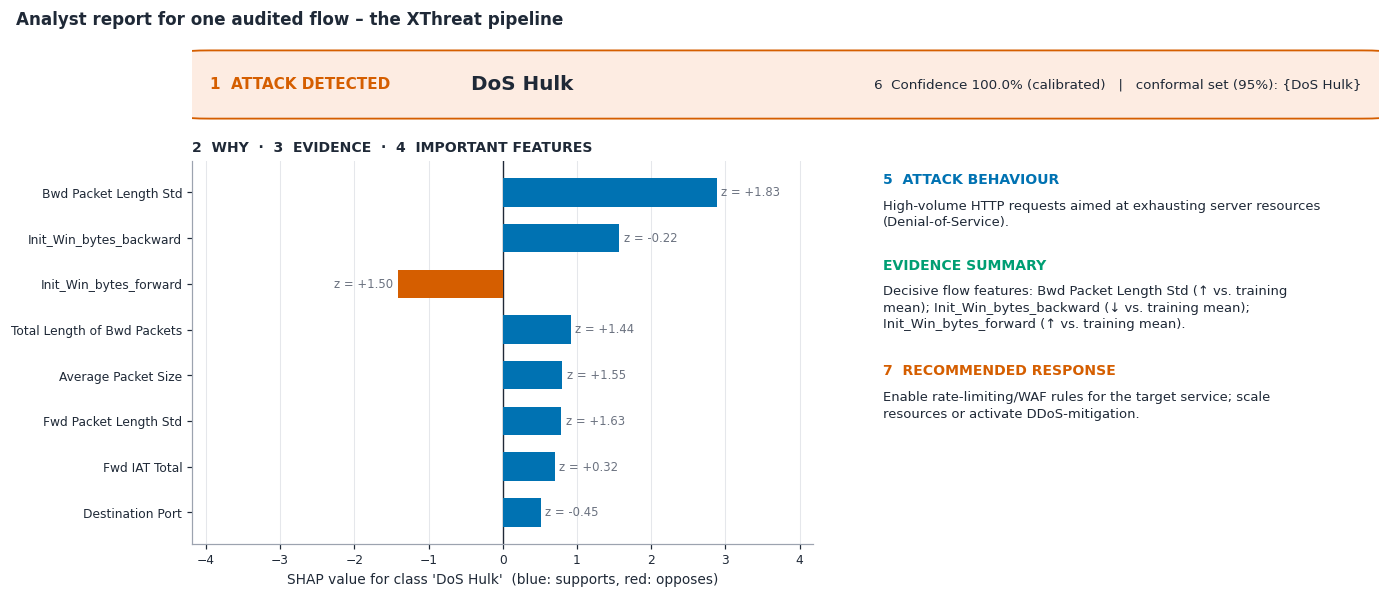

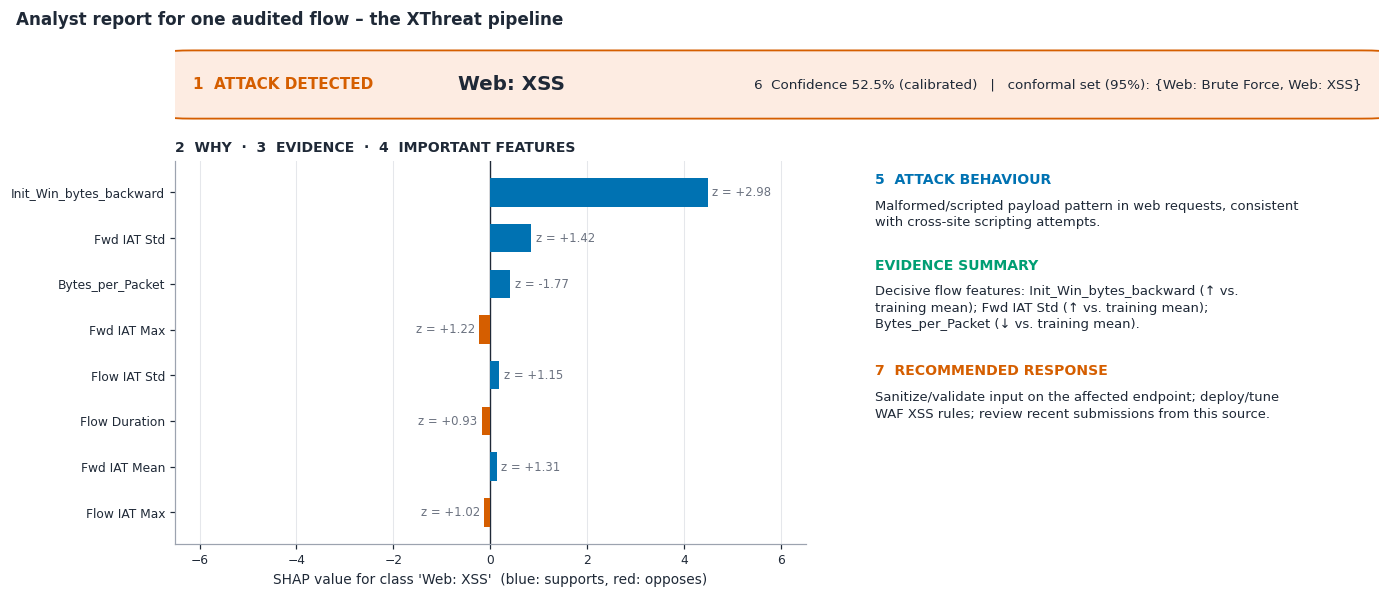

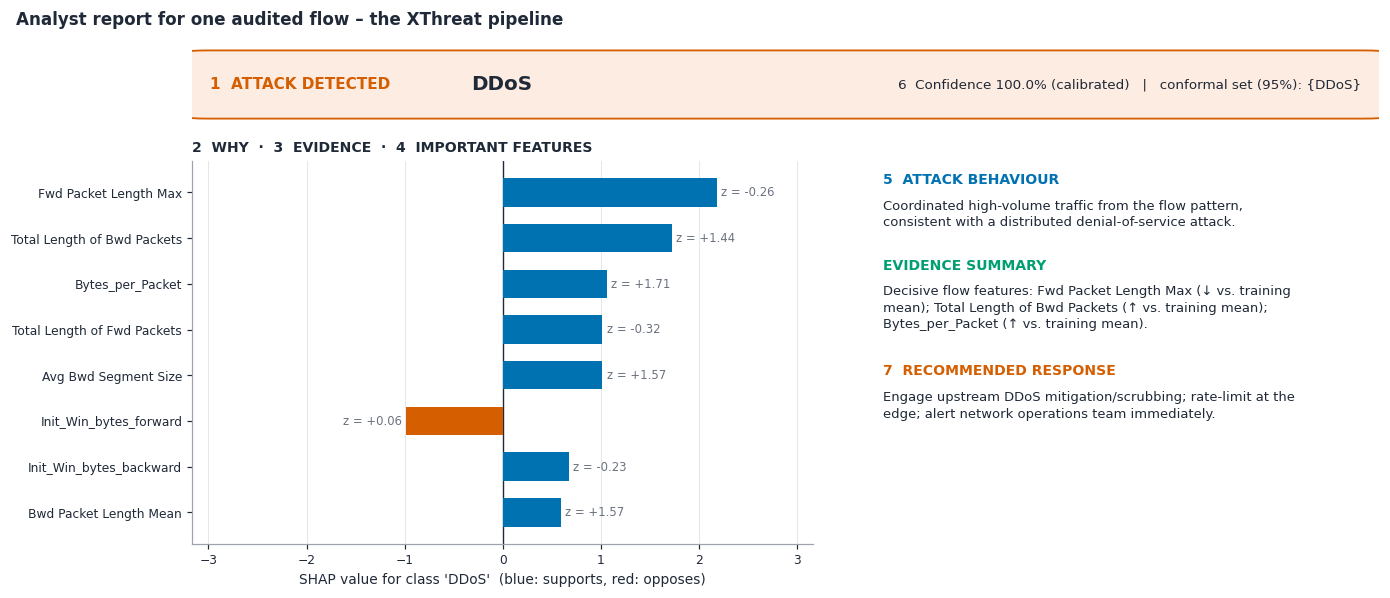

In [79]:
# 22.9  Figure I - the required analyst pipeline for one flow: Attack -> Why -> Evidence -> Features -> Behaviour -> Confidence -> Response
if need("sv_f", "Xf", "cls_f", "NF", "selected_features", "target_names", "ATTACK_BEHAVIOR", "RECOMMENDED_RESPONSE", "model", "bg", "T_opt", "q_cls", "apply_temperature"):
    def analyst_card(i, name):
        k = int(cls_f[i]); sv = sv_f[i]; o = np.argsort(-np.abs(sv))[:8][::-1]; x = Xf.values[i]
        P_raw = model.predict_proba(Xf.iloc[[i]])[0]; conf = float(apply_temperature(P_raw[None, :], T_opt)[0, k]); pset = [target_names[j] for j in range(K) if 1 - P_raw[j] <= q_cls[j]]
        fig = plt.figure(figsize=(12.6, 5.4)); gs = fig.add_gridspec(2, 2, height_ratios=[0.2, 1], width_ratios=[1.25, 1], hspace=0.06, wspace=0.05)
        ax0 = fig.add_subplot(gs[0, :]); ax0.axis("off"); ax0.set_xlim(0, 1); ax0.set_ylim(0, 1)
        ax0.add_patch(FancyBboxPatch((0, 0.06), 1, 0.88, boxstyle="round,pad=0.005,rounding_size=0.02", fc="#FDECE2", ec=C["verm"], lw=1.2))
        ax0.text(0.015, 0.5, "1  ATTACK DETECTED", fontsize=10, fontweight="bold", color=C["verm"], va="center")
        ax0.text(0.235, 0.5, short(target_names[k]), fontsize=13, fontweight="bold", va="center")
        ax0.text(0.985, 0.5, f"6  Confidence {conf * 100:.1f}% (calibrated)   |   conformal set (95%): {{{', '.join(short(p) for p in pset)}}}", fontsize=8.8, ha="right", va="center")
        a = fig.add_subplot(gs[1, 0]); cols = [C["blue"] if v > 0 else C["verm"] for v in sv[o]]
        a.barh(range(len(o)), sv[o], color=cols, height=0.62, zorder=3); a.axvline(0, color=C["ink"], lw=0.9)
        lim = np.abs(sv[o]).max() * 1.0
        for r_, f in enumerate(o):
            z = x[f]; ha_, xo = ("left", 0.02 * lim) if sv[f] >= 0 else ("right", -0.02 * lim)
            a.text(sv[f] + xo, r_, f"z = {z:+.2f}", va="center", ha=ha_, fontsize=7.6, color=C["grey"])
        a.set_yticks(range(len(o))); a.set_yticklabels([textwrap.shorten(str(selected_features[f]), 30, placeholder="…") for f in o]); a.set_xlim(-lim * 1.45, lim * 1.45)
        a.set_xlabel(f"SHAP value for class '{short(target_names[k])}'  (blue: supports, red: opposes)"); clean(a, "x"); a.set_title("2  WHY  ·  3  EVIDENCE  ·  4  IMPORTANT FEATURES", loc="left", fontsize=9.2, pad=6)
        t = fig.add_subplot(gs[1, 1]); t.axis("off"); t.set_xlim(0, 1); t.set_ylim(0, 1); yy = 0.97
        def block(head, body, col, yy, width=62):
            t.text(0, yy, head, fontsize=9.2, fontweight="bold", color=col, va="top"); yy -= 0.07; lines = textwrap.wrap(body, width)
            t.text(0.0, yy, "\n".join(lines), fontsize=8.6, va="top", linespacing=1.35); return yy - 0.052 * len(lines) - 0.05
        top3 = [str(selected_features[f]) for f in np.argsort(-np.abs(sv))[:3]]
        yy = block("5  ATTACK BEHAVIOUR", ATTACK_BEHAVIOR.get(target_names[k], "No template for this class."), C["blue"], yy)
        yy = block("EVIDENCE SUMMARY", "Decisive flow features: " + "; ".join(f"{n} ({'↑' if Xf.values[i][list(selected_features).index(n)] > 0 else '↓'} vs. training mean)" for n in top3) + ".", C["green"], yy)
        yy = block("7  RECOMMENDED RESPONSE", RECOMMENDED_RESPONSE.get(target_names[k], "Escalate to an analyst."), C["verm"], yy)
        fig.suptitle("Analyst report for one audited flow – the XThreat pipeline", x=0.01, ha="left", fontsize=11, fontweight="bold")
        save_pub(fig, name)
    pick = []; seen = set()
    for i in range(NF):
        if int(cls_f[i]) not in seen: seen.add(int(cls_f[i])); pick.append(i)
    for n_, i in enumerate(pick[:3]): analyst_card(i, f"fig_pub_I_analyst_card_{n_ + 1}")

### 22.10 Figures J and K – counterfactual quality and protocol robustness

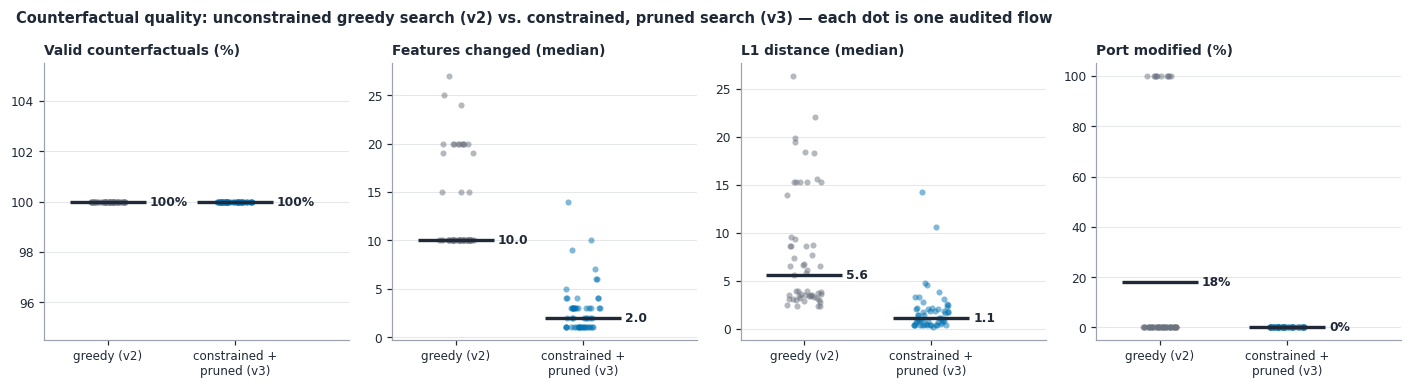

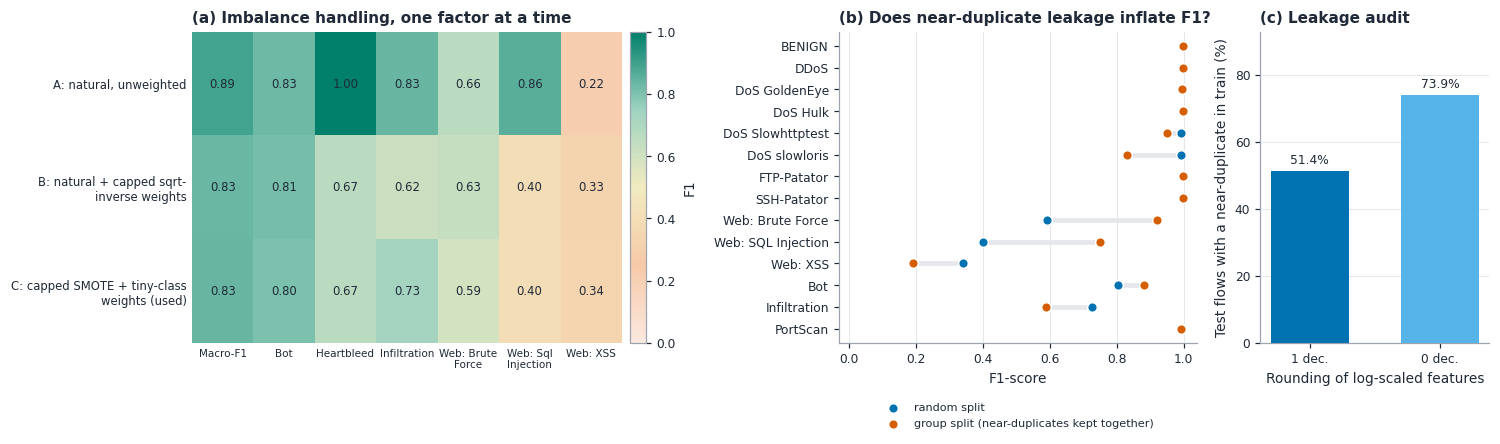

In [80]:
# 22.10  Figure J - constrained counterfactuals; Figure K - robustness of the protocol (imbalance, split type, near-duplicates)
cf_ = read_csv_safe("v3_counterfactual_per_flow.csv")
if cf_ is not None:
    meths = list(cf_["method"].unique()); mc = {meths[0]: C["grey"], meths[-1]: C["blue"]}
    mets = [("valid", "Valid counterfactuals (%)", 100, "rate"), ("sparsity", "Features changed (median)", 1, "med"), ("L1", "L1 distance (median)", 1, "med"), ("port_changed", "Port modified (%)", 100, "rate")]
    fig, axs = plt.subplots(1, 4, figsize=(12.8, 3.5)); rs_ = np.random.RandomState(0)
    for a, (m, ttl, mult, kind) in zip(axs, mets):
        for j, me in enumerate(meths):
            v = cf_.loc[cf_["method"] == me, m].astype(float).values; ctr = (v.mean() if kind == "rate" else np.median(v)) * mult
            a.scatter(j + rs_.uniform(-0.14, 0.14, len(v)), v * mult, s=16, color=mc.get(me, C["purple"]), alpha=0.5, zorder=2, linewidths=0)
            a.hlines(ctr, j - 0.3, j + 0.3, color=C["ink"], lw=2.2, zorder=4); a.text(j + 0.33, ctr, f"{ctr:.1f}" if kind == "med" else f"{ctr:.0f}%", ha="left", va="center", fontsize=8, fontweight="bold", color=C["ink"], zorder=5)
        a.set_xticks(range(len(meths))); a.set_xticklabels([textwrap.fill(me.replace(" (v2, unconstrained)", "\n(v2)").replace(" (v3)", "\n(v3)"), 16) for me in meths], fontsize=7.8)
        a.set_title(ttl, loc="left", fontsize=9); a.set_xlim(-0.5, len(meths) - 0.1); clean(a, "y")
    fig.suptitle("Counterfactual quality: unconstrained greedy search (v2) vs. constrained, pruned search (v3) — each dot is one audited flow", x=0.01, ha="left", fontsize=9.6, fontweight="bold")
    save_pub(fig, "fig_pub_J_counterfactual")

imb_ = read_csv_safe("v3_imbalance_ablation.csv"); gs_ = read_csv_safe("v3_group_split.csv"); nd_ = read_csv_safe("v3_near_duplicate_leakage.csv", index_col=0)
if imb_ is not None or gs_ is not None:
    fig, axs = plt.subplots(1, 3, figsize=(13.6, 4.0), gridspec_kw=dict(width_ratios=[1.5, 1.25, 0.8]))
    a = axs[0]
    if imb_ is not None:
        M = imb_.drop(columns=["Accuracy", "MCC"], errors="ignore").set_index("Variant"); M.columns = [c.replace("F1 ", "").replace("Web Attack - ", "Web: ").replace("Web Attack \x96 ", "Web: ") for c in M.columns]
        im = a.imshow(M.values.astype(float), cmap=CMAP_QUAL, vmin=0, vmax=1, aspect="auto")
        for i in range(M.shape[0]):
            for j in range(M.shape[1]): a.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=7.6)
        a.set_xticks(range(M.shape[1])); a.set_xticklabels([textwrap.fill(c, 10, break_long_words=False) for c in M.columns], fontsize=6.8); a.set_yticks(range(M.shape[0])); a.set_yticklabels([textwrap.fill(v, 30) for v in M.index], fontsize=7.6)
        a.tick_params(length=0); [s_.set_visible(False) for s_ in a.spines.values()]; fig.colorbar(im, ax=a, fraction=0.04, pad=0.02).set_label("F1")
        a.set_title("(a) Imbalance handling, one factor at a time", loc="left", pad=6)
    a = axs[1]
    if gs_ is not None:
        g = gs_[gs_["test_support_group"] > 0].copy(); g["o"] = g["class"].map(lambda n: (_family_rank(n), n)); g = g.sort_values("o", ascending=False).reset_index(drop=True); yy = np.arange(len(g))
        a.hlines(yy, g["F1_random_split"], g["F1_group_split"], color=C["light"], lw=3, zorder=2); a.scatter(g["F1_random_split"], yy, s=40, color=C["blue"], label="random split", zorder=3, edgecolor="white")
        a.scatter(g["F1_group_split"], yy, s=40, color=C["verm"], label="group split (near-duplicates kept together)", zorder=4, edgecolor="white")
        a.set_yticks(yy); a.set_yticklabels([short(n) for n in g["class"]]); a.set_xlim(-0.03, 1.04); a.set_xlabel("F1-score"); a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=7.4); clean(a, "x"); ptitle(a, "b", "Does near-duplicate leakage inflate F1?")
    a = axs[2]
    if nd_ is not None:
        r = nd_.iloc[0].astype(float); a.bar(range(len(r)), r.values * 100, color=[C["blue"], C["sky"], C["orange"], C["verm"]][:len(r)], width=0.6, zorder=3)
        for i, v in enumerate(r.values * 100): a.text(i, v + max(r.values * 100) * 0.03 + 0.05, f"{v:.1f}%", ha="center", fontsize=8)
        a.set_xticks(range(len(r))); a.set_xticklabels([f"{c} dec." for c in r.index]); a.set_ylabel("Test flows with a near-duplicate in train (%)"); a.set_ylim(0, max(r.values * 100) * 1.25 + 0.5); a.set_xlabel("Rounding of log-scaled features"); clean(a, "y"); ptitle(a, "c", "Leakage audit")
    save_pub(fig, "fig_pub_K_robustness")

### 22.11 Figures L and M – cross-dataset transfer and computational cost

  skipped (v3_cross_dataset.csv not found - run its section first)
  skipped (v3_cross_dataset_per_class_recall.csv not found - run its section first)
                          stage  ms_per_flow  flows_per_second
            Detection (XGBoost)        0.010        101453.782
           TreeSHAP explanation        3.713           269.360
LIME explanation (1500 samples)       61.536            16.251


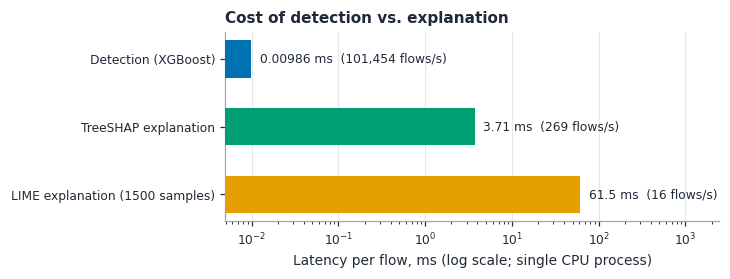

In [81]:
# 22.11  Figure L - cross-dataset generalisation (CIC-IDS2017 -> CSE-CIC-IDS2018, no retraining); Table - computational cost of detection and explanation
cd_ = read_csv_safe("v3_cross_dataset.csv"); pr_ = read_csv_safe("v3_cross_dataset_per_class_recall.csv", index_col=0)
if cd_ is not None and pr_ is not None and need("y_test", "y_pred"):
    rec_in = pd.Series(scores_from_cm(cm_fast(np.asarray(y_test), np.asarray(y_pred)))["recall"], index=target_names)
    cls_ = [n for n in sorted(pr_.index, key=lambda n: (_family_rank(n), n)) if n in rec_in.index][::-1]; yy = np.arange(len(cls_))
    fig, (a, b) = plt.subplots(1, 2, figsize=(11.8, 0.34 * len(cls_) + 2.4), gridspec_kw=dict(width_ratios=[1.5, 1]))
    c1, c2 = pr_.columns[0], pr_.columns[-1]; a.hlines(yy, [pr_.loc[n, c1] for n in cls_], [rec_in[n] for n in cls_], color=C["light"], lw=3.2, zorder=2)
    a.scatter([rec_in[n] for n in cls_], yy, s=46, color=C["grey"], label="in-domain: CIC-IDS2017 test", zorder=3, edgecolor="white")
    a.scatter([pr_.loc[n, c1] for n in cls_], yy, s=52, color=C["blue"], label="CSE-CIC-IDS2018, all features", zorder=4, edgecolor="white")
    a.scatter([pr_.loc[n, c2] for n in cls_], yy, s=52, marker="D", color=C["verm"], label="CSE-CIC-IDS2018, port features removed", zorder=4, edgecolor="white")
    a.set_yticks(yy); a.set_yticklabels([short(n) for n in cls_]); a.set_xlim(-0.03, 1.05); a.set_xlabel("Per-class recall"); clean(a, "x"); h_, l_ = a.get_legend_handles_labels(); fig.legend(h_, l_, loc="outside lower center", ncol=3, fontsize=7.8); ptitle(a, "a", "Train 2017 → test 2018, per class")
    mets = [("macro_f1", "Macro-F1"), ("binary_F1", "Binary F1"), ("MCC", "MCC"), ("false_alarm_rate", "False-alarm rate")]; w = 0.38; xx = np.arange(len(mets))
    for j, (_, r) in enumerate(cd_.iterrows()):
        vals = [r[m] for m, _ in mets]; b.bar(xx + (j - 0.5) * w, vals, w, color=[C["blue"], C["verm"]][j % 2], zorder=3, label=r["setting"])
        for xi, v in zip(xx + (j - 0.5) * w, vals): b.text(xi, v + 0.015, f"{v:.2f}", ha="center", fontsize=7.6)
    b.set_xticks(xx); b.set_xticklabels([l for _, l in mets], fontsize=8); b.set_ylim(0, 1.1); clean(b, "y"); b.legend(loc="upper right", fontsize=7.2); b.set_ylim(0, 1.25); ptitle(b, "b", "Aggregate transfer metrics")
    save_pub(fig, "fig_pub_L_cross_dataset")

# Computational cost (deployability argument)
if need("model", "X_test_fs", "explainer", "Xf", "NF", "selected_features", "lime2") if "lime2" in globals() else False:
    def tm(fn, rep=3):
        t = []; 
        for _ in range(rep): t0 = time.perf_counter(); fn(); t.append(time.perf_counter() - t0)
        return float(np.median(t))
    Xs_ = X_test_fs.iloc[:20_000]; t_pred = tm(lambda: model.predict_proba(Xs_)) / len(Xs_) * 1e3
    t_shap = tm(lambda: explainer.shap_values(Xf.iloc[:min(NF, 20)]), 2) / min(NF, 20) * 1e3
    t_lime = tm(lambda: lime2.explain_instance(Xf.values[0], model.predict_proba, num_features=10, num_samples=LIME_SAMPLES), 2) * 1e3
    cost = pd.DataFrame({"stage": ["Detection (XGBoost)", "TreeSHAP explanation", f"LIME explanation ({LIME_SAMPLES} samples)"], "ms_per_flow": [t_pred, t_shap, t_lime]}); cost["flows_per_second"] = 1e3 / cost["ms_per_flow"]
    print(cost.round(3).to_string(index=False)); cost.to_csv(os.path.join(FIG_DIR, "v3_computational_cost.csv"), index=False)
    fig, a = plt.subplots(figsize=(6.6, 2.5)); yy = np.arange(3)[::-1]; a.barh(yy, cost["ms_per_flow"], color=[C["blue"], C["green"], C["orange"]], height=0.55, zorder=3); a.set_xscale("log")
    for y_, (_, r) in zip(yy, cost.iterrows()): a.text(r["ms_per_flow"] * 1.25, y_, f"{r['ms_per_flow']:.3g} ms  ({r['flows_per_second']:,.0f} flows/s)", va="center", fontsize=8)
    a.set_yticks(yy); a.set_yticklabels(cost["stage"]); a.set_xlim(cost["ms_per_flow"].min() * 0.5, cost["ms_per_flow"].max() * 40); a.set_xlabel("Latency per flow, ms (log scale; single CPU process)"); clean(a, "x"); ptitle(a, "", "Cost of detection vs. explanation")
    a.set_title("Cost of detection vs. explanation", loc="left"); save_pub(fig, "fig_pub_M_cost")